# **🏛️ Reto 01: Expected Credit Loss (ECL) de una Cartera de Préstamos**
### **OUTLIERS IN DATA · Modelización de Riesgo de Crédito (Lending Club)**

El Comité de Riesgos nos pide estimar la **pérdida esperada (ECL, *Expected Credit Loss*)** de una nueva cartera de préstamos personales de Lending Club. Estos resultados se utilizarán para dotar **provisiones** y serán validados por el regulador, lo que plantea dos fuerzas en sentidos opuestos:

- **Ahorrar capital**: cuanto más baja sea la provisión derivada del ECL total, mayor liquidez disponible tendrá el banco para su actividad.
- **Ser conservadores**: si nos quedamos cortos en la provisión, el regulador nos impondrá sanciones.

Traducido a las **reglas de evaluación del reto**:

1. **Restricción 1 (Agregada):** El **ECL total** estimado tiene que ser estrictamente **mayor** que la pérdida real total de la cartera.
2. **Restricción 2 (Individual):** Como máximo un **10% de los préstamos** puede tener un ECL estimado por debajo de su pérdida real observada.
3. **Métricas ganadoras:** Cumpliendo ambas restricciones, gana el **ECL total más bajo** y, en la segunda categoría, la mayor **precisión préstamo a préstamo** (**MAE** y **MAPE**).

La pérdida esperada de cada préstamo $j$ se descompone en tres piezas fundamentales:

$$ECL_j = PD_j \times LGD_j \times EAD_j$$

| Pieza | Pregunta que responde | Cómo la vamos a estimar | Variables permitidas (Inputs) |
|---|---|---|---|
| **PD** (*Probability of Default*) | ¿Qué probabilidad hay de que impague? | Modelo de clasificación con todos los préstamos | Solo **originación** |
| **EAD** (*Exposure at Default*) | Si impaga, ¿cuánto nos debe en ese momento? | Modelo de regresión (`cross_entropy`) sobre `%EAD` con los impagados | Solo **originación** |
| **LGD** (*Loss Given Default*) | De lo que nos debe, ¿qué % perdemos de verdad? | Modelo de regresión sobre los impagados con `EAD >= 1 $` | Solo **originación** |

> ⚠️ **Regla de Oro Anti-Fuga (*Zero Data Leakage*):** Las variables de desempeño post-concesión (`princ_rec`, `interest_rec`, `late_fees_rec`, `paym_rec_for_tot_amnt_fund`, `remaining_princ_for_tot_amnt_fund`) **NO pueden ser *inputs* de ningún modelo (ni PD, ni EAD, ni LGD)**, porque en `test` predecimos préstamos nuevos de los que aún no conocemos ningún pago. Solo sirven para **reconstruir la pérdida real observada** (los *targets* de EAD y LGD). La variable `grade` también queda excluida por las reglas del reto.

## **📦 Semana 1 · Recepción de la cartera y cimientos anti-fuga**

### **1.1 ⚙️ Setup y CONFIG: el panel de control del reto**


En esta primera celda preparamos el entorno de trabajo. Por un lado importamos las librerías que usaremos en todo el notebook: `numpy` y `pandas` para el manejo de datos, `matplotlib` y `seaborn` para los gráficos y `train_test_split` para partir la muestra. También silenciamos los avisos (`warnings`) para mantener el notebook limpio.

Por otro lado definimos el **CONFIG del proyecto**: un bloque con los seis parámetros que controlan todo (la semilla `SEED`, el identificador del dataset en Kaggle, los nombres de los dos ficheros, el nombre de la variable objetivo y el tamaño de la muestra de test). Las reglas del reto dicen que cuando se publique la semilla oficial solo podremos cambiar una variable: gracias a este CONFIG, esa variable vive aquí y en ningún otro sitio.

Por último, todo el notebook depende de **una sola semilla**, `SEED = 1710` (la semilla oficial del reto), que controla la partición de la cartera (`train`, `val`, `test`), la validación cruzada, el *target encoding out-of-fold*, el *bootstrap* y la aleatoriedad de los modelos. Para repetir el ejercicio con cualquier otra partición basta con cambiar `SEED` aquí y ejecutar el notebook de arriba abajo.

In [ ]:
# --- CONFIG: único panel de control del proyecto ---
SEED        = 1710                                      # semilla oficial del reto (reproducibilidad)
TEST_SIZE   = 0.20                                      # 20% de la cartera reservado para test (caja fuerte)
VAL_SIZE    = 0.20                                      # 20% de lo que queda (16% del total), para validación
DATASET_ID  = "db0boy/lending-club-loan-data-cleared"   # owner/slug del repositorio en Kaggle
FILE_X      = "X.csv"                                   # fichero con las variables predictoras
FILE_TARGET = "target.csv"                              # fichero con la variable objetivo y
TARGET_COL  = "y"                                       # nombre de la columna objetivo (1 = impago / default)

# --- Librerías generales del proyecto ---
import os                                               # interacción con el sistema operativo y rutas
import numpy as np                                      # cálculo numérico vectorizado y álgebra lineal
import pandas as pd                                     # manipulación y estructuración de DataFrames
import matplotlib.pyplot as plt                         # motor base de visualización gráfica
import seaborn as sns                                   # gráficos estadísticos de alto nivel

from sklearn.model_selection import train_test_split, KFold, ParameterSampler # particiones y validación cruzada
from sklearn.preprocessing import StandardScaler        # estandarización z-score de variables numéricas
from sklearn.linear_model import LogisticRegression     # modelo benchmark de regresión logística
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, mean_absolute_error # métricas de evaluación
import lightgbm as lgb                                  # algoritmo gradient boosting basado en árboles de decisión

import warnings                                         # gestión y supresión de avisos del sistema
warnings.filterwarnings("ignore")                       # silenciar warnings para mantener la salida limpia

# --- Reproducibilidad y estética de visualización ---
np.random.seed(SEED)                                    # fijar semilla pseudoaleatoria de NumPy
sns.set_theme(style="whitegrid", palette="muted")       # estilo visual estándar con rejilla suave
pd.set_option("display.max_columns", 60)                # mostrar hasta 60 columnas sin truncar
pd.set_option("display.float_format", lambda x: f"{x:,.4f}") # formato flotante con separador de miles y 4 decimales
plt.rcParams["figure.figsize"] = (11, 4)                # ancho y alto por defecto para gráficos
plt.rcParams["axes.grid"] = True                        # activar rejilla por defecto en los ejes
plt.rcParams["grid.alpha"] = 0.3                        # transparencia tenue para no sobrecargar el gráfico

print(f"✅ Librerías cargadas, SEED = {SEED} fijada y CONFIG definido.")

/home/jaume/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-bnofk62w because there was an issue with the default path (/home/jaume/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


✅ Librerías cargadas, SEED = 1710 fijada y CONFIG definido.


### **1.2 📥 Carga de datos desde Kaggle sin salir del notebook**


Tenemos dos ficheros: `X.csv`, con las 45 variables del dataset, y `target.csv`, con la columna `y` (`1` = impago). Si los ficheros no están en el directorio local, los cargamos automáticamente desde la caché/descarga de `kagglehub`. No hay columna de identificador: la fila $k$ de `X.csv` corresponde a la fila $k$ de `target.csv`, por lo que verificamos que tengan exactamente la misma longitud y los unimos por posición.

In [ ]:
# --- Carga de X.csv y target.csv (local, caché de kagglehub o descarga) ---
# Ruta local por defecto en la caché de kagglehub para evitar descargas redundantes
_cache_dir = os.path.expanduser(f"~/.cache/kagglehub/datasets/{DATASET_ID}/versions/2")

if os.path.exists(FILE_X) and os.path.exists(FILE_TARGET):
    X = pd.read_csv(FILE_X)                             # lectura directa si los CSV ya están en el directorio de trabajo
    target = pd.read_csv(FILE_TARGET)                   # lectura del vector objetivo en local
elif os.path.exists(os.path.join(_cache_dir, FILE_X)):
    X = pd.read_csv(os.path.join(_cache_dir, FILE_X))   # lectura desde la carpeta de caché ya descargada
    target = pd.read_csv(os.path.join(_cache_dir, FILE_TARGET)) # lectura del target desde la caché
else:
    import kagglehub                                    # librería oficial para descargar datasets de Kaggle
    from kagglehub import KaggleDatasetAdapter         # adaptador de formato de salida (pandas DataFrame)
    X = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, DATASET_ID, FILE_X)          # descarga remota de features
    target = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, DATASET_ID, FILE_TARGET) # descarga remota de target

# Comprobamos dimensiones de los dos datasets para garantizar alineación fila a fila
assert len(X) == len(target), "X y target deberían tener las mismas filas"

# Construcción del DataFrame maestro unificando variables predictoras y target
df = X.copy()                                           # copia defensiva para preservar el objeto original
df[TARGET_COL] = target[TARGET_COL].values              # anexar columna target 'y' alineada por índice posicional
del X, target                                           # liberar memoria RAM eliminando dataframes temporales

print(f"✅ Número de préstamos: {df.shape[0]:,} | Columnas (número de variables): {df.shape[1]}")
print(f"🎯 Tasa de impago global: {df[TARGET_COL].mean():.2%}")
display(df.head())                                      # vista previa de las primeras 5 filas

✅ Número de préstamos: 2,139,643 | Columnas (número de variables): 46
🎯 Tasa de impago global: 13.07%


,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,y
0,2500,13.5600,84.9200,C1,Chef,10+ years,RENT,"55,000.0000",Not Verified,debt_consolidation,NY,18.2400,0,1,NaN,9,1,4341,10.3000,34,w,"2,386.0200",167.0200,113.9800,53.0400,0.0000,2.0000,1.0000,2.0000,2.0000,2.0000,7.0000,"2,137.0000",28.0000,1.0000,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001,0
1,30000,18.9400,777.2300,D2,Postmaster,10+ years,MORTGAGE,"90,000.0000",Source Verified,debt_consolidation,LA,26.5200,0,0,71.0000,13,1,12315,24.2000,44,w,"29,387.7500","1,507.1100",612.2500,894.8600,0.0000,4.0000,2.0000,3.0000,3.0000,4.0000,5.0000,998.0000,57.0000,2.0000,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987,0
2,5000,17.9700,180.6900,D1,Administrative,6 years,MORTGAGE,"59,280.0000",Source Verified,debt_consolidation,MI,10.5100,0,0,NaN,8,0,4599,19.1000,13,w,"4,787.2100",353.8900,212.7900,141.1000,0.0000,0.0000,0.0000,2.0000,14.0000,0.0000,2.0000,0.0000,35.0000,1.0000,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011,0
3,4000,18.9400,146.5100,D2,IT Supervisor,10+ years,MORTGAGE,"92,000.0000",Source Verified,debt_consolidation,WA,16.7400,0,0,NaN,10,0,5468,78.1000,13,w,"3,831.9300",286.7100,168.0700,118.6400,0.0000,1.0000,3.0000,5.0000,5.0000,0.0000,0.0000,"3,761.0000",70.0000,2.0000,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006,0
4,30000,16.1400,731.7800,C4,Mechanic,10+ years,MORTGAGE,"57,250.0000",Not Verified,debt_consolidation,MD,26.3500,0,0,NaN,12,0,829,3.6000,26,w,"29,339.0200","1,423.2100",660.9800,762.2300,0.0000,3.0000,3.0000,5.0000,4.0000,2.0000,4.0000,516.0000,54.0000,1.0000,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000,0


### **1.3 📖 Diccionario de variables: decidir qué pueden ver los modelos**


Esta es la decisión más importante del proyecto. La pregunta que separa las variables es: **¿este dato existía en el momento de conceder el préstamo?**

- **Originación (39 variables)**: condiciones del contrato, perfil del cliente e historial crediticio en el momento de la solicitud. **Son las únicas que pueden entrar como *inputs* en los modelos (PD, EAD y LGD).**
- **Desempeño (5 variables)**: importes en dólares ($) cobrados o pendientes *después* de conceder el préstamo (`princ_rec`, `interest_rec`, `late_fees_rec`, `paym_rec_for_tot_amnt_fund`, `remaining_princ_for_tot_amnt_fund`). Usarlas como predictores en cualquiera de los modelos sería hacer trampa (*data leakage*), porque para un préstamo nuevo en `test` todavía no existen. **Solo sirven para construir la pérdida real observada (los *targets* de EAD y LGD).**
- **Prohibida (1 variable)**: `grade`, la nota de riesgo interna de Lending Club, excluida explícitamente por las reglas del reto.

| Grupo | Variable | Qué indica |
|---|---|---|
| Contrato | `funded_amnt` | Importe financiado del préstamo ($) |
| Contrato | `interest_rate` | Tipo de interés anual pactado en originación (%) |
| Contrato | `monthly_payment` | Cuota mensual pactada ($) |
| Contrato | `loan_term_months` | Plazo del préstamo en meses (36 o 60) |
| Contrato | `disbursement_method` | Método de desembolso (`Cash` o `DirectPay`) |
| Contrato | `initial_list_status` | Canal de listado de la solicitud en la plataforma (`f` / `w`) |
| Contrato | `issue_date_month` | Mes de emisión del préstamo |
| Contrato | `issue_date_year` | Año de emisión (define el *vintage* y la madurez de la operación) |
| Perfil | `emp_title` | Profesión declarada por el solicitante (texto libre) |
| Perfil | `emp_length` | Antigüedad laboral al solicitar (`"< 1 year"` a `"10+ years"`) |
| Perfil | `home_ownership_status` | Situación de vivienda (`RENT`, `MORTGAGE`, `OWN`…) |
| Perfil | `annual_income` | Ingreso anual declarado por el solicitante ($) |
| Perfil | `verification_status` | Nivel de verificación de ingresos (`Not Verified`, `Source Verified`, `Verified`) |
| Perfil | `loan_purpose` | Finalidad declarada del préstamo (`debt_consolidation`, `credit_card`…) |
| Perfil | `addr_state` | Estado de residencia del solicitante (EE. UU.) |
| Perfil | `region_code` | Código numérico de región asociado al estado |
| Perfil | `dept_paym_income_ratio` | Ratio deuda-pago / ingresos (DTI, en %; `-1` indica sin dato) |
| Historial | `num_30+_delinq_in_2yrs` | Morosidades de 30+ días en los últimos 2 años |
| Historial | `mths_since_last_delinq` | Meses desde la última morosidad (`NaN` = nunca tuvo) |
| Historial | `num_derogatory_pub_rec` | Registros públicos derogatorios (quiebras, embargos…) |
| Historial | `num_inq` | Consultas de crédito totales en el historial |
| Historial | `num_inq_in_6mths` | Consultas de crédito en los últimos 6 meses |
| Historial | `num_inq_in_12mths` | Consultas de crédito en los últimos 12 meses |
| Historial | `num_open_credit_lines` | Líneas de crédito abiertas en originación |
| Historial | `tot_num_credit_lines` | Líneas de crédito totales del historial (abiertas + cerradas) |
| Historial | `total_credit_revolving_bal` | Saldo total de crédito revolving (tarjetas, $) |
| Historial | `used_credit_share` | % del crédito revolving disponible que está en uso |
| Historial | `bal_to_cred_lim` | Ratio saldo / límite de crédito (%) |
| Historial | `max_bal_owed` | Máximo saldo debido en cuentas revolving ($) |
| Historial | `num_open_trades_in_6mths` | Operaciones de crédito nuevas abiertas en 6 meses |
| Historial | `num_installment_acc_op_in_12mths` | Cuentas a plazos abiertas en los últimos 12 meses |
| Historial | `num_installment_acc_op_in_24mths` | Cuentas a plazos abiertas en los últimos 24 meses |
| Historial | `mths_since_last_installment_acc_op` | Meses desde la última cuenta a plazos abierta |
| Historial | `num_rev_trades_op_in_12mths` | Operaciones revolving abiertas en los últimos 12 meses |
| Historial | `num_rev_trades_op_in_24mths` | Operaciones revolving abiertas en los últimos 24 meses |
| Historial | `mths_since_recent_bankcard_delinq` | Meses desde la morosidad más reciente en tarjeta (`NaN` = nunca) |
| Historial | `mths_since_recent_revol_delinq` | Meses desde la morosidad revolving más reciente (`NaN` = nunca) |
| Historial | `earliest_cr_line_month` | Mes de apertura de la primera línea de crédito |
| Historial | `earliest_cr_line_year` | Año de apertura de la primera línea de crédito |
| Desempeño | `princ_rec` | Principal devuelto por el prestatario antes de impagar ($) |
| Desempeño | `interest_rec` | Intereses cobrados hasta la fecha de corte ($) |
| Desempeño | `late_fees_rec` | Comisiones por mora cobradas hasta la fecha de corte ($) |
| Desempeño | `paym_rec_for_tot_amnt_fund` | Pagos totales recibidos por todos los conceptos (principal + intereses + mora + recobros, $) |
| Desempeño | `remaining_princ_for_tot_amnt_fund` | Principal pendiente en libros tras liquidaciones/castigos ($) |
| Prohibida | `grade` | Calificación A–G de Lending Club; prohibida en todos los modelos |
| Target | `y` | `1` si el préstamo terminó en impago, `0` en caso contrario |

In [ ]:
# ============================================================
# Regla de negocio: ¿existía el dato al conceder el préstamo?
#   Sí -> ORIGINACION (únicos inputs permitidos para PD, EAD y LGD)
#   No -> DESEMPENO (solo para construir los targets observados de pérdida real)
# ============================================================

# --- Variables de desempeño (post-concesión): fuga de información para modelos ---
DESEMPENO = [
    "remaining_princ_for_tot_amnt_fund",                # % de principal pendiente al corte (proxy del saldo deudor)
    "paym_rec_for_tot_amnt_fund",                       # pagos totales recibidos (capital + interés + recobros)
    "princ_rec",                                        # principal amortizado cobrado hasta la fecha
    "interest_rec",                                     # intereses brutos cobrados hasta la fecha
    "late_fees_rec",                                    # penalizaciones y recargos por mora cobrados
]

# --- Variables expresamente prohibidas por las reglas del reto regulatorio ---
PROHIBIDAS = ["grade"]                                  # rating interno de Lending Club (prohibido por consigna)

# --- Variables de originación: información legítima conocida al conceder el préstamo ---
ORIGINACION = [c for c in df.columns if c not in DESEMPENO + PROHIBIDAS + [TARGET_COL]]

# Alias de compatibilidad semántica con el resto del pipeline y módulos analíticos
PERFORMANCE_COLS = DESEMPENO                            # alias para columnas de desempeño
PROHIBIDAS_PD    = PROHIBIDAS                           # alias para variables vetadas
ORIGINATION_COLS = ORIGINACION                          # alias para variables de originación

# Guardias de seguridad automáticas: auditoría exhaustiva anti-fuga (Zero Data Leakage)
clasificadas = set(ORIGINACION) | set(DESEMPENO) | set(PROHIBIDAS) | {TARGET_COL}
assert clasificadas == set(df.columns), f"Desajuste de columnas: {set(df.columns) ^ clasificadas}" # partición exhaustiva
assert not (set(ORIGINACION) & set(DESEMPENO)), "¡Solape entre originación y desempeño!"          # intersección vacía

print(f"🟢 Originación (únicos inputs de modelos): {len(ORIGINACION)} variables")
print(f"🔴 Desempeño (solo para targets reales):   {len(DESEMPENO)} variables")
print(f"⚠️  Prohibidas:                            {PROHIBIDAS}")
print("✅ Diccionario verificado: 46/46 columnas clasificadas sin solapes.")

🟢 Originación (únicos inputs de modelos): 39 variables
🔴 Desempeño (solo para targets reales):   5 variables
⚠️  Prohibidas:                            ['grade']
✅ Diccionario verificado: 46/46 columnas clasificadas sin solapes.


### **1.4 🔒 Separación en Train, Validación y Test y entierro del test**


Antes de explorar o limpiar nada, separamos la muestra de **test** (20% de la cartera con la semilla `SEED`). Es el "examen final": simula los préstamos que llegarán en el futuro y no se toca hasta el último apartado.

Con el 80% restante hacemos dos trozos:
- **Train** (64% del total: 80% del 80% de desarrollo): para aprender **absolutamente todo**, desde las medianas de imputación, los techos de outliers y el *target encoding* hasta los modelos de PD, EAD y LGD.
- **Validación** (16% del total: 20% del 80% de desarrollo): para comparar modelos y calibrar el margen conservador sin contaminar ni tocar el test.

In [4]:
# ============================================================
# Partición reproducible en Train (64%), Validación (16%) y Test (20%)
# ============================================================

# Primera división: separar el 20% de Test (caja fuerte no vista) del resto
resto, test = train_test_split(df, test_size=TEST_SIZE, random_state=SEED)

# Segunda división: sobre el 80% restante, separar un 20% para Validación interna (16% global)
train, val  = train_test_split(resto, test_size=VAL_SIZE, random_state=SEED)
del df, resto                                           # liberar memoria eliminando DataFrames intermedios

# Auditoría de volúmenes y tasas de default en cada partición
for nombre, datos in [("train", train), ("validación", val), ("test", test)]:
    print(f"{nombre:<11} {len(datos):>9,} préstamos | tasa de impago {datos[TARGET_COL].mean():.2%}")

# Comprobaciones estrictas de integridad: ninguna fila puede solaparse entre conjuntos
assert len(set(train.index) & set(val.index)) == 0       # verificar independencia entre train y validación
assert len(set(train.index) & set(test.index)) == 0      # verificar independencia entre train y test
assert len(set(val.index) & set(test.index)) == 0        # verificar independencia entre validación y test
print("✅ Partición verificada sin solapes. A partir de aquí, todo se aprende SOLO en train.")


train       1,369,371 préstamos | tasa de impago 13.07%
validación    342,343 préstamos | tasa de impago 13.07%
test          427,929 préstamos | tasa de impago 13.08%


✅ Partición verificada sin solapes. A partir de aquí, todo se aprende SOLO en train.


### **1.5 🧹 Calidad de datos: radiografía de la muestra de entrenamiento**


Diagnosticamos exclusivamente `train` por cuatro frentes:
- **Tipos y cardinalidad**: variables numéricas frente a texto/categóricas.
- **Nulos**: distinguimos las variables `mths_since_*` (donde `NaN` significa *"nunca tuvo morosidad"*, señal positiva) del bloque de buró crediticio (~40% de nulos en préstamos antiguos donde esas variables aún no se registraban).
- **Duplicados**: comprobación de filas repetidas.
- **Valores negativos / centinelas**: detectamos el código `-1` en `dept_paym_income_ratio` (2 préstamos en `train`), que representa ausencia de dato y no un ratio negativo real.

In [ ]:
# --- Tipos y valores distintos en train ---
print("Dtypes en train:", train.dtypes.value_counts(), "") # recuento de columnas por tipo de dato

# --- Proporción de nulos por columna (calculado exclusivamente sobre train) ---
pct_null = train[ORIGINACION].isnull().mean().sort_values(ascending=False) # % de valores ausentes
print("Columnas de originación con nulos en train (%):", (pct_null[pct_null > 0] * 100).round(2), "")

# --- Nulos informativos (mths_since_*): ausencia de evento histórico ---
# Un NaN en 'mths_since_last_delinq' significa "nunca ha tenido una morosidad" (no dato perdido)
NULOS_INFORMATIVOS = [c for c in ORIGINACION if c.startswith("mths_since") and not c.endswith("acc_op")]
print("Nulos informativos ('nunca ocurrió'):", NULOS_INFORMATIVOS, "")

# --- Detección de valores centinela numéricos imposibles (ej. -1 en DTI) ---
neg = (train[ORIGINACION].select_dtypes(include=[np.number]) < 0).sum()    # variables con valores negativos
print("Valores negativos detectados en train:", neg[neg > 0])

Dtypes en train:
 float64    22
int64      13
str        11
Name: count, dtype: int64 



Columnas de originación con nulos en train (%):
 mths_since_recent_bankcard_delinq    76.7700
mths_since_recent_revol_delinq       66.9900
mths_since_last_delinq               50.9700
mths_since_last_installment_acc_op   42.3100
bal_to_cred_lim                      40.4600
num_open_trades_in_6mths             40.4600
num_installment_acc_op_in_24mths     40.4600
num_rev_trades_op_in_12mths          40.4600
num_inq                              40.4600
num_rev_trades_op_in_24mths          40.4600
max_bal_owed                         40.4600
num_installment_acc_op_in_12mths     40.4600
emp_title                             6.9400
emp_length                            6.0900
dtype: float64 

Nulos informativos ('nunca ocurrió'): ['mths_since_last_delinq', 'mths_since_recent_bankcard_delinq', 'mths_since_recent_revol_delinq'] 

Valores negativos detectados en train:
 dept_paym_income_ratio    1
dtype: int64


### **1.6 🛠️ La pérdida real: reconstrucción de EAD, recobros y LGD observados**


Antes de seguir explorando, definimos con precisión contable **qué estamos intentando predecir**. Usando las variables de desempeño reconstruimos, para cada préstamo impagado (`y == 1`):

1. **EAD observada (`ead_real`)** — lo que el cliente debía en el momento de impagar (importe financiado menos principal devuelto antes del impago):
   $$EAD = \max(0,\; funded\\_amnt - princ\\_rec)$$
2. **Recobros (`recobros_real`)** — lo que se recupera *después* del impago (de todo lo cobrado en `paym_rec_for_tot_amnt_fund`, lo que no es principal, intereses ni comisiones por mora, acotado entre $0$ y la $EAD$):
   $$recobros = \text{clip}(paym\\_rec - princ\\_rec - interest\\_rec - late\\_fees\\_rec,\; 0,\; EAD)$$
   *(No se restan los intereses cobrados antes del impago porque eran ingresos ordinarios del préstamo, no recuperación del principal perdido).*
3. **Pérdida real (`perdida_real`)** = $EAD - recobros$ (y $0$ para los préstamos que no impagan).
4. **CCF / %EAD observado (`ccf_real`)** = $EAD / funded\\_amnt$ (qué fracción del importe original se debía al impagar).
5. **LGD observada (`lgd_real`)** = $(EAD - recobros) / EAD$ (definida cuando $EAD \ge 1\text{ \$}$).

Al ser una identidad contable fija fila a fila (no aprende ningún estadístico entre filas), la calculamos en las tres muestras, aunque la de `test` permanecerá oculta hasta la evaluación final.

In [ ]:
# ============================================================
# Reconstrucción contable del Ground Truth: EAD, Recobros, LGD y Pérdida Real
# ============================================================
def calcular_perdida_real(datos):
    """
    Calcula los saldos reales observados post-concesión a partir de variables de desempeño.
    Solo aplica a contratos que entraron en default (y == 1); para y == 0 la pérdida es 0.
    """
    datos = datos.copy()                                # copia defensiva para evitar modificar el original
    impago = datos["y"] == 1                            # máscara booleana de préstamos en impago

    # 1. EAD observada: principal prestado menos el principal amortizado antes del default
    ead = (datos["funded_amnt"] - datos["princ_rec"]).clip(lower=0) # acotar inferiormente a 0
    
    # 2. Recobros netos post-impago: cobros totales menos los flujos ordinarios devengados
    recobros = (
        datos["paym_rec_for_tot_amnt_fund"]             # total cobrado acumulado
        - datos["princ_rec"]                            # descontar principal ordinario
        - datos["interest_rec"]                         # descontar intereses cobrados
        - datos["late_fees_rec"]                        # descontar recargos de mora
    )
    recobros = recobros.clip(lower=0)                   # suelo en 0 (un recobro nunca es negativo)
    recobros = np.minimum(recobros, ead)                # techo en la EAD (no se puede recuperar más de lo debido)

    # 3. Métricas crediticias finales
    datos["ead_real"]      = np.where(impago, ead, 0.0)      # EAD en dólares (0 si no hubo impago)
    datos["recobros_real"] = np.where(impago, recobros, 0.0) # Recobros netos en dólares
    datos["perdida_real"]  = datos["ead_real"] - datos["recobros_real"] # Pérdida neta real en dólares ($)
    datos["ccf_real"]      = np.where(impago, ead / datos["funded_amnt"], np.nan) # % EAD sobre importe original
    datos["lgd_real"]      = np.where(impago & (ead >= 1), (ead - recobros) / ead.clip(lower=1), np.nan) # % severidad
    return datos

# Aplicar cálculo contable a cada partición de forma determinista
train = calcular_perdida_real(train)
val   = calcular_perdida_real(val)
test  = calcular_perdida_real(test)

# Muestra de impagados en entrenamiento para validación empírica
impagados = train[train["y"] == 1]                      # filtrar solo clientes en mora
print(f"Impagados en train: {len(impagados):,}")
print(f"Pérdida real total en train: {train['perdida_real'].sum():,.0f} $")

# Ejemplo concreto para verificar auditoría contable
ejemplo = impagados[impagados["recobros_real"] > 500].iloc[0] # seleccionar préstamo representativo con recobros
print("--- Ejemplo contable de un préstamo impagado con recobro ---")
print(f"Importe financiado:         {ejemplo['funded_amnt']:>10,.2f} $")
print(f"Principal devuelto:         {ejemplo['princ_rec']:>10,.2f} $")
print(f"-> EAD (lo que debía):      {ejemplo['ead_real']:>10,.2f} $")
print(f"Total cobrado:              {ejemplo['paym_rec_for_tot_amnt_fund']:>10,.2f} $")
print(f"  - intereses cobrados:     {ejemplo['interest_rec']:>10,.2f} $")
print(f"  - comisiones de mora:     {ejemplo['late_fees_rec']:>10,.2f} $")
print(f"-> Recobros tras el impago: {ejemplo['recobros_real']:>10,.2f} $")
print(f"-> Pérdida real:            {ejemplo['perdida_real']:>10,.2f} $")
print(f"-> LGD:                     {ejemplo['lgd_real']:>10.2%}")

display(impagados[["funded_amnt", "princ_rec", "ead_real", "recobros_real", "perdida_real", "ccf_real", "lgd_real"]].describe().T)

Impagados en train: 179,023
Pérdida real total en train: 1,778,495,202 $

--- Ejemplo contable de un préstamo impagado con recobro ---
Importe financiado:          10,000.00 $
Principal devuelto:             459.57 $
-> EAD (lo que debía):        9,540.43 $
Total cobrado:                2,273.59 $
  - intereses cobrados:         476.39 $
  - comisiones de mora:           0.00 $
-> Recobros tras el impago:   1,337.63 $
-> Pérdida real:              8,202.80 $
-> LGD:                         85.98%


,count,mean,std,min,25%,50%,75%,max
funded_amnt,"179,023.0000","15,507.4384","8,803.8278",500.0000,"9,000.0000","14,075.0000","20,150.0000","40,000.0000"
princ_rec,"179,023.0000","4,494.7414","4,228.8916",0.0000,"1,560.1100","3,231.3200","6,039.2950","35,000.0000"
ead_real,"179,023.0000","11,012.6971","7,718.9585",0.0000,"4,889.9900","9,357.2700","15,370.1850","40,000.0000"
recobros_real,"179,023.0000","1,078.2462","1,760.4188",0.0000,0.0000,408.5200,"1,548.9550","37,309.9200"
perdida_real,"179,023.0000","9,934.4509","7,158.7325",0.0000,"4,301.1700","8,393.0500","13,902.0000","40,000.0000"
ccf_real,"179,023.0000",0.6898,0.2220,0.0000,0.5556,0.7393,0.8675,1.0000
lgd_real,"178,951.0000",0.9013,0.1306,0.0000,0.8591,0.9027,1.0000,1.0000


**Lectura financiera del Ground Truth:**
- En `train` hay **179,012 impagados** con una pérdida real total de **1,778 M$**.
- La **EAD** media de un impagado es de **~11,004 $**: de media se debía el **69%** del importe original al impagar (`ccf_real = 0.692`). Los préstamos impagan cuando ya han amortizado parte del principal.
- La **LGD** media es de **0.903**: de lo que se debe al impagar, se pierde el 90%. La mediana de los recobros es de apenas 399 $ y casi el **40% de los impagados tiene LGD = 100%** (no se recobra nada).
- Por eso la pérdida media por impagado (~9,932 $) está muy cerca de la EAD. **En este problema, acertar la EAD importa más que afinar la LGD.**

### **1.7 📊 Primeras visualizaciones: leer la cartera de un vistazo (solo train)**


Analizamos visualmente la cartera de entrenamiento en cuatro frentes:
1. **Efecto *vintage* y censura por la derecha**: volumen de préstamos y tasa de impago por año de emisión (`issue_date_year`). La tasa de impago está entre el 14% y el 18% de 2009 a 2016, pero cae al **10% en 2017** y al **3% en 2018**. No es que los clientes de 2018 sean mejores: el corte de datos es a finales de 2018 y esos préstamos **aún no han tenido tiempo de impagar** (*censura por la derecha*). Por tanto, la **madurez del préstamo** será una variable decisiva.
2. **Distribución de EAD (`ccf_real`) y LGD (`lgd_real`)**: cómo se reparten la exposición y la severidad en los impagados y cómo dependen de la madurez y del plazo.
3. **El nulo como señal**: diferencia en la tasa de impago según exista o no valor en `mths_since_last_delinq`.
4. **Grade (solo descriptivo)**: confirmación de la ordenación de riesgo de Lending Club (recordando que `grade` jamás entra en ningún modelo).

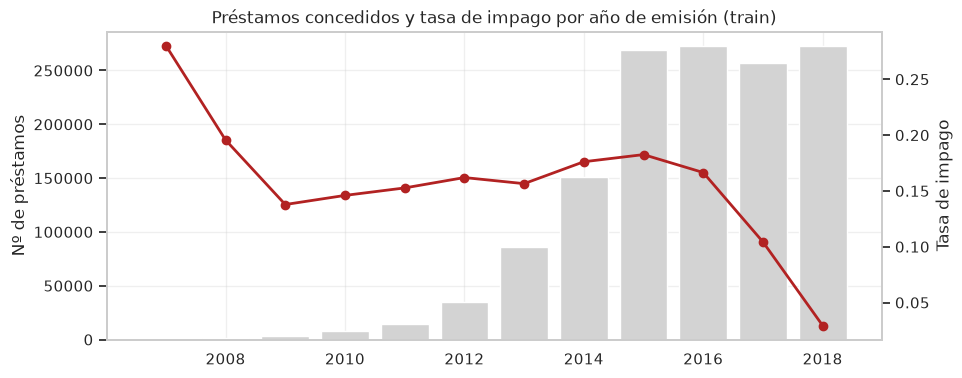

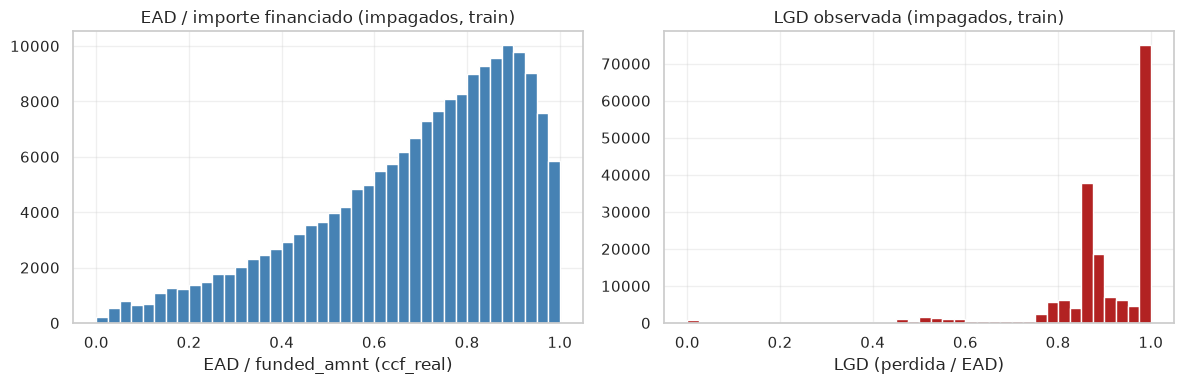

Proporción de impagados con LGD = 100% (sin recobros): 33.7%


issue_date_year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
ccf_real,0.6490,0.6490,0.6360,0.6430,0.6510,0.6290,0.6240,0.6330,0.6590,0.6910,0.7900,0.9020
lgd_real,0.9100,0.9000,0.9060,0.9000,0.9050,0.8870,0.8690,0.8720,0.8830,0.9080,0.9450,0.9910


,ccf_real,lgd_real
loan_term_months,,
36,0.6350,0.8990
60,0.7750,0.9050


In [7]:
# --- 1. Efecto vintage y censura por la derecha ---
# Agrupación por año de emisión para medir volumen de concesión y tasa de impago observada
por_anio = train.groupby("issue_date_year")["y"].agg(prestamos="size", tasa_impago="mean")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(por_anio.index, por_anio["prestamos"], color="lightgray") # barras de volumen (eje izquierdo)
ax1.set_ylabel("Nº de préstamos")
ax2 = ax1.twinx()                                       # segundo eje vertical para la tasa porcentual
ax2.plot(por_anio.index, por_anio["tasa_impago"], "o-", color="firebrick", lw=2) # curva de tasa de impago
ax2.set_ylabel("Tasa de impago")
ax2.grid(False)                                         # desactivar rejilla secundaria para evitar superposición
plt.title("Préstamos concedidos y tasa de impago por año de emisión (train)")
plt.show()

# --- 2. Distribución de EAD / importe (ccf_real) y LGD (lgd_real) en los impagados ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(impagados["ccf_real"].dropna(), bins=40, color="steelblue", edgecolor="white") # histograma de ratio EAD
ax[0].set_title("EAD / importe financiado (impagados, train)")
ax[0].set_xlabel("EAD / funded_amnt (ccf_real)")
ax[1].hist(impagados["lgd_real"].dropna(), bins=40, color="firebrick", edgecolor="white")  # histograma de ratio LGD
ax[1].set_title("LGD observada (impagados, train)")
ax[1].set_xlabel("LGD (perdida / EAD)")
plt.tight_layout()
plt.show()

# Diagnóstico de severidad: préstamos sin posibilidad de recuperación
print(f"Proporción de impagados con LGD = 100% (sin recobros): {(impagados['lgd_real'] == 1).mean():.1%}")
display(impagados.groupby("issue_date_year")[["ccf_real", "lgd_real"]].mean().round(3).T) # evolución temporal
display(impagados.groupby("loan_term_months")[["ccf_real", "lgd_real"]].mean().round(3))  # desagregación por plazo


#### **Variables Numéricas**


Usamos una pequeña función para no repetir el mismo código 30 veces. Para cada variable muestra:

- un resumen (nulos, media, percentiles);
- su histograma (cortado en los percentiles 1 y 99 para que las colas no aplasten el gráfico);
- la tasa de impago por deciles, y la de los nulos si los hay.

Los deciles no funcionan con las **variables de conteo** (número de retrasos, de consultas...): casi todos los préstamos valen 0, 1 o 2, así que muchos deciles caen en el mismo valor y salen solo 2 o 3 tramos. En esas usamos **un tramo por valor** (0, 1, 2...) y juntamos la cola en un último tramo "k+" a partir del percentil 99. La función lo decide sola: si los deciles dan menos de 8 tramos distintos, cambia a tramos por valor.

In [ ]:
def analizar_numerica(col, datos=train):
    """
    Genera estadísticas descriptivas, histograma recortado en percentiles extremos
    y un gráfico de barras con la tasa de impago binarizada por deciles o valores únicos.
    """
    x = datos[col]                                      # serie numérica a analizar
    y = datos["y"]                                      # vector target asociado

    # Estadísticos descriptivos clave con percentiles de cola (P1 y P99 para evaluar outliers)
    resumen = x.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    resumen["% nulos"] = 100 * x.isna().mean()          # añadir porcentaje de valores ausentes
    print(f"--- {col} ---")
    print(resumen.round(2).to_string())

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

    # Histograma recortando las colas extremas (P1 a P99) para evitar deformación por outliers
    p1, p99 = x.quantile([0.01, 0.99])
    ax[0].hist(x[(x >= p1) & (x <= p99)], bins=40, color="steelblue") # distribución central
    ax[0].set_title(f"Distribución de {col} (p1-p99)")

    # Tasa de impago por tramos: deciles si es continua o tramos discretos si es conteo
    tramos = pd.qcut(x, 10, duplicates="drop")          # discretización en deciles con drop de duplicados
    if tramos.cat.categories.size >= 8:
        tasa = y.groupby(tramos, observed=True).mean()   # tasa media de impago en cada decil
        etiquetas = [f"{t.left:,.4g} a {t.right:,.4g}" for t in tasa.index] # formateo de intervalos legibles
    else:
        tope = x.quantile(0.99)                         # límite superior al percentil 99
        tasa = y.groupby(x.clip(upper=tope)).mean()     # tasa agrupada por cada valor discreto
        etiquetas = [f"{v:g}" for v in tasa.index]      # etiquetas numéricas simples
        if x.max() > tope:
            etiquetas[-1] = f"{tope:g}+"                # indicar tramo acumulado con signo '+'
    if x.isna().any():
        # Tratar los nulos como una categoría explícita para evaluar su señal predictiva
        tasa = pd.concat([tasa, pd.Series([y[x.isna()].mean()], index=["nulo"])])
        etiquetas.append("nulo")
    ax[1].bar(range(len(tasa)), tasa.values, color="darkorange") # barras de tasa de default por tramo
    ax[1].axhline(y.mean(), color="black", linestyle="--", label="media") # línea horizontal de tasa media global
    ax[1].set_xticks(range(len(tasa)))
    ax[1].set_xticklabels(etiquetas, rotation=60, fontsize=7) # rotación para legibilidad de etiquetas
    ax[1].set_title("Tasa de impago por tramos")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

##### **Condiciones del préstamo**

--- funded_amnt ---
count     1,369,371.0000
mean         14,777.2600
std           9,034.3800
min             500.0000
1%            1,500.0000
25%           8,000.0000
50%          12,225.0000
75%          20,000.0000
99%          40,000.0000
max          40,000.0000
% nulos           0.0000


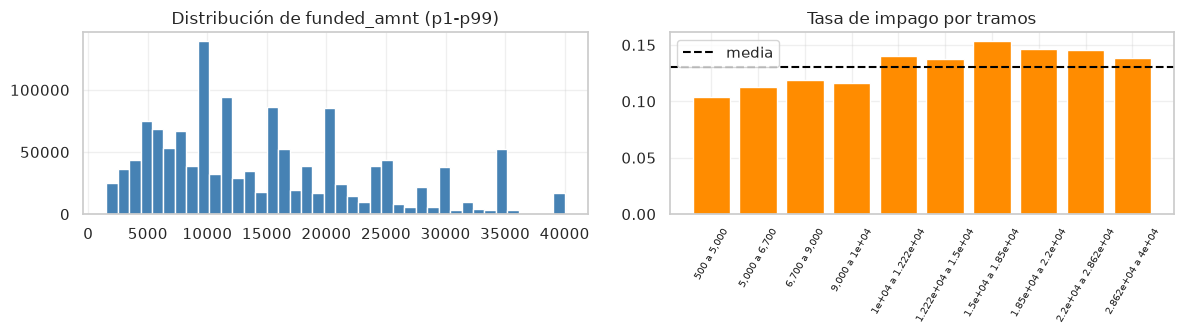

In [ ]:
analizar_numerica("funded_amnt")                   # importe total concedido y financiado del préstamo ($)

--- interest_rate ---
count     1,369,371.0000
mean             13.0600
std               4.8000
min               5.3100
1%                5.3200
25%               9.4900
50%              12.6200
75%              15.8800
99%              26.5700
max              30.9900
% nulos           0.0000


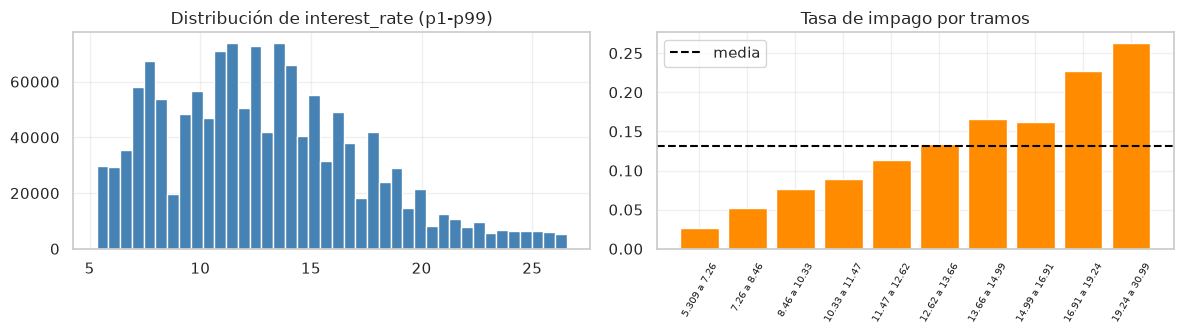

In [ ]:
analizar_numerica("interest_rate")                 # tipo de interés nominal anual aplicado al contrato (%)

--- monthly_payment ---
count     1,369,371.0000
mean            439.2300
std             263.5100
min               4.9300
1%               52.4500
25%             249.0800
50%             372.9600
75%             581.7800
99%           1,229.9700
max           1,719.8300
% nulos           0.0000


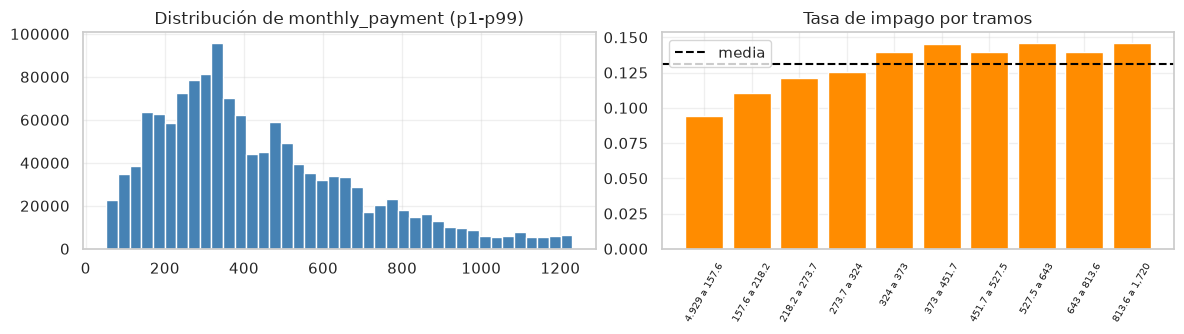

In [ ]:
analizar_numerica("monthly_payment")               # cuota periódica mensual de amortización (capital + interés)

**Lectura.**
- `interest_rate` es, con diferencia, la variable con más señal: la tasa de impago va del **2.7%** en el decil de tipo más bajo al **26%** en el más alto. Tiene sentido: Lending Club pone el tipo según el riesgo que ve en el cliente.
- `funded_amnt` tiene una relación suave: los préstamos pequeños impagan algo menos (10% frente a ~14-15%). Tiene picos en cifras redondas (10,000, 20,000...) y un máximo contractual de 40,000 $, así que no hay outliers que tratar.
- `monthly_payment` es prácticamente una función de importe, tipo y plazo. Lo confirmaremos en las correlaciones: sobra.

##### **Capacidad de pago**

--- annual_income ---
count      1,369,371.0000
mean          78,925.4600
std           91,282.1400
min            1,900.0000
1%            18,963.5500
25%           47,500.0000
50%           65,294.2600
75%           95,000.0000
99%          275,000.0000
max       61,000,000.0000
% nulos            0.0000


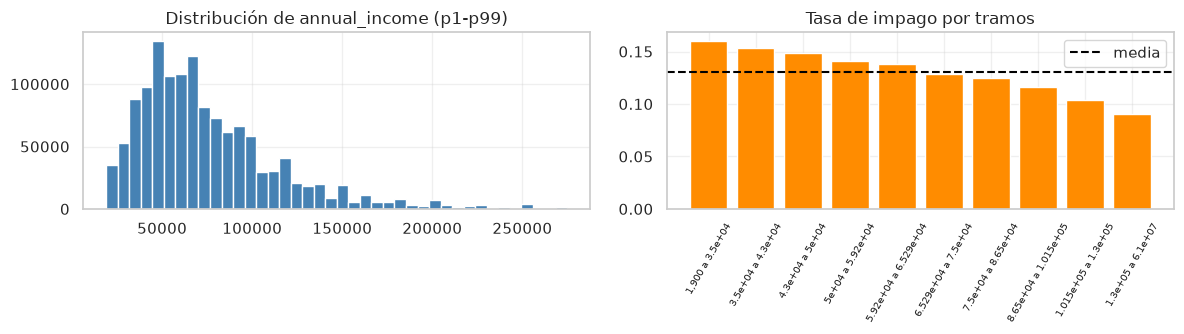

In [ ]:
analizar_numerica("annual_income")                 # ingresos anuales brutos declarados por el prestatario ($)

--- dept_paym_income_ratio ---
count     1,369,371.0000
mean             18.0900
std               8.4300
min              -1.0000
1%                1.7700
25%              11.7800
50%              17.6000
75%              24.0400
99%              37.5900
max              49.9600
% nulos           0.0000


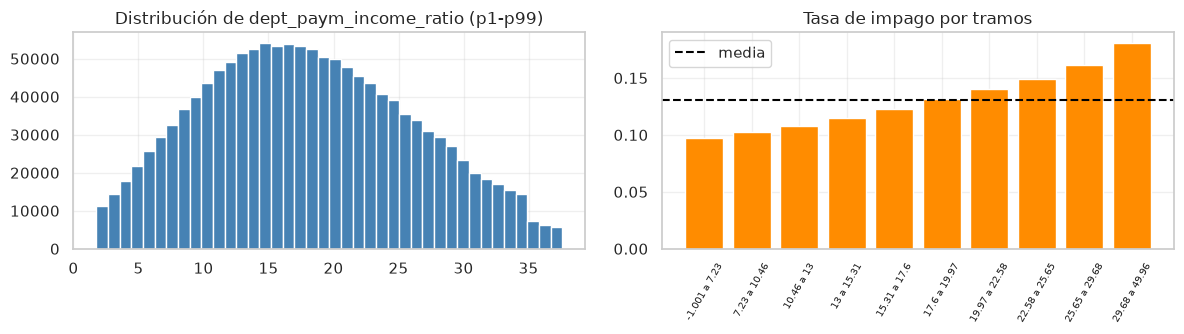

In [ ]:
analizar_numerica("dept_paym_income_ratio")        # ratio deuda/ingresos (DTI): porcentaje de ingresos comprometido

**Lectura.**
- `annual_income`: cuanto más ingresos, menos impago (del 16% en el decil más bajo al 9% en el más alto). Tiene una cola larguísima, con ingresos de hasta 61 millones: el percentil 99 es 275,000 $. Para la logística la recortaremos.
- `dept_paym_income_ratio` (DTI): relación clara y creciente, del 10% al 18%. Hay algún valor -1, que es un código de "sin dato" y no un ratio real.
- Normalmente, más que los ingresos sueltos, interesa **lo que pesa el préstamo sobre los ingresos**: lo construiremos en la ingeniería de variables.

##### **Uso del crédito revolving**

--- total_credit_revolving_bal ---
count     1,369,371.0000
mean         16,643.9500
std          23,063.2900
min               0.0000
1%              152.0000
25%           5,984.0000
50%          11,322.0000
75%          20,203.0000
99%          97,445.0000
max       2,904,836.0000
% nulos           0.0000


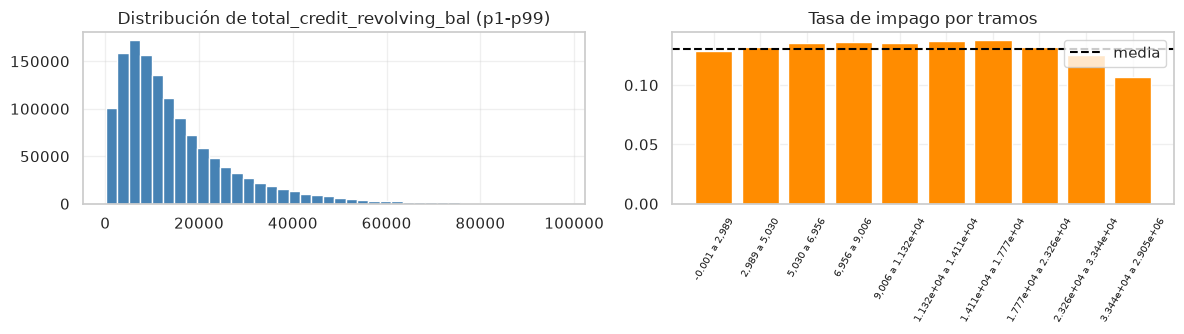

In [ ]:
analizar_numerica("total_credit_revolving_bal")    # saldo deudor total dispuesto en tarjetas y líneas revolving ($)

--- used_credit_share ---
count     1,369,371.0000
mean             50.4700
std              24.6400
min               0.0000
1%                0.9000
25%              31.7000
50%              50.4000
75%              69.4000
99%              98.1000
max             193.0000
% nulos           0.0000


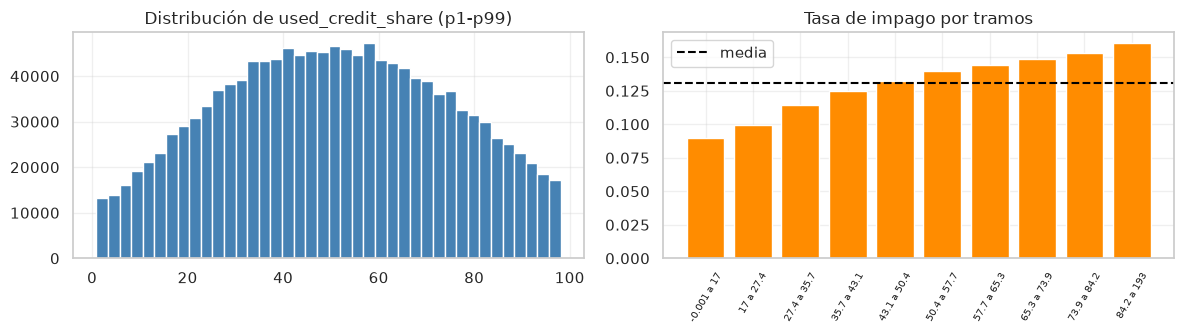

In [ ]:
analizar_numerica("used_credit_share")             # ratio de utilización agregado del límite de crédito (%)

--- bal_to_cred_lim ---
count     815,286.0000
mean           57.0700
std            20.8600
min             0.0000
1%              7.0000
25%            43.0000
50%            58.0000
75%            72.0000
99%           102.0000
max           196.0000
% nulos        40.4600


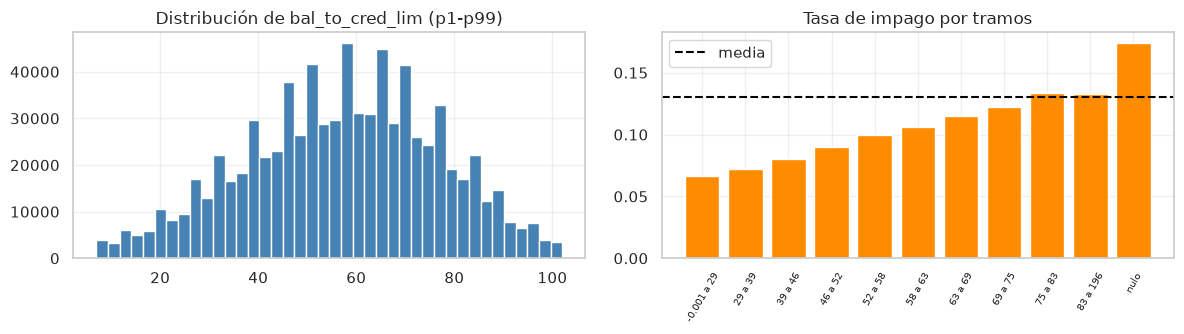

In [ ]:
analizar_numerica("bal_to_cred_lim")               # saldo dispuesto frente al límite en cuentas bancarias (%)

--- max_bal_owed ---
count       815,370.0000
mean          5,790.2500
std           5,687.8200
min               0.0000
1%                0.0000
25%           2,305.0000
50%           4,403.0000
75%           7,553.0000
99%          24,897.3100
max       1,170,668.0000
% nulos          40.4600


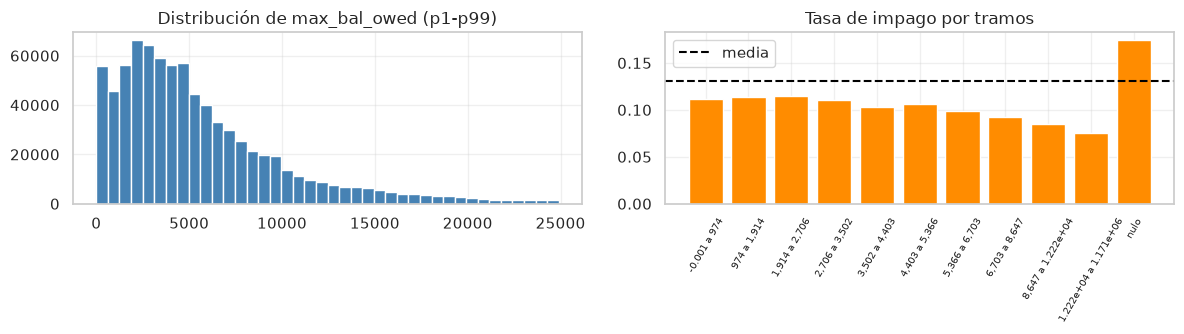

In [ ]:
analizar_numerica("max_bal_owed")                  # saldo máximo adeudado histórico en una sola línea ($)

**Lectura.**
- `used_credit_share` (qué % del crédito revolving está usando): a más uso, más impago (del 9% al 16%). Hay algunos valores por encima de 100%: son clientes que se pasan de su límite.
- `total_credit_revolving_bal` apenas discrimina por sí sola (solo el decil más alto impaga algo menos), y tiene una cola enorme (máximo de 2.9 millones).
- `bal_to_cred_lim` y `max_bal_owed` tienen un **40% de nulos**. Fíjate en la barra de los nulos: su tasa de impago es del **17%**, más alta que cualquier decil. El nulo trae información; lo vemos en el apartado 5.4.

##### **Líneas de crédito**

--- num_open_credit_lines ---
count     1,369,371.0000
mean             11.6400
std               5.6500
min               0.0000
1%                3.0000
25%               8.0000
50%              11.0000
75%              14.0000
99%              30.0000
max             101.0000
% nulos           0.0000


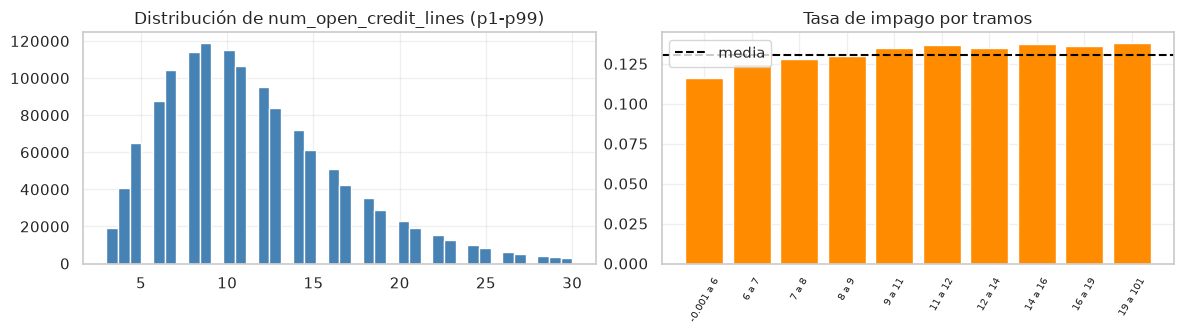

In [ ]:
analizar_numerica("num_open_credit_lines")         # número de líneas de crédito activas y abiertas actualmente

--- tot_num_credit_lines ---
count     1,369,371.0000
mean             24.2600
std              12.0200
min               1.0000
1%                5.0000
25%              15.0000
50%              22.0000
75%              31.0000
99%              61.0000
max             169.0000
% nulos           0.0000


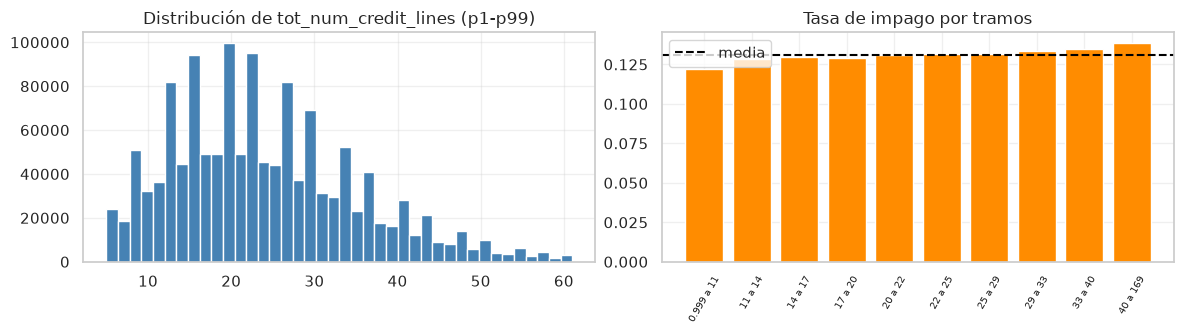

In [ ]:
analizar_numerica("tot_num_credit_lines")          # número total histórico de cuentas de crédito registradas

**Lectura.**
- El número de líneas de crédito abiertas o totales apenas cambia la tasa de impago (del 12% al 14%). Son variables con poca señal por sí solas.
- Tienen colas largas (hasta 100+ líneas) que recortaremos para la logística.

##### **Morosidad previa**

--- num_30+_delinq_in_2yrs ---
count     1,369,371.0000
mean              0.3100
std               0.8800
min               0.0000
1%                0.0000
25%               0.0000
50%               0.0000
75%               0.0000
99%               4.0000
max              58.0000
% nulos           0.0000


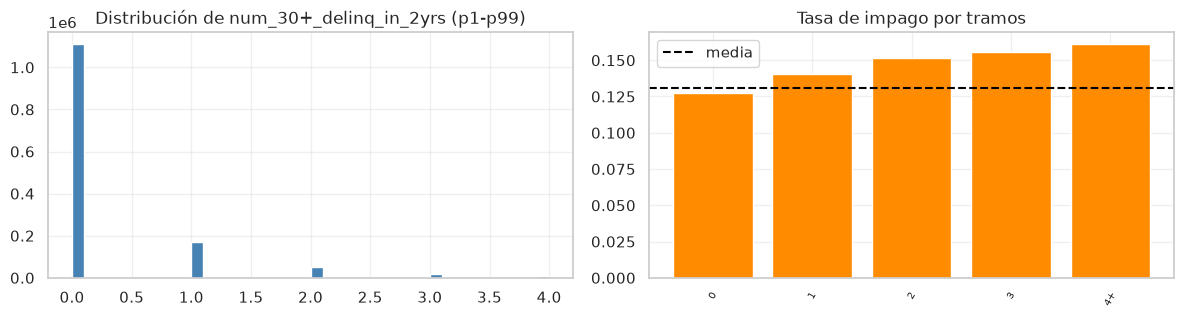

In [ ]:
analizar_numerica("num_30+_delinq_in_2yrs")        # número de impagos de más de 30 días en los últimos 2 años

--- num_derogatory_pub_rec ---
count     1,369,371.0000
mean              0.2000
std               0.5800
min               0.0000
1%                0.0000
25%               0.0000
50%               0.0000
75%               0.0000
99%               2.0000
max              86.0000
% nulos           0.0000


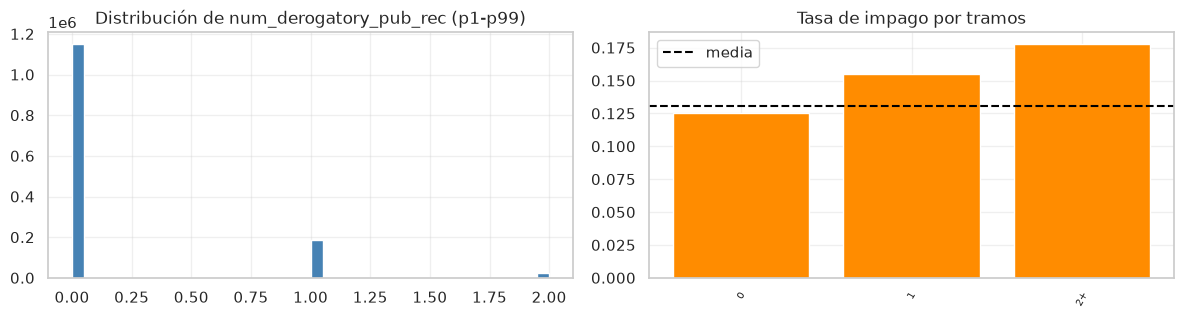

In [ ]:
analizar_numerica("num_derogatory_pub_rec")        # registros públicos negativos judiciales o quiebras históricas

--- mths_since_last_delinq ---
count     671,381.0000
mean           34.5000
std            21.9000
min             0.0000
1%              2.0000
25%            16.0000
50%            31.0000
75%            50.0000
99%            81.0000
max           226.0000
% nulos        50.9700


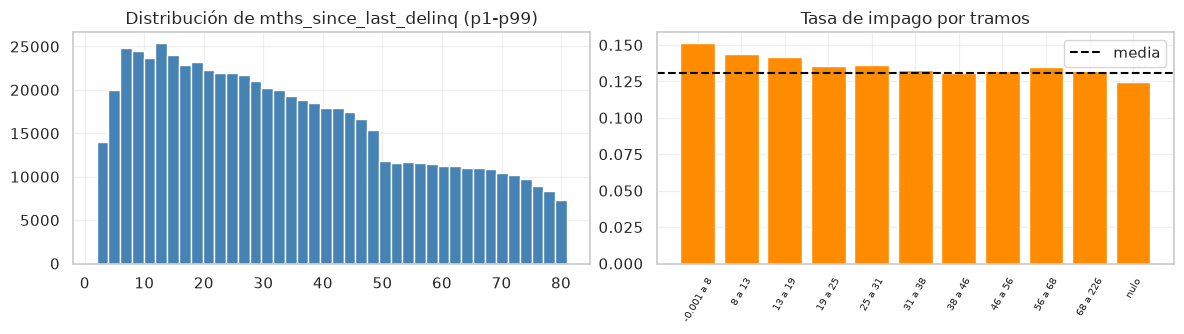

In [ ]:
analizar_numerica("mths_since_last_delinq")        # meses desde la última morosidad (nulo = sin morosidad previa)

--- mths_since_recent_bankcard_delinq ---
count     318,080.0000
mean           39.3400
std            22.6200
min             0.0000
1%              2.0000
25%            21.0000
50%            37.0000
75%            57.0000
99%            84.0000
max           202.0000
% nulos        76.7700


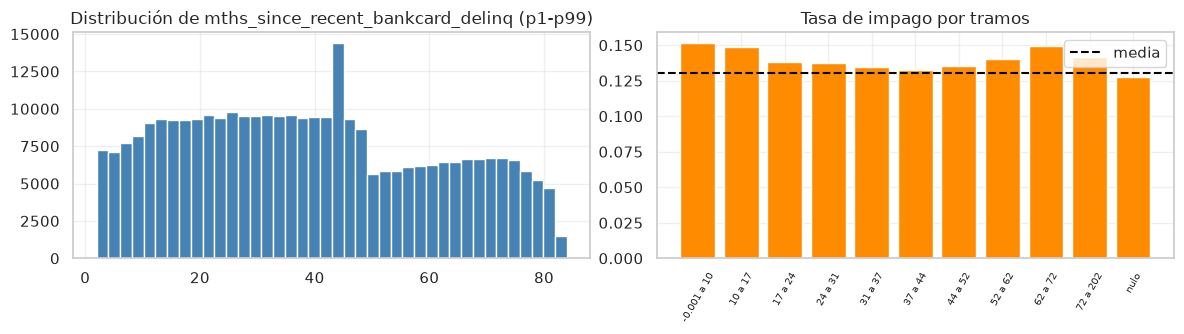

In [ ]:
analizar_numerica("mths_since_recent_bankcard_delinq") # meses desde la última morosidad en tarjetas bancarias

--- mths_since_recent_revol_delinq ---
count     451,984.0000
mean           35.7600
std            22.3100
min             0.0000
1%              2.0000
25%            17.0000
50%            33.0000
75%            51.0000
99%            82.0000
max           202.0000
% nulos        66.9900


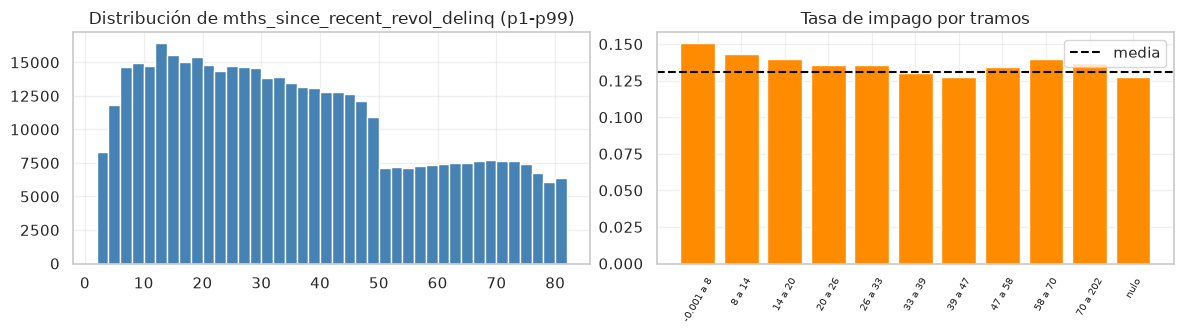

In [ ]:
analizar_numerica("mths_since_recent_revol_delinq") # meses desde la última morosidad en cuentas revolving

**Lectura.**
- `num_30+_delinq_in_2yrs` y `num_derogatory_pub_rec` son casi siempre 0 (en el 81% y el 84% de los préstamos), así que aquí la función usa tramos por valor. La tasa de impago sube con cada retraso: del **12.7%** sin ninguno al **16.1%** con 4 o más. Con los registros públicos negativos, del 12.6% al **17.8%** con 2 o más.
- Las variables `mths_since_...` (meses desde el último retraso) tienen entre un **51% y un 77% de nulos**. Ese nulo significa **"nunca ha tenido un retraso"**, y su tasa de impago (12.4-12.8%) es de las más bajas. Rellenarlo con la mediana sería decirle al modelo que el cliente tuvo un retraso hace 31 meses: justo lo contrario. Lo trataremos con un indicador.
- Cuanto más reciente es el último retraso, algo más de impago (15% en el primer decil), aunque la relación es débil.

##### **Consultas y aperturas recientes**

--- num_inq_in_6mths ---
count     1,369,371.0000
mean              0.5900
std               0.9000
min               0.0000
1%                0.0000
25%               0.0000
50%               0.0000
75%               1.0000
99%               4.0000
max              31.0000
% nulos           0.0000


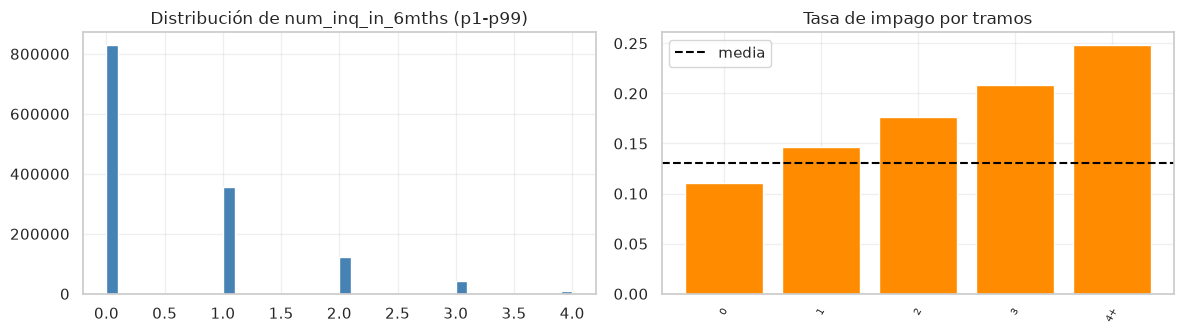

In [ ]:
analizar_numerica("num_inq_in_6mths")              # consultas de solvencia al buró en los últimos 6 meses

--- num_inq_in_12mths ---
count     1,369,371.0000
mean              1.5000
std               2.0500
min               0.0000
1%                0.0000
25%               0.0000
50%               1.0000
75%               2.0000
99%               9.0000
max              49.0000
% nulos           0.0000


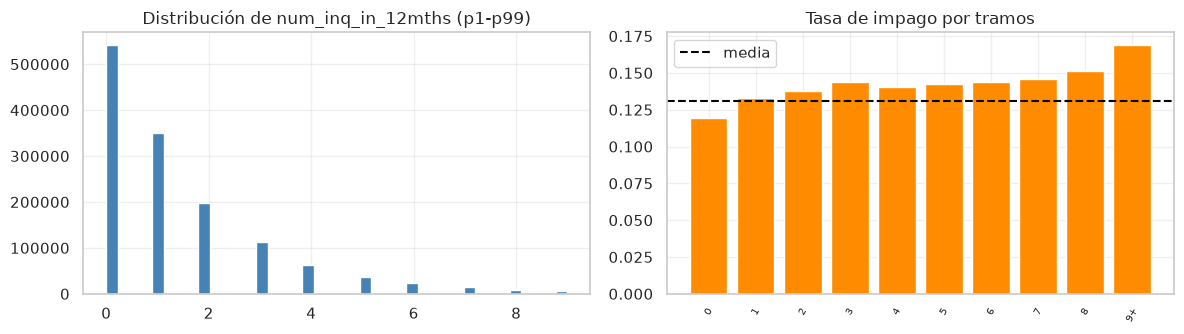

In [ ]:
analizar_numerica("num_inq_in_12mths")             # consultas de solvencia al buró en los últimos 12 meses

--- num_inq ---
count     815,370.0000
mean            1.0100
std             1.4800
min             0.0000
1%              0.0000
25%             0.0000
50%             0.0000
75%             1.0000
99%             7.0000
max            48.0000
% nulos        40.4600


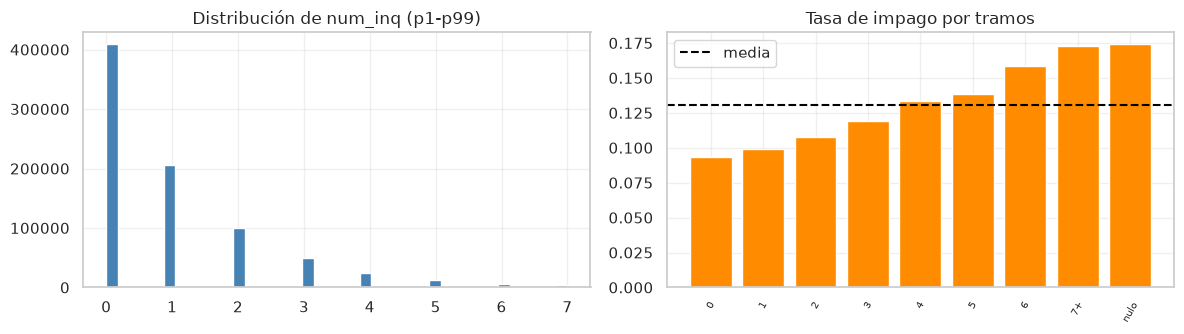

In [ ]:
analizar_numerica("num_inq")                       # consultas totales registradas en el historial del buró

--- num_open_trades_in_6mths ---
count     815,370.0000
mean            0.9400
std             1.1500
min             0.0000
1%              0.0000
25%             0.0000
50%             1.0000
75%             1.0000
99%             5.0000
max            17.0000
% nulos        40.4600


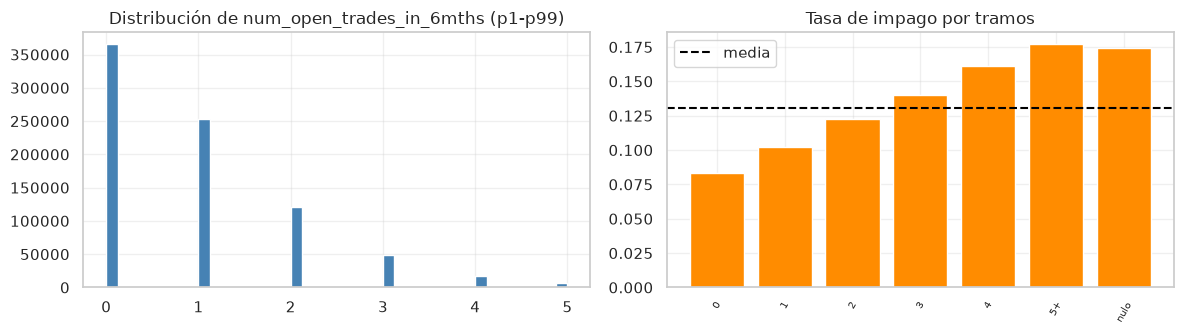

In [ ]:
analizar_numerica("num_open_trades_in_6mths")      # cuentas comerciales y financieras abiertas en últimos 6 meses

--- num_installment_acc_op_in_12mths ---
count     815,370.0000
mean            0.6800
std             0.9300
min             0.0000
1%              0.0000
25%             0.0000
50%             0.0000
75%             1.0000
99%             4.0000
max            25.0000
% nulos        40.4600


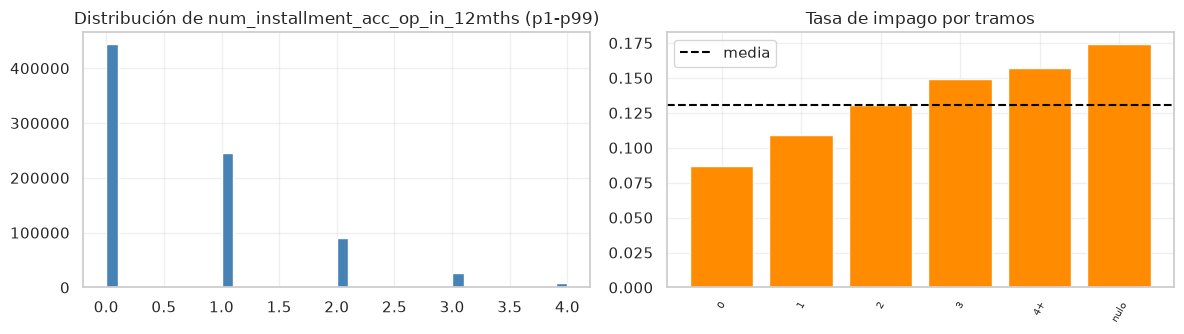

In [ ]:
analizar_numerica("num_installment_acc_op_in_12mths") # préstamos a cuota fija abiertos en los últimos 12 meses

--- num_installment_acc_op_in_24mths ---
count     815,370.0000
mean            1.5700
std             1.5800
min             0.0000
1%              0.0000
25%             0.0000
50%             1.0000
75%             2.0000
99%             7.0000
max            51.0000
% nulos        40.4600


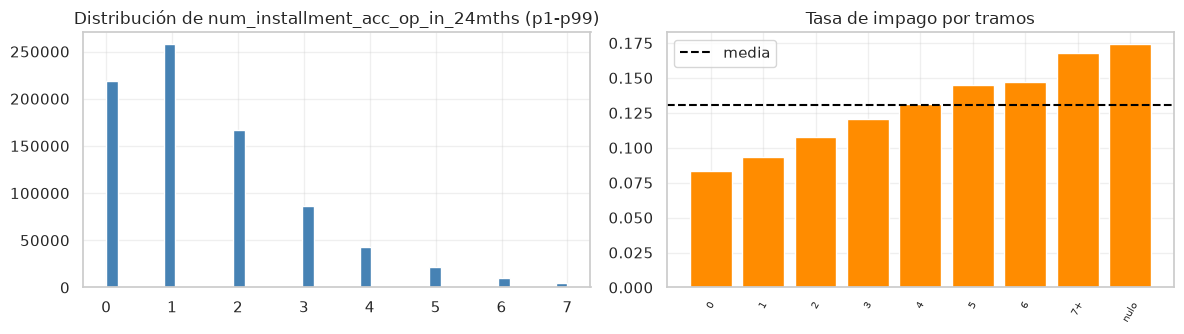

In [ ]:
analizar_numerica("num_installment_acc_op_in_24mths") # préstamos a cuota fija abiertos en los últimos 24 meses

--- num_rev_trades_op_in_12mths ---
count     815,370.0000
mean            1.3100
std             1.5200
min             0.0000
1%              0.0000
25%             0.0000
50%             1.0000
75%             2.0000
99%             7.0000
max            27.0000
% nulos        40.4600


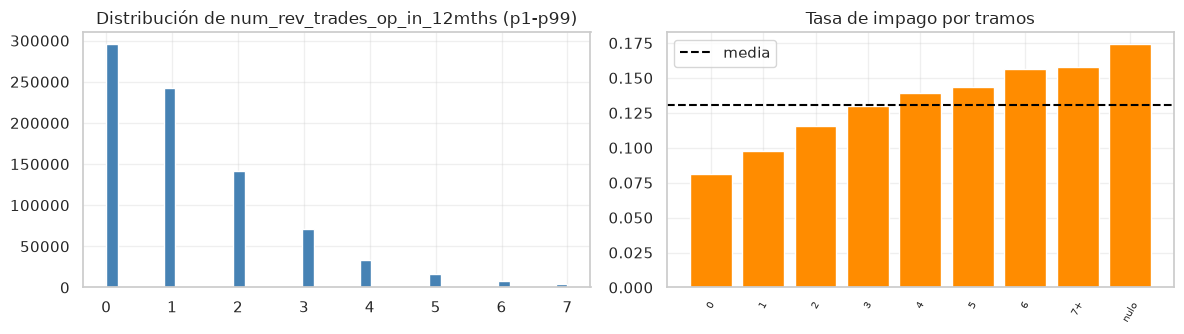

In [ ]:
analizar_numerica("num_rev_trades_op_in_12mths")   # cuentas de tarjeta revolving abiertas en últimos 12 meses

--- num_rev_trades_op_in_24mths ---
count     815,370.0000
mean            2.7900
std             2.6200
min             0.0000
1%              0.0000
25%             1.0000
50%             2.0000
75%             4.0000
99%            12.0000
max            60.0000
% nulos        40.4600


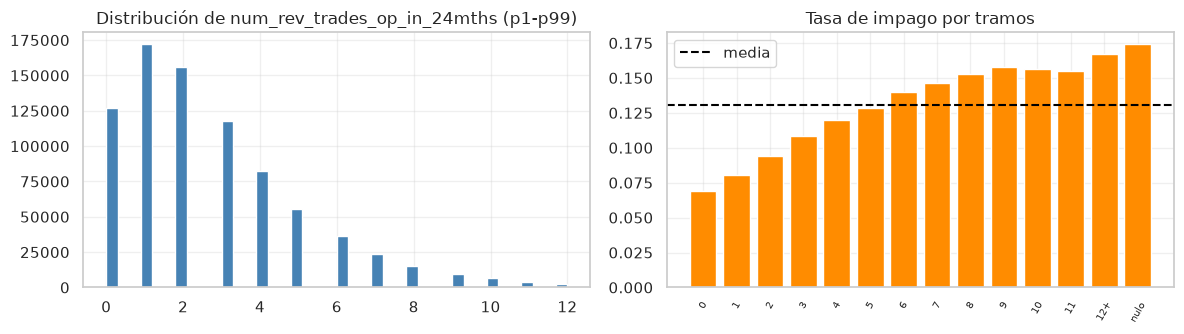

In [ ]:
analizar_numerica("num_rev_trades_op_in_24mths")   # cuentas de tarjeta revolving abiertas en últimos 24 meses

--- mths_since_last_installment_acc_op ---
count     790,024.0000
mean           21.1200
std            25.9400
min             0.0000
1%              1.0000
25%             7.0000
50%            13.0000
75%            24.0000
99%           134.0000
max           511.0000
% nulos        42.3100


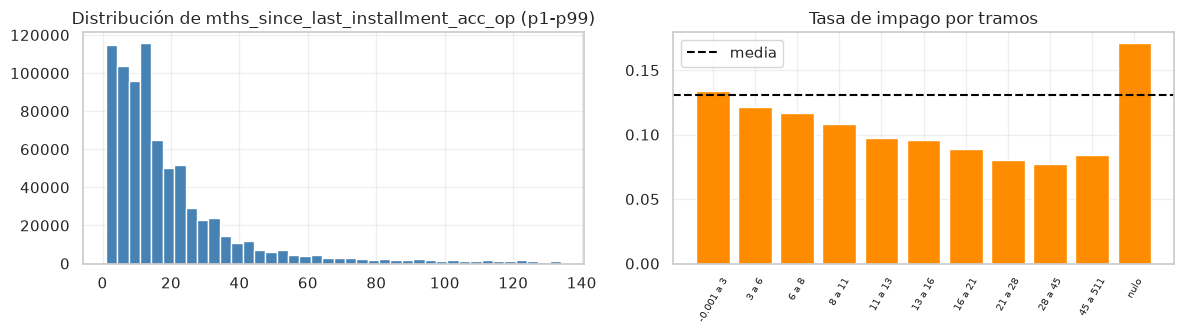

In [ ]:
analizar_numerica("mths_since_last_installment_acc_op") # meses desde la apertura del último préstamo a plazos

**Lectura.**
- Las **consultas de crédito recientes** son una señal clásica de estrés: quien está pidiendo crédito en muchos sitios impaga más. Con los tramos por valor se ve el escalón a escalón: `num_inq_in_6mths` pasa del **11%** (ninguna consulta) al 15%, 18%, 21% y **25%** (4 o más).
- Lo mismo con las **aperturas recientes** de cuentas: `num_open_trades_in_6mths` va del 8% (ninguna) al 18% (5 o más) y `num_rev_trades_op_in_24mths`, del 7% al 17%. Y al revés con `mths_since_last_installment_acc_op`: cuanto más tiempo desde la última apertura, menos impago.
- Casi todas estas variables tienen el **mismo 40% de nulos**, y con la misma tasa de impago (17.4%): son un bloque que falta entero. Lo investigamos con más detalle en el 5.4.

##### **Fechas**

--- issue_date_year ---
count     1,369,371.0000
mean          2,015.7600
std               1.7900
min           2,007.0000
1%            2,011.0000
25%           2,015.0000
50%           2,016.0000
75%           2,017.0000
99%           2,018.0000
max           2,018.0000
% nulos           0.0000


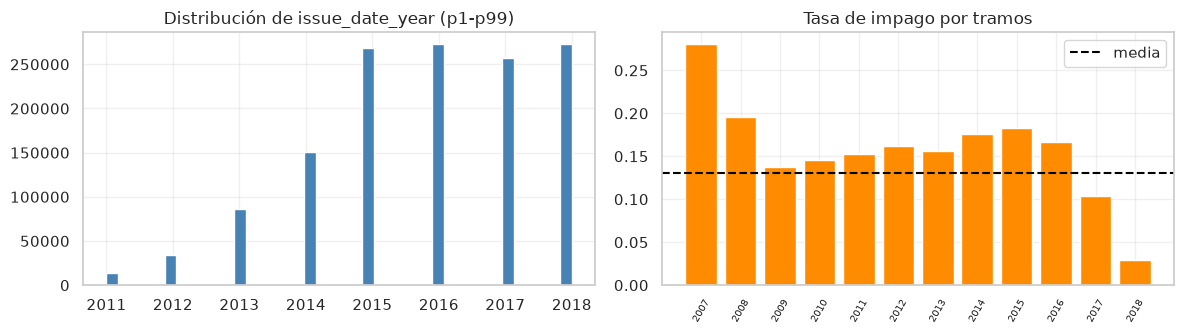

In [ ]:
analizar_numerica("issue_date_year")               # año de originación y emisión del contrato (análisis vintage)

--- earliest_cr_line_year ---
count     1,369,371.0000
mean          1,999.4000
std               7.8300
min           1,934.0000
1%            1,976.0000
25%           1,995.0000
50%           2,001.0000
75%           2,005.0000
99%           2,013.0000
max           2,015.0000
% nulos           0.0000


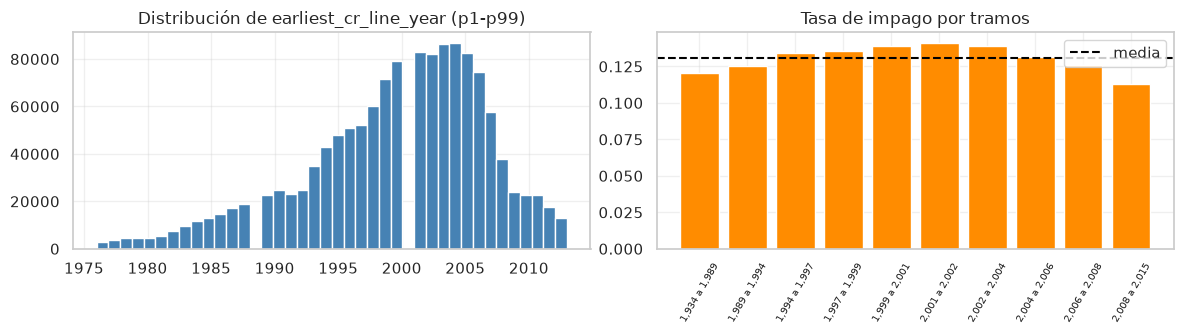

In [ ]:
analizar_numerica("earliest_cr_line_year")         # año de apertura de la primera línea de crédito del cliente

**Lectura.**
- `issue_date_year` (con un tramo por año, porque solo tiene 12 valores) confirma lo que vimos con el target: la tasa de impago ronda el 14-18% hasta 2016 y cae al **10% en 2017** y al **3% en 2018** por la censura. Los picos de 2007-2008 tienen muy pocos préstamos.
- `earliest_cr_line_year` (año de la primera línea de crédito) por sí solo dice poco. Lo útil es la **diferencia** entre la fecha de emisión y la primera línea, es decir, los años de historial que tenía el cliente: la construiremos en el 6.4.

#### **Variables Categóricas**

Para cada una: cuántos préstamos hay en cada categoría y su tasa de impago.

In [ ]:
def analizar_categorica(col, datos=train, top=20):
    """
    Genera tabla de frecuencia, % de cartera y tasa de impago para cada categoría,
    acompañada de un gráfico de barras ordenado por severidad de riesgo.
    """
    x = datos[col].fillna("(nulo)")                     # imputar etiqueta visible para valores ausentes
    tabla = datos.groupby(x)["y"].agg(prestamos="size", tasa_impago="mean") # conteo de préstamos y tasa media de mora
    tabla["% cartera"] = 100 * tabla["prestamos"] / len(datos)              # peso porcentual en la cartera
    tabla = tabla.sort_values("prestamos", ascending=False).head(top)      # filtrar categorías más frecuentes

    print(f"--- {col}: {datos[col].nunique():,} categorías, {100 * datos[col].isna().mean():.2f}% nulos ---")
    print(tabla.round(4).to_string())

    # Gráfico de barras ordenado por riesgo crediticio ascendente
    orden = tabla.sort_values("tasa_impago")            # ordenar de menor a mayor morosidad
    plt.figure(figsize=(11, 3.5))
    plt.bar(orden.index.astype(str), orden["tasa_impago"], color="seagreen") # barras de riesgo por segmento
    plt.axhline(datos["y"].mean(), color="black", linestyle="--", label="media") # referencia media de la cartera
    plt.xticks(rotation=60, fontsize=8)
    plt.title(f"Tasa de impago por {col}")
    plt.legend()
    plt.show()

--- loan_term_months: 2 categorías, 0.00% nulos ---
                  prestamos  tasa_impago  % cartera
loan_term_months                                   
36                   985881       0.1107    71.9952
60                   383490       0.1823    28.0048


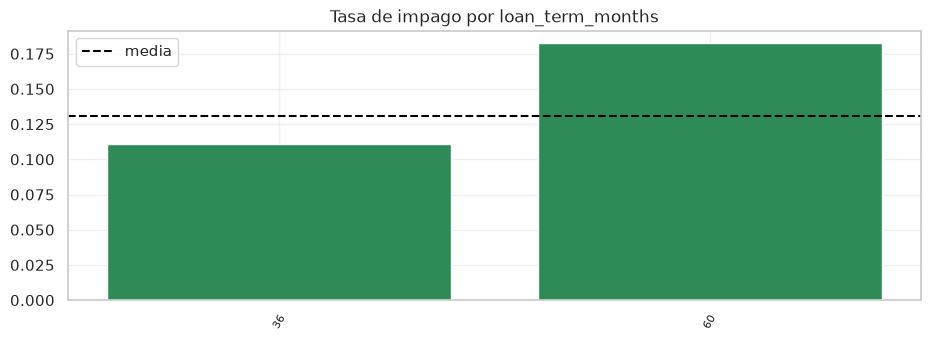

In [ ]:
analizar_categorica("loan_term_months")            # plazo contractual de amortización (36 vs 60 meses)

--- grade: 35 categorías, 0.00% nulos ---
       prestamos  tasa_impago  % cartera
grade                                   
C1         88252       0.1240     6.4447
B4         85441       0.0978     6.2394
B5         85142       0.1102     6.2176
B3         80768       0.0889     5.8982
C2         79325       0.1375     5.7928
C3         77752       0.1446     5.6779
B2         76658       0.0744     5.5980
C4         76427       0.1622     5.5812
B1         75373       0.0665     5.5042
C5         70356       0.1667     5.1378
A5         66091       0.0540     4.8264
A4         58153       0.0416     4.2467
A1         52984       0.0177     3.8692
D1         49725       0.1921     3.6312
A3         44147       0.0323     3.2239
D2         43590       0.2019     3.1832
A2         41683       0.0273     3.0440
D3         38937       0.2050     2.8434
D4         34441       0.2229     2.5151
D5         28824       0.2311     2.1049


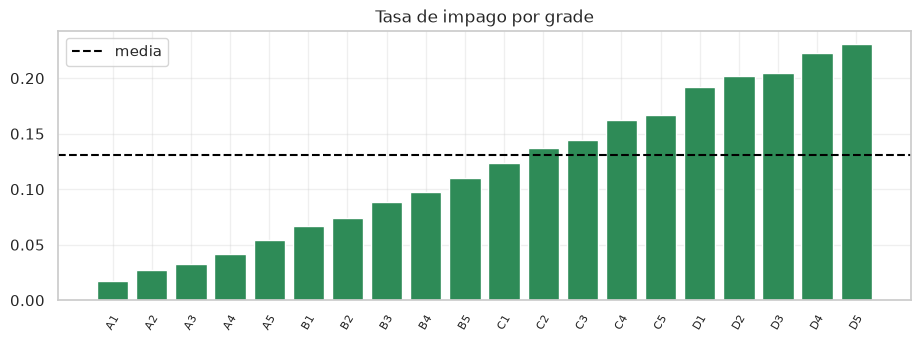

In [ ]:
analizar_categorica("grade")                       # rating crediticio originario de Lending Club (A-G, solo EDA)

> `grade` lo miramos solo para entender la cartera. **No entra en ningún modelo.**

--- emp_length: 11 categorías, 6.09% nulos ---
            prestamos  tasa_impago  % cartera
emp_length                                   
10+ years      457294       0.1216    33.3945
2 years        124357       0.1298     9.0813
3 years        110674       0.1316     8.0821
< 1 year       107360       0.1310     7.8401
1 year          90916       0.1352     6.6393
5 years         85293       0.1307     6.2286
4 years         83690       0.1290     6.1116
(nulo)          83368       0.1625     6.0881
6 years         63580       0.1299     4.6430
7 years         56952       0.1367     4.1590
8 years         56863       0.1424     4.1525
9 years         49024       0.1373     3.5800


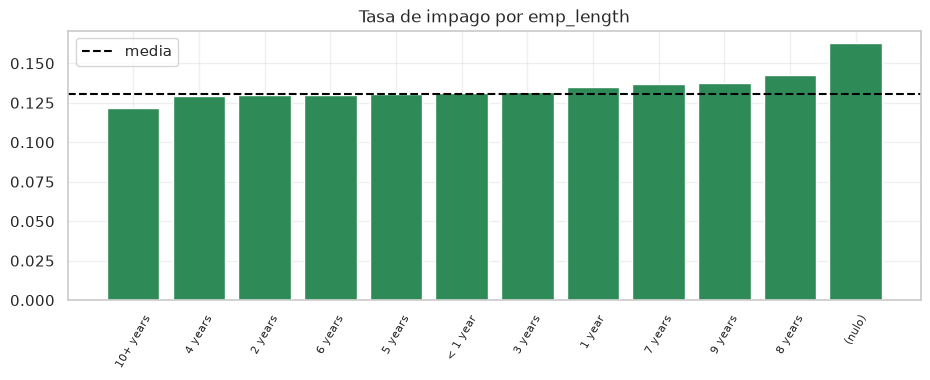

In [ ]:
analizar_categorica("emp_length")                  # años de antigüedad laboral declarados por el prestatario

--- home_ownership_status: 4 categorías, 0.00% nulos ---
                       prestamos  tasa_impago  % cartera
home_ownership_status                                   
MORTGAGE                  660312       0.1147    48.2201
RENT                      553923       0.1501    40.4509
OWN                       154341       0.1303    11.2709
OTHER                        795       0.0893     0.0581


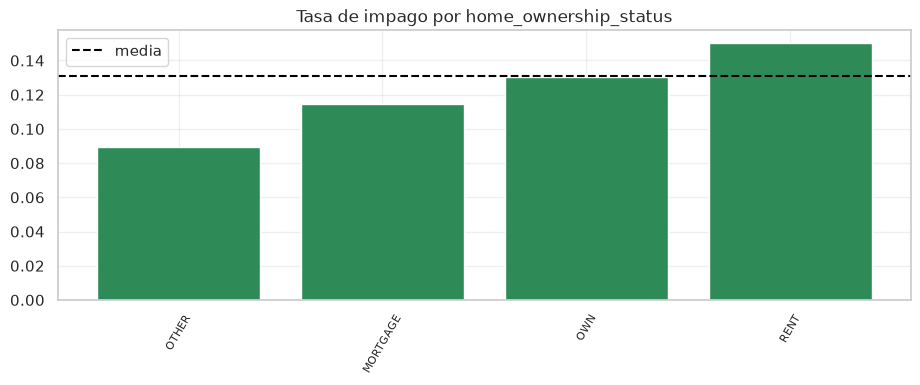

In [ ]:
analizar_categorica("home_ownership_status")       # régimen de tenencia de la vivienda (propiedad, hipoteca, alquiler)

--- verification_status: 3 categorías, 0.00% nulos ---
                     prestamos  tasa_impago  % cartera
verification_status                                   
Source Verified         545507       0.1347    39.8363
Not Verified            448013       0.0893    32.7167
Verified                375851       0.1743    27.4470


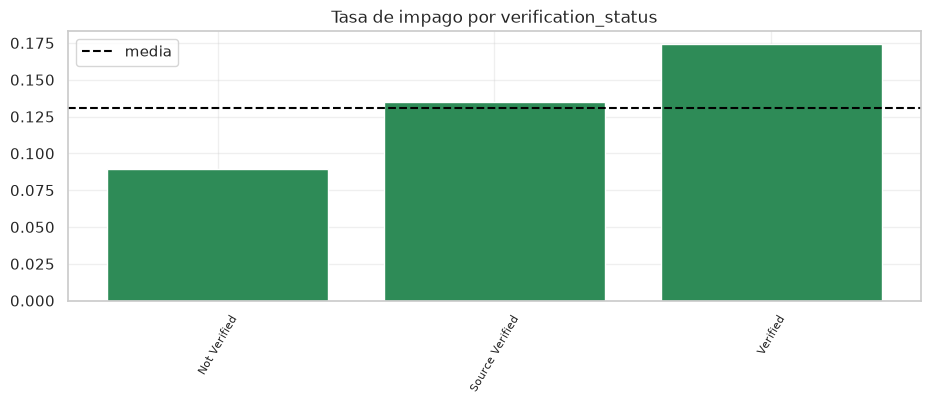

In [ ]:
analizar_categorica("verification_status")         # estado de validación documental de los ingresos declarados

--- loan_purpose: 14 categorías, 0.00% nulos ---
                    prestamos  tasa_impago  % cartera
loan_purpose                                         
debt_consolidation     772016       0.1414    56.3774
credit_card            316160       0.1066    23.0880
home_improvement        89978       0.1168     6.5708
other                   84509       0.1316     6.1714
major_purchase          30693       0.1216     2.2414
medical                 16138       0.1356     1.1785
small_business          14999       0.2039     1.0953
car                     14704       0.0980     1.0738
vacation                 9567       0.1225     0.6986
moving                   9208       0.1565     0.6724
house                    8730       0.1286     0.6375
wedding                  1510       0.1265     0.1103
renewable_energy          888       0.1667     0.0648
educational               271       0.2066     0.0198


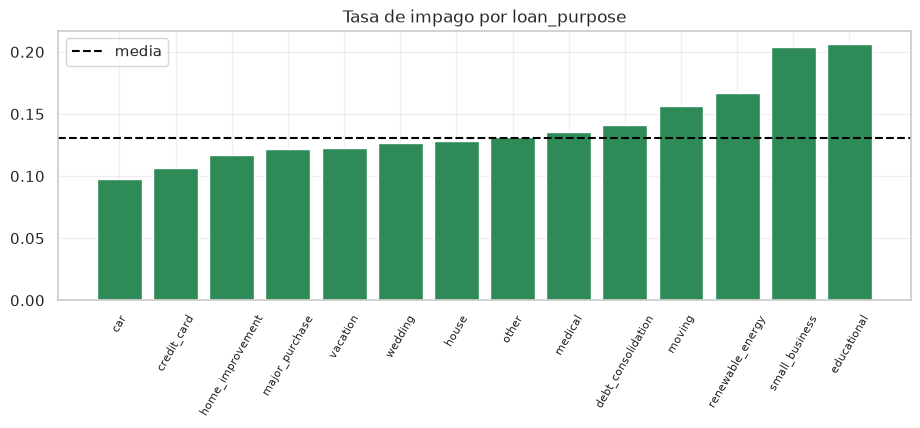

In [ ]:
analizar_categorica("loan_purpose")                # finalidad declarada del crédito (consolidación de deuda, etc.)

--- initial_list_status: 2 categorías, 0.00% nulos ---
                     prestamos  tasa_impago  % cartera
initial_list_status                                   
w                       916029       0.1162    66.8941
f                       453342       0.1600    33.1059


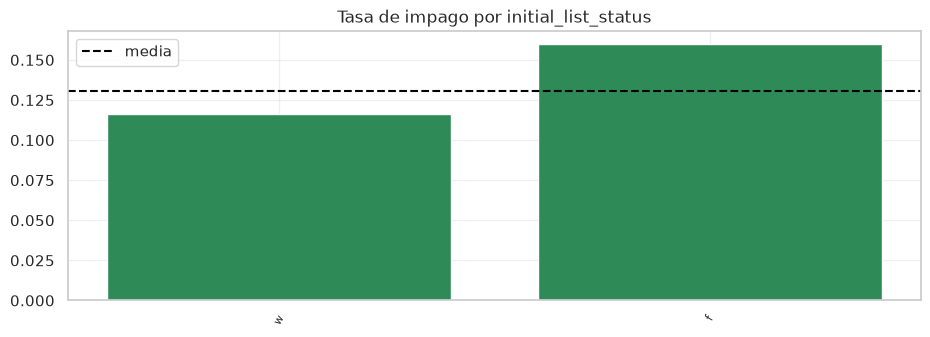

In [ ]:
analizar_categorica("initial_list_status")         # modalidad inicial de oferta y sindicación del préstamo (w / f)

--- disbursement_method: 2 categorías, 0.00% nulos ---
                     prestamos  tasa_impago  % cartera
disbursement_method                                   
Cash                   1322763       0.1345    96.5964
DirectPay                46608       0.0246     3.4036


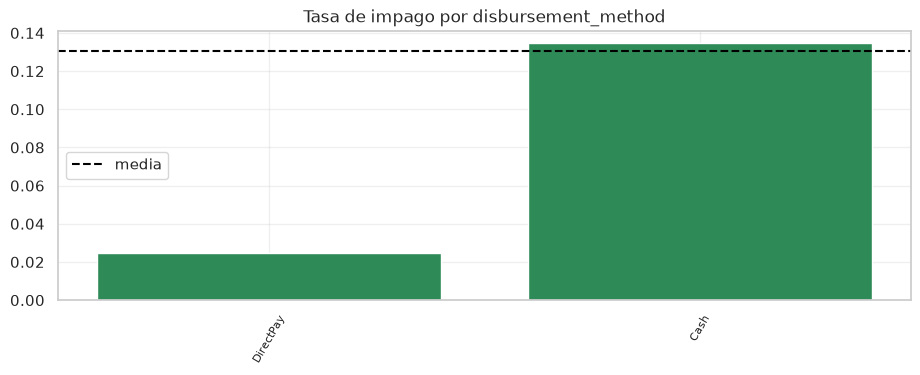

In [ ]:
analizar_categorica("disbursement_method")         # método de desembolso y liquidación de fondos (efectivo / directo)

--- addr_state: 51 categorías, 0.00% nulos ---
            prestamos  tasa_impago  % cartera
addr_state                                   
CA             192394       0.1334    14.0498
NY             114631       0.1423     8.3711
TX             112841       0.1312     8.2404
FL              98397       0.1419     7.1856
IL              54971       0.1125     4.0143
NJ              50561       0.1333     3.6923
PA              46614       0.1350     3.4040
GA              45323       0.1186     3.3098
OH              45322       0.1297     3.3097
VA              38461       0.1320     2.8087
NC              38030       0.1372     2.7772
MI              35786       0.1333     2.6133
MD              33241       0.1360     2.4275
AZ              32143       0.1296     2.3473
MA              31530       0.1251     2.3025
CO              29068       0.1039     2.1227
WA              28268       0.1074     2.0643
MN              23861       0.1300     1.7425
IN              22223       0.137

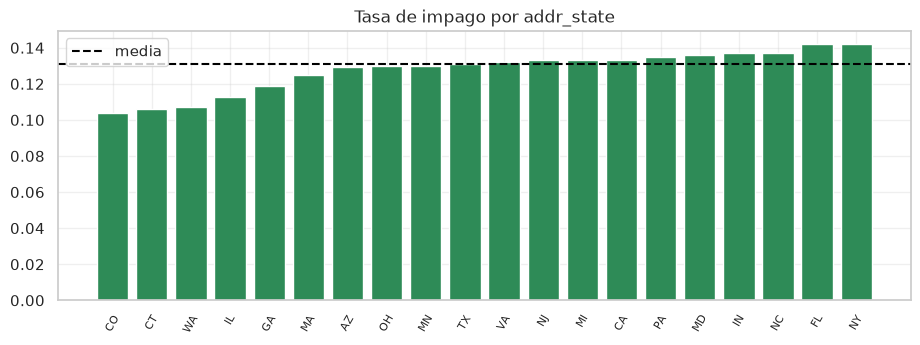

In [ ]:
analizar_categorica("addr_state")                  # estado de residencia del prestatario en EE.UU.

--- region_code: 10 categorías, 0.00% nulos ---
             prestamos  tasa_impago  % cartera
region_code                                   
9               246341       0.1283    17.9894
3               188883       0.1376    13.7934
1               165157       0.1399    12.0608
7               150606       0.1368    10.9982
2               135213       0.1285     9.8741
0               122643       0.1206     8.9562
4               116367       0.1329     8.4978
8               102097       0.1251     7.4558
6                91935       0.1200     6.7137
5                50129       0.1254     3.6607


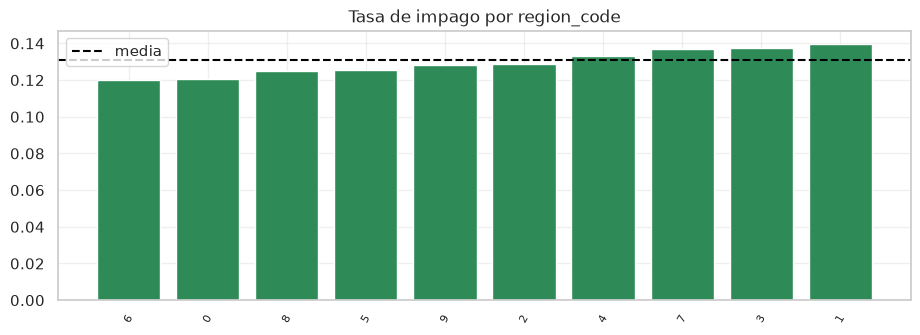

In [ ]:
analizar_categorica("region_code")                 # código numérico de zonificación geográfica territorial

--- issue_date_month: 12 categorías, 0.00% nulos ---
                  prestamos  tasa_impago  % cartera
issue_date_month                                   
Oct                  138102       0.1242    10.0851
Jul                  130052       0.1360     9.4972
Nov                  123675       0.1171     9.0315
Aug                  122204       0.1253     8.9241
Mar                  118278       0.1431     8.6374
Dec                  116941       0.1177     8.5398
May                  109622       0.1329     8.0053
Apr                  109139       0.1399     7.9700
Jun                  107643       0.1305     7.8608
Jan                  100511       0.1436     7.3399
Sep                  100439       0.1215     7.3347
Feb                   92765       0.1420     6.7743


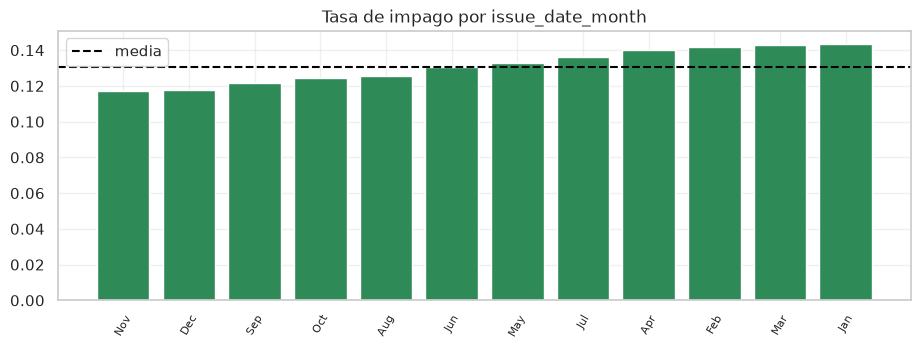

In [ ]:
analizar_categorica("issue_date_month")            # mes calendario de formalización y emisión del préstamo

**Lectura.**
- **Plazo**: los préstamos a 60 meses impagan bastante más (18% frente a 11%).
- **`grade`** ordena el riesgo de forma casi perfecta (del 1.8% en A1 a más del 23% en D5). Es el modelo de Lending Club, y por eso está prohibido: usarlo sería copiar su nota.
- **Vivienda**: los que pagan alquiler impagan más que los que tienen hipoteca (15% frente a 11.5%).
- **Verificación de ingresos**: curiosamente, los "Verified" impagan más (17%) que los "Not Verified" (9%). Lending Club verifica sobre todo a los clientes que le parecen más arriesgados: es una señal del propio proceso de concesión.
- **Finalidad**: `small_business` y `educational` son las de más riesgo (~20%); `car` y `credit_card`, las de menos.
- **`initial_list_status`** y **`disbursement_method`** también separan bien (DirectPay: 2.5% de impago, aunque solo es el 3% de la cartera).
- `addr_state`, `region_code` y el mes de emisión tienen diferencias pequeñas. Nos quedamos con `addr_state` (más detalle) y descartamos `region_code`, que es una agrupación de los estados.
- `emp_length`: la antigüedad laboral importa poco, salvo el **nulo** (16% de impago frente al 13%): no declarar la antigüedad es una señal.

#### `emp_title`: la profesión


Es texto libre que escribe el propio cliente, con cientos de miles de valores distintos. Veamos las más frecuentes.

Valores distintos: 285,745 | nulos: 6.94%


--- emp_title: 285,745 categorías, 6.94% nulos ---
                          prestamos  tasa_impago  % cartera
emp_title                                                  
(nulo)                        95037       0.1527     6.9402
manager                       27900       0.1386     2.0374
teacher                       27881       0.1187     2.0360
owner                         20441       0.1443     1.4927
registered nurse              14129       0.1207     1.0318
supervisor                    13509       0.1475     0.9865
driver                        13493       0.1706     0.9853
sales                         11602       0.1493     0.8473
rn                            10584       0.1218     0.7729
project manager                8486       0.1083     0.6197
office manager                 8405       0.1198     0.6138
general manager                8116       0.1448     0.5927
truck driver                   7634       0.1753     0.5575
director                       6564       0.0990 

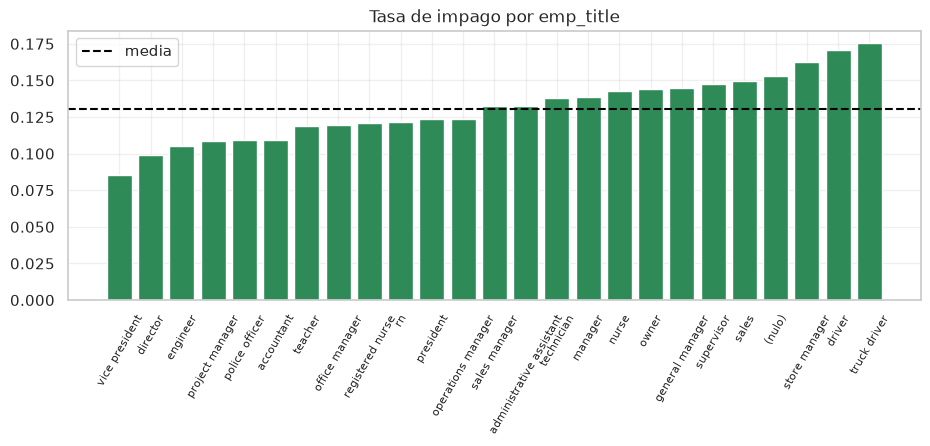

In [ ]:
profesion = train["emp_title"].str.lower().str.strip() # estandarizar texto a minúsculas y sin espacios residuales
print(f"Valores distintos: {profesion.nunique():,} | nulos: {100 * profesion.isna().mean():.2f}%") # cardinalidad y nulos
analizar_categorica("emp_title", datos=train.assign(emp_title=profesion), top=25) # explorar top 25 profesiones más frecuentes

**Lectura.**
- Hay casi **286,000 profesiones distintas** solo en train, escritas a mano ("rn" y "registered nurse" son lo mismo).
- Aun así hay señal: los conductores (*driver*, *truck driver*) impagan un 17%; los abogados, directores o vicepresidentes, menos del 10%. Y no declarar profesión (nulo) sube el impago al 15%.
- Nos quedaremos con las profesiones más frecuentes y agruparemos el resto.

#### **Los valores nulos**

Hay dos tipos de nulos y no se tratan igual:

- **Nulos que significan "nunca"**: en las variables `mths_since_...` (meses desde el último retraso), un nulo quiere decir que el cliente **nunca** ha tenido ese evento. No es un dato perdido: es información, y de la buena.
- **Nulos estructurales**: un bloque de variables que aparece vacío a la vez en el ~40% de los préstamos. Veamos por qué.

In [ ]:
nulos = (100 * train[ORIGINACION].isna().mean()).sort_values(ascending=False) # % de valores nulos ordenado de mayor a menor
nulos[nulos > 0].round(2).to_frame("% nulos")           # presentar solo columnas con valores ausentes en formato tabla

,% nulos
mths_since_recent_bankcard_delinq,76.7700
mths_since_recent_revol_delinq,66.9900
mths_since_last_delinq,50.9700
mths_since_last_installment_acc_op,42.3100
bal_to_cred_lim,40.4600
num_open_trades_in_6mths,40.4600
num_installment_acc_op_in_24mths,40.4600
num_rev_trades_op_in_12mths,40.4600
num_inq,40.4600
num_rev_trades_op_in_24mths,40.4600


In [ ]:
# ¿En qué años falta el bloque de historial?
# Definición del bloque de variables de buró de crédito introducidas tardíamente en la plataforma
bloque_buro = ["num_inq", "num_open_trades_in_6mths", "num_installment_acc_op_in_12mths",
               "num_installment_acc_op_in_24mths", "num_rev_trades_op_in_12mths",
               "num_rev_trades_op_in_24mths", "max_bal_owed", "bal_to_cred_lim"]
sin_buro = train["num_inq"].isna()                      # indicador de registro sin bloque de buró
print("¿Faltan todas a la vez?", (train[bloque_buro].isna().sum(axis=1).isin([0, len(bloque_buro)])).mean().round(4)) # co-ocurrencia

# Comparar tasas de impago de clientes con y sin historial crediticio detallado por año
tabla = pd.DataFrame({
    "% sin datos de historial": 100 * sin_buro.groupby(train["issue_date_year"]).mean(), # prevalencia de nulos por año
    "tasa impago con historial": train[~sin_buro].groupby("issue_date_year")["y"].mean(), # tasa de mora con datos
    "tasa impago sin historial": train[sin_buro].groupby("issue_date_year")["y"].mean(),  # tasa de mora sin datos
})
tabla.round(3)                                          # visualización comparativa de riesgo

¿Faltan todas a la vez? 0.9999


,% sin datos de historial,tasa impago con historial,tasa impago sin historial
issue_date_year,,,
2007,100.0000,NaN,0.2800
2008,100.0000,NaN,0.1960
2009,100.0000,NaN,0.1380
2010,100.0000,NaN,0.1460
2011,100.0000,NaN,0.1530
2012,100.0000,NaN,0.1620
2013,100.0000,NaN,0.1560
2014,100.0000,NaN,0.1760
2015,94.9310,0.1860,0.1820


**Lectura.**
- El bloque de 8 variables de historial (consultas, aperturas, saldos...) falta **entero y a la vez** (99.99% de las veces): no es un fallo aleatorio.
- Falta en **todos los préstamos anteriores a 2015** y en el 95% de los de 2015. A partir de 2016 está siempre. Lending Club empezó a guardar esa información más tarde.
- Por eso la tasa de impago de los nulos (17%) es alta: son préstamos antiguos, que ya han tenido tiempo de impagar. El nulo, en realidad, nos está diciendo "préstamo antiguo".
- Decisión: crearemos un indicador `sin_datos_buro` y rellenaremos con la mediana. No eliminamos filas (las reglas lo prohíben) ni variables (a partir de 2016 tienen buena señal).

Este tratamiento de nulos es particularmente interesante porque es lo que te encontrarás en la práctica muchas veces. En riesgo de crédito por ejemplo, es muy difícil que te permitan eliminar observaciones y menos cuando se ven este tipo de patrones, de ahí que haya insistido en mantener un enfoque lo más real posible para este proyecto.

#### **Correlaciones entre variables numéricas**

Si dos variables cuentan casi lo mismo, a la regresión logística se pude "romprer" (coeficientes inestables) y no aporta información nueva. Usamos la correlación de Spearman, que es robusta a valores extremos, sobre una muestra de 200,000 préstamos para que sea rápido.

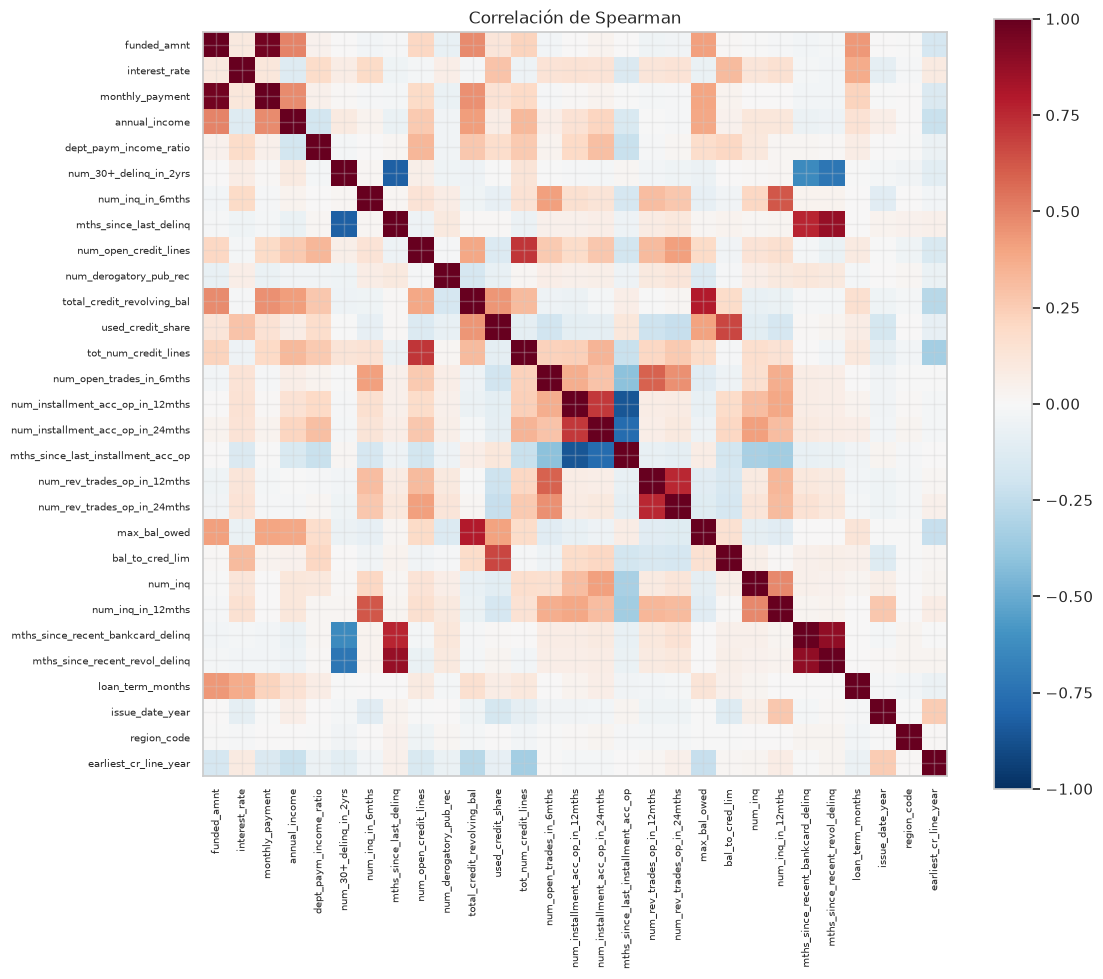

,variable 1,variable 2,correlación
8,num_installment_acc_op_in_12mths,mths_since_last_installment_acc_op,-0.8570
1,num_30+_delinq_in_2yrs,mths_since_last_delinq,-0.8200
9,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,-0.7680
2,num_30+_delinq_in_2yrs,mths_since_recent_revol_delinq,-0.7220
7,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,0.7040
5,num_open_credit_lines,tot_num_credit_lines,0.7150
10,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,0.7530
3,mths_since_last_delinq,mths_since_recent_bankcard_delinq,0.7610
6,total_credit_revolving_bal,max_bal_owed,0.7940
4,mths_since_last_delinq,mths_since_recent_revol_delinq,0.8690


In [ ]:
numericas = train[ORIGINACION].select_dtypes("number").columns # extraer nombres de columnas numéricas de originación
corr = train[numericas].sample(200_000, random_state=SEED).corr(method="spearman") # matriz de correlación no paramétrica

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)        # mapa de calor con escala divergente de -1 a +1
plt.colorbar()                                          # barra indicadora de intensidad
plt.xticks(range(len(numericas)), numericas, rotation=90, fontsize=7) # etiquetas eje X
plt.yticks(range(len(numericas)), numericas, fontsize=7)              # etiquetas eje Y
plt.title("Correlación de Spearman")
plt.show()

# Identificar pares fuertemente correlacionados (|rho| > 0.70) para controlar multicolinealidad
pares = []
for i, a in enumerate(numericas):
    for b in numericas[i + 1:]:
        if abs(corr.loc[a, b]) > 0.7:                   # umbral conservador de alta dependencia monotónica
            pares.append((a, b, round(corr.loc[a, b], 3)))
pd.DataFrame(pares, columns=["variable 1", "variable 2", "correlación"]).sort_values("correlación") # ordenar pares

**Lectura.**
- `funded_amnt` y `monthly_payment`: **0.97**. La cuota se calcula a partir del importe, el tipo y el plazo. Nos quedamos con el importe.
- Las variables de "meses desde el último retraso" están muy correlacionadas entre sí (0.76-0.89) y con el número de retrasos. Es lógico: miden lo mismo con distintos productos.
- Las ventanas de 12 y 24 meses (consultas, aperturas) se solapan: la de 12 meses está *dentro* de la de 24. Quitaremos `num_rev_trades_op_in_12mths`.
- El resto de pares altos los mantenemos: aportan matices y LightGBM no tiene problema con variables correlacionadas.

####  **La pérdida: EAD y LGD de los impagados**

Ahora miramos lo que tendrán que predecir los modelos de EAD y LGD. Trabajamos solo con los impagados de train.

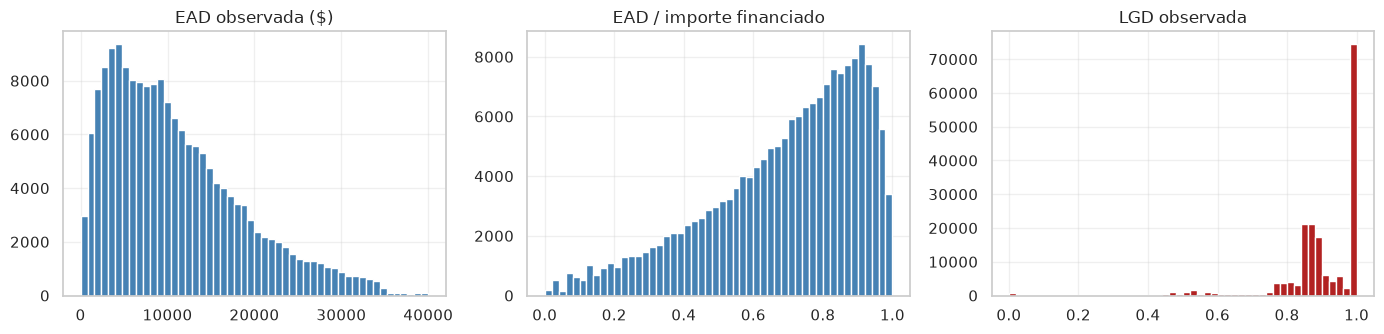

LGD media: 0.901 | % con LGD = 100%: 39.6%
EAD / importe medio: 0.690


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(impagados["ead_real"], bins=50, color="steelblue") # distribución de la exposición en dólares al impago
ax[0].set_title("EAD observada ($)")
ax[1].hist(impagados["ccf_real"], bins=50, color="steelblue") # distribución del ratio EAD sobre funded_amnt
ax[1].set_title("EAD / importe financiado")
ax[2].hist(impagados["lgd_real"].dropna(), bins=50, color="firebrick") # distribución de la severidad porcentual
ax[2].set_title("LGD observada")
plt.tight_layout()
plt.show()

# Resumen numérico de métricas de pérdida sobre la muestra de impagados
print(f"LGD media: {impagados['lgd_real'].mean():.3f} | % con LGD = 100%: {100 * (impagados['lgd_real'] > 0.999).mean():.1f}%")
print(f"EAD / importe medio: {impagados['ccf_real'].mean():.3f}")

                 impagados  ead_sobre_importe  lgd_media  pct_sin_recobros
issue_date_year                                                           
2007                   102             0.6490     0.9100            0.1570
2008                   301             0.6490     0.9000            0.2820
2009                   470             0.6360     0.9060            0.0960
2010                  1151             0.6430     0.9000            0.0700
2011                  2138             0.6510     0.9050            0.0470
2012                  5577             0.6290     0.8870            0.0570
2013                 13487             0.6240     0.8690            0.1540
2014                 26620             0.6330     0.8720            0.2720
2015                 49025             0.6590     0.8830            0.3210
2016                 45374             0.6910     0.9080            0.4140
2017                 26766             0.7900     0.9450            0.6140
2018                  801

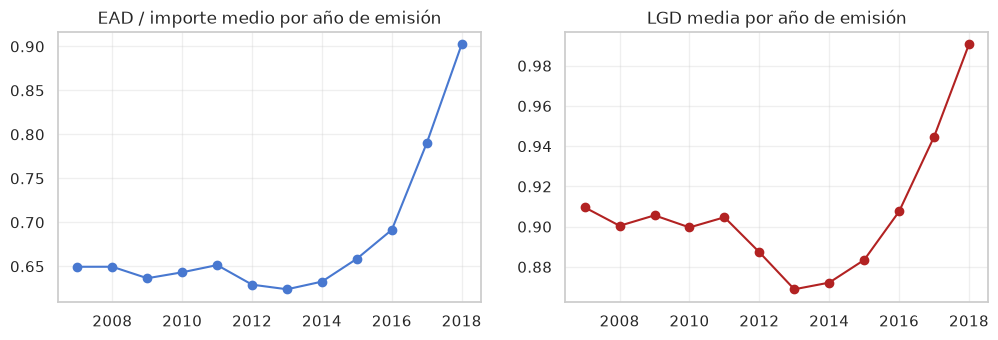

In [ ]:
# EAD y LGD según el año de emisión y el plazo
# Agregación para contrastar la madurez del crédito con la recuperación lograda
tabla = impagados.groupby(["issue_date_year"]).agg(
    impagados=("y", "size"),                            # número de préstamos fallidos
    ead_sobre_importe=("ccf_real", "mean"),             # % medio de saldo pendiente al default
    lgd_media=("lgd_real", "mean"),                     # severidad media observada
    pct_sin_recobros=("recobros_real", lambda s: (s < 1).mean()), # proporción de casos con 0 dólares recuperados
)
print(tabla.round(3).to_string())
print()
print(impagados.groupby("loan_term_months")[["ccf_real", "lgd_real"]].mean().round(3)) # desagregación por plazo (36 vs 60 m)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(tabla.index, tabla["ead_sobre_importe"], "o-") # evolución del CCF medio a lo largo de las cosechas
ax[0].set_title("EAD / importe medio por año de emisión")
ax[1].plot(tabla.index, tabla["lgd_media"], "o-", color="firebrick") # evolución de la LGD media por cosecha
ax[1].set_title("LGD media por año de emisión")
plt.show()

In [ ]:
# ¿Qué variables de originación se relacionan con la EAD y la LGD?
# Cálculo de correlación monotónica de Spearman frente a los targets continuos de severidad y exposición
relacion = pd.DataFrame({
    "corr. con EAD/importe": impagados[numericas].corrwith(impagados["ccf_real"], method="spearman"), # relación con % EAD
    "corr. con LGD": impagados[numericas].corrwith(impagados["lgd_real"], method="spearman"),         # relación con % LGD
})
# Ordenar por magnitud absoluta de relación con la EAD
relacion.reindex(relacion["corr. con EAD/importe"].abs().sort_values(ascending=False).index).round(3).head(12)

,corr. con EAD/importe,corr. con LGD
loan_term_months,0.3130,-0.0020
interest_rate,0.3100,-0.0670
issue_date_year,0.2720,0.3180
funded_amnt,0.1680,-0.0170
num_inq_in_12mths,0.1480,0.0750
monthly_payment,0.1260,-0.0290
earliest_cr_line_year,0.0810,0.0710
annual_income,0.0780,-0.0260
num_installment_acc_op_in_24mths,0.0760,-0.0650
mths_since_last_installment_acc_op,-0.0740,0.0580


**Lectura.**
- **EAD / importe**: va de 0 a 1 y está repartida (media 0.69). Depende sobre todo del **plazo** (0.64 a 36 meses frente a 0.78 a 60), del **tipo de interés** y del **año de emisión**: un préstamo de 2018 que ya ha impagado lo hizo enseguida y debía casi todo (0.90).
- **LGD**: muy concentrada cerca de 1. Casi el **40%** de los impagados tiene LGD = 100% (no se recobra nada). La variable que más se relaciona con ella es, otra vez, el **año de emisión**: los impagos de 2017-2018 todavía no han tenido tiempo de recobrar (el 93% de los de 2018 tiene recobros nulos).
- El resto de variables de originación casi no se relacionan con la LGD (correlaciones por debajo de 0.08). **La LGD va a ser difícil de predecir**; la EAD, algo menos.

Los valores tan altos de EAD y LGD en los años más recientes, al igual que con la PD, era de esperar y se justifica por la ventana temporal que han tenido los créditos. Respecto a la EAD, para un default en 2018 es más probable que haya pagado menos que defaults más antiguos. Con la LGD ocurre lo mismo pero al revés: al llevar menos tiempo en default, ha tenido menos tiempo para hacer repayments y disminuir su LGD.

#### **Resumen del análisis exploratorio**

**Lo que nos llevamos a la modelización:**

1. **PD**: las variables con más señal son el tipo de interés, el plazo, el DTI, los ingresos, las consultas y aperturas recientes, la verificación, la vivienda y el método de desembolso. El año de emisión importa mucho por la censura. Esto concuerda con lo que solemos encontrar en problemas de riesgo de crédito. 
2. **EAD y LGD**: dependen sobre todo de la **madurez** del préstamo (año de emisión) y del plazo. Construiremos variables de madurez.
3. **Nulos**: no se imputan a ciegas. En las `mths_since_...` significan "nunca" (indicador + valor alto); en el bloque de buró significan "préstamo antiguo" (indicador + mediana).
4. **Variables a crear**: años de historial de crédito, madurez del préstamo y ratios sobre ingresos.
5. **Variables a quitar**: `monthly_payment`, `region_code`, `num_rev_trades_op_in_12mths` (redundantes) y, por supuesto, las de desempeño y `grade`.
6. **Outliers**: distribuciones asimétricas (colas muy largas) en ingresos y saldos. Las recortamos (sin borrar filas) para la logística.

## **🔧 Semana 2 · Saneamiento de la cartera y exploración de señales**


Una vez completado el análisis exploratorio de la cartera en la Semana 1, entramos en la fase de **saneamiento de datos e ingeniería de variables**. El objetivo es transformar las variables en bruto en señales predictivas limpias y de alto valor para los modelos de PD, EAD y LGD, manteniendo un control riguroso sobre la fuga de datos (*Data Leakage*).

**Regla de oro anti-fuga:** todo lo que se calcula a partir de los datos (categoría de imputación de antigüedad laboral, *target encoding* out-of-fold de profesiones, fecha de corte de la cartera, máximos de `mths_since_...`, medianas de imputación y límites de *winsorización* al percentil 99.5) **se aprende exclusivamente sobre `train`** y posteriormente se propaga de forma determinista mediante `for datos in [train, val, test]`. De este modo garantizamos una evaluación completamente ciega y honesta sobre los conjuntos de validación y test.

### **2.1 🛠️ `emp_length` y `emp_title`: antigüedad laboral y profesión con *Target Encoding Out-of-Fold***


1. **`emp_length` (de texto a número):** `"< 1 year"` pasa a `0`, `"10+ years"` pasa a `10`, etc. Los nulos se marcan con el indicador binario `emp_length_nulo` y se imputan en `emp_length_anios` con la categoría de mayor tasa de impago en `train` (`0` años).
2. **`emp_title` (normalización y *Target Encoding* suavizado *Out-of-Fold*):**
   - Limpiamos el texto (minúsculas, quitamos puntuación y unificamos abreviaturas frecuentes como `rn` $\rightarrow$ `registered nurse`, `sr` $\rightarrow$ `senior`, `mgr` $\rightarrow$ `manager`).
   - En lugar de quedarnos solo con las 30 profesiones más frecuentes (que dejarían más de la mitad de la cartera en `"otros"`), sustituimos cada profesión por su tasa de impago suavizada con la media global ($m = 100$ préstamos virtuales):
     $$TE = \frac{\text{impagos} + 100 \cdot \bar{y}}{\text{préstamos} + 100}$$
   - Para evitar fuga dentro de `train`, calculamos `profesion_te` **out-of-fold** con 5 *folds* (`KFold(5, shuffle=True, random_state=SEED)`): cada préstamo de `train` recibe la tasa calculada con los otros 4 trozos. En `val` y `test` aplicamos las tasas aprendidas con todo `train`.

In [ ]:
# --- emp_length: conversión a años e imputación informada aprendida en train ---
# Mapeo ordinal: transformar categorías textuales a años de antigüedad laboral continua
mapa_emp_length = {
    "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5,
    "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10
}

# Aprendizaje en Train: tasa de default por año de experiencia laboral
anios_train = train["emp_length"].map(mapa_emp_length)
tasa_por_anios = train.groupby(anios_train)["y"].mean() # tasa media de impago por tramo
valor_imputacion = tasa_por_anios.idxmax()   # categoría con más impago aprendida en train (0 años)

# Aplicar transformación e imputación en los 3 conjuntos de forma determinista
for datos in [train, val, test]:
    datos["emp_length_nulo"]  = datos["emp_length"].isna().astype(int)              # flag de valor ausente
    datos["emp_length_anios"] = datos["emp_length"].map(mapa_emp_length).fillna(valor_imputacion) # imputar con peor tasa

print(f"Categoría con mayor tasa de impago en train (usada para imputar nulos): {valor_imputacion:g} años")

# --- emp_title: agrupación top 30 y Target Encoding suavizado Out-of-Fold ---
def limpiar_profesion(serie):
    """Limpia el texto convirtiendo a minúsculas y removiendo espacios extremos."""
    return serie.str.lower().str.strip()

# Identificar las 30 profesiones más frecuentes exclusivamente en train
top_profesiones = limpiar_profesion(train["emp_title"]).value_counts().head(30).index

# Agrupar categorías minoritarias en 'otros' y nulos en 'desconocido'
for datos in [train, val, test]:
    profesion = limpiar_profesion(datos["emp_title"])
    datos["profesion"] = np.where(profesion.isin(top_profesiones), profesion, "otros") # agrupar categorías fuera del top
    datos.loc[profesion.isna(), "profesion"] = "desconocido"                           # imputar valor explícito a nulos

# Diccionario de normalización de abreviaturas laborales comunes
ABREVIATURAS = {
    "rn": "registered nurse", "lpn": "licensed practical nurse", "sr": "senior",
    "jr": "junior", "mgr": "manager", "asst": "assistant", "vp": "vice president"
}
SUAVIZADO  = 100                                        # peso m-estimate para regularizar categorías poco frecuentes
N_FOLDS_TE = 5                                          # 5 particiones para evitar data leakage en train

def normalizar_profesion(serie):
    """Normaliza expresiones textuales sustituyendo abreviaturas frecuentes."""
    palabras = serie.str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split()
    texto = palabras.apply(lambda p: " ".join(ABREVIATURAS.get(w, w) for w in p) if isinstance(p, list) else None)
    return texto.where(texto != "").fillna("desconocido")

def tasa_suavizada(profesion, y):
    """Calcula la tasa de impago regularizada por Target Encoding con suavizado bayesiano."""
    media = y.mean()                                    # tasa global previa
    estadisticos = y.groupby(profesion).agg(["sum", "count"]) # suma de eventos y recuento por categoría
    return (estadisticos["sum"] + SUAVIZADO * media) / (estadisticos["count"] + SUAVIZADO), media

prof_train = normalizar_profesion(train["emp_title"])   # serie de profesiones normalizada en train
print(f"Profesiones distintas en train: {train['emp_title'].str.lower().str.strip().nunique():,} sin normalizar | "
      f"{prof_train.nunique():,} normalizadas")

# Train: generación de Target Encoding mediante validación cruzada out-of-fold (cero fuga)
te_train = np.zeros(len(train))
for idx_ajuste, idx_aplicar in KFold(N_FOLDS_TE, shuffle=True, random_state=SEED).split(train):
    tasas, media = tasa_suavizada(prof_train.iloc[idx_ajuste], train["y"].iloc[idx_ajuste]) # ajustar en el fold de train
    te_train[idx_aplicar] = prof_train.iloc[idx_aplicar].map(tasas).fillna(media).values   # predecir en el fold de validación
train["profesion_te"] = te_train                        # registrar feature codificada en train

# Validación y test: aplicar tasas globales consolidadas de todo train (cero fuga)
tasas_train, media_train = tasa_suavizada(prof_train, train["y"])
for datos in [val, test]:
    datos["profesion_te"] = normalizar_profesion(datos["emp_title"]).map(tasas_train).fillna(media_train).values

# Auditoría de discriminación univariante del target encoding
print(f"AUC de profesion_te sola -> train (out-of-fold): {roc_auc_score(train['y'], train['profesion_te']):.4f} | "
      f"validación: {roc_auc_score(val['y'], val['profesion_te']):.4f}")

Categoría con mayor tasa de impago en train (usada para imputar nulos): 8 años


Profesiones distintas en train: 285,745 sin normalizar | 269,460 normalizadas


AUC de profesion_te sola -> train (out-of-fold): 0.5500 | validación: 0.5523


### **2.2 🕰️ Centinela DTI, antigüedad crediticia, madurez, ratios sobre ingresos e importes redondos**


Construimos las variables financieras y temporales de originación que concentran la mayor señal predictiva en PD, EAD y LGD:
1. **Valor centinela `-1` en `dept_paym_income_ratio`:** un ratio deuda/ingresos negativo es un código de "sin dato"; lo convertimos en `NaN` para que reciba la imputación por mediana de `train`.
2. **Antigüedad del historial de crédito (`antiguedad_credito_anios`):** años exactos (con meses incluidos) desde la apertura de la primera línea de crédito (`earliest_cr_line`) hasta la emisión del préstamo (`issue_date`).
3. **Madurez del préstamo (`meses_en_cartera` y `pct_plazo_transcurrido`):** meses transcurridos desde la emisión hasta la fecha de corte de `train` (`12/2018`) y fracción del plazo contractual ya transcurrida. Capturan limpiamente la censura por la derecha tanto en la probabilidad de impago como en el saldo pendiente (EAD) y los recobros (LGD).
4. **Ratios sobre los ingresos:** `prestamo_sobre_ingresos`, `cuota_sobre_ingresos` y `revolving_sobre_ingresos` (con suelo de $1,000 en ingresos anuales). Separan el riesgo mucho mejor que el ingreso bruto aislado.
5. **Indicadores de importe redondo (`importe_redondo_500`, `importe_redondo_5000`):** los préstamos con importes no redondos impagan significativamente más (17.2% frente a 10.6–12.1%) dentro de todos los tramos de importe.

In [ ]:
# --- Ratio deuda/ingresos: el valor centinela -1 pasa a NaN ---
for datos in [train, val, test]:
    datos.loc[datos["dept_paym_income_ratio"] < 0, "dept_paym_income_ratio"] = np.nan # -1 indica valor no disponible
print("Nulos en dept_paym_income_ratio (train) tras limpiar -1:", train["dept_paym_income_ratio"].isna().sum())

# --- Antigüedad del historial de crédito (en años con precisión mensual) ---
meses = {
    "Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "Jun": 6,
    "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12
}

for datos in [train, val, test]:
    mes_emision       = datos["issue_date_month"].map(meses)       # mes de concesión en formato entero
    mes_primera_linea = datos["earliest_cr_line_month"].map(meses) # mes de apertura de la primera línea de crédito
    datos["mes_emision"] = mes_emision                             # almacenar mes como feature numérica
    datos["antiguedad_credito_anios"] = (                          # diferencia temporal en años decimales
        (datos["issue_date_year"] - datos["earliest_cr_line_year"]) * 12
        + (mes_emision - mes_primera_linea)
    ) / 12

# --- Madurez del préstamo (aprendiendo la fecha de corte en train) ---
anio_corte = train["issue_date_year"].max()                        # año más reciente observado en train
mes_corte  = train.loc[train["issue_date_year"] == anio_corte, "mes_emision"].max() # mes máximo del último año
print(f"Fecha de corte aprendida en train: {mes_corte}/{anio_corte}")

for datos in [train, val, test]:
    datos["meses_en_cartera"]       = (anio_corte - datos["issue_date_year"]) * 12 + (mes_corte - datos["mes_emision"]) # antigüedad en cartera
    datos["pct_plazo_transcurrido"] = (datos["meses_en_cartera"] / datos["loan_term_months"]).clip(upper=1)              # ratio de vida amortizada

# --- Ratios sobre los ingresos ---
for datos in [train, val, test]:
    ingresos = datos["annual_income"].clip(lower=1000)             # suelo prudencial en 1.000$ para evitar división por cero
    datos["prestamo_sobre_ingresos"]  = datos["funded_amnt"] / ingresos                  # ratio deuda principal vs ingreso
    datos["cuota_sobre_ingresos"]     = 12 * datos["monthly_payment"] / ingresos         # carga de cuota anual vs ingreso
    datos["revolving_sobre_ingresos"] = datos["total_credit_revolving_bal"] / ingresos   # saldo en tarjetas vs ingreso

# --- Importes redondos: efecto psicológico del redondeo ---
for datos in [train, val, test]:
    datos["importe_redondo_500"]  = (datos["funded_amnt"] % 500 == 0).astype(int)       # flag si es múltiplo de 500 $
    datos["importe_redondo_5000"] = (datos["funded_amnt"] % 5000 == 0).astype(int)      # flag si es múltiplo de 5.000 $

# Comprobación del efecto de redondez por tramo de importe en train
tramos_importe = pd.cut(train["funded_amnt"], [0, 5000, 10000, 15000, 20000, 25000, 40000]) # bins de importe
print("Tasa de impago en train según si el importe es múltiplo de 500 $:")
display(
    train.groupby([tramos_importe, train["importe_redondo_500"]], observed=True)["y"]
         .mean().unstack().rename(columns={0: "no redondo", 1: "múltiplo de 500"}).round(4) # tabla cruzada de mora
)

Nulos en dept_paym_income_ratio (train) tras limpiar -1: 1
Fecha de corte aprendida en train: 12/2018

Tasa de impago en train según si el importe es múltiplo de 500 $:


importe_redondo_500,no redondo,múltiplo de 500
funded_amnt,,
"(0, 5000]",0.1166,0.0983
"(5000, 10000]",0.1477,0.1056
"(10000, 15000]",0.1939,0.1192
"(15000, 20000]",0.2100,0.1292
"(20000, 25000]",0.2128,0.1285
"(25000, 40000]",0.1956,0.1299


### **2.3 🕳️ Tratamiento de nulos (`nunca_...` y `sin_datos_buro`), Winsorización P99.5 y Selección Final de Variables**


1. **Variables `mths_since_...` (el nulo significa "nunca"):** creamos los indicadores binarios `nunca_mths_since_last_delinq`, `nunca_mths_since_recent_bankcard_delinq` y `nunca_mths_since_recent_revol_delinq`, y rellenamos el nulo con el **máximo de `train`** ("nunca" se parece más a "hace muchísimo tiempo" que a la mediana).
2. **Bloque de buró y resto de nulos:** creamos el indicador `sin_datos_buro` (`1` si `num_inq` es nulo) y rellenamos todos los nulos numéricos restantes con la **mediana de `train`**.
3. **Valores extremos (*Winsorización* al percentil 99.5 de `train`):** recortamos las colas derechas de las 12 variables con asimetría severa al percentil 99.5 aprendido en `train` (imprescindible para la regresión logística e inocuo para los árboles).
4. **Contrato final de 45 variables (`VARIABLES`):** descartamos las variables de desempeño, `grade`, los textos y fechas brutas ya transformados, y las redundantes (`monthly_payment` por correlación de 0.97 con `funded_amnt`, `region_code` por ser agrupación de `addr_state`, y `num_rev_trades_op_in_12mths` por estar contenida en la ventana de 24 meses).

In [ ]:
# --- Variables "meses desde...": indicador 'nunca_' + imputación con el máximo de train ---
vars_meses_desde = [
    "mths_since_last_delinq",                           # meses transcurridos desde última morosidad general
    "mths_since_recent_bankcard_delinq",                # meses transcurridos desde última mora en tarjeta bancaria
    "mths_since_recent_revol_delinq",                   # meses transcurridos desde última mora en crédito revolving
]
maximos = {col: train[col].max() for col in vars_meses_desde} # máximos históricos observados en train
print("Máximos aprendidos en train para 'mths_since_...':", maximos)

# Imputar valor máximo histórico (máximo tiempo sin eventos negativos) y flag explicativo
for datos in [train, val, test]:
    for col in vars_meses_desde:
        datos["nunca_" + col] = datos[col].isna().astype(int)       # flag: 1 si nunca ocurrió mora, 0 en caso contrario
        datos[col] = datos[col].fillna(maximos[col])                # sustitución del NaN por el valor máximo de train

# --- Bloque de buró y resto de nulos: indicador 'sin_datos_buro' + mediana de train ---
for datos in [train, val, test]:
    datos["sin_datos_buro"] = datos["num_inq"].isna().astype(int)   # indicador de cliente sin bloque de buró

con_nulos = [
    c for c in train.columns
    if train[c].isna().any()
    and pd.api.types.is_numeric_dtype(train[c])
    and c not in ["ccf_real", "lgd_real"]               # excluir targets observados de la imputación
]
medianas = train[con_nulos].median()                    # calcular medianas robustas aprendidas en train
print("Imputación por mediana de train en restantes con nulos:")
print(medianas.round(2).to_string())

for datos in [train, val, test]:
    datos[con_nulos] = datos[con_nulos].fillna(medianas)            # rellenar con las medianas de train

# --- 6.9 Valores extremos: Winsorización al percentil 99.5 de train ---
vars_recortar = [
    "annual_income", "total_credit_revolving_bal", "max_bal_owed",
    "prestamo_sobre_ingresos", "cuota_sobre_ingresos", "revolving_sobre_ingresos",
    "num_open_credit_lines", "tot_num_credit_lines",
    "num_30+_delinq_in_2yrs", "num_derogatory_pub_rec",
    "num_inq_in_12mths", "num_inq",
]
limites = train[vars_recortar].quantile(0.995)          # percentil 99.5 superior aprendido en train
print("Límites de Winsorización (P99.5 de train):")
print(limites.round(2).to_string())

for datos in [train, val, test]:
    for col in vars_recortar:
        datos[col] = datos[col].clip(upper=limites[col])            # capping superior contra colas pesadas

# --- 6.10 Contrato final de 45 variables (39 numéricas + 6 categóricas) ---
VARIABLES_NUM = [
    "funded_amnt", "interest_rate", "loan_term_months", "annual_income", "dept_paym_income_ratio",
    "emp_length_anios", "emp_length_nulo",
    "total_credit_revolving_bal", "used_credit_share", "bal_to_cred_lim", "max_bal_owed",
    "num_open_credit_lines", "tot_num_credit_lines",
    "num_30+_delinq_in_2yrs", "num_derogatory_pub_rec",
    "mths_since_last_delinq", "mths_since_recent_bankcard_delinq", "mths_since_recent_revol_delinq",
    "nunca_mths_since_last_delinq", "nunca_mths_since_recent_bankcard_delinq", "nunca_mths_since_recent_revol_delinq",
    "num_inq_in_6mths", "num_inq_in_12mths", "num_inq", "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths", "num_rev_trades_op_in_24mths",
    "mths_since_last_installment_acc_op", "sin_datos_buro",
    "antiguedad_credito_anios", "meses_en_cartera", "pct_plazo_transcurrido",
    "prestamo_sobre_ingresos", "cuota_sobre_ingresos", "revolving_sobre_ingresos",
    "profesion_te", "importe_redondo_500", "importe_redondo_5000",
]
VARIABLES_CAT = [
    "home_ownership_status", "verification_status", "loan_purpose",
    "initial_list_status", "disbursement_method", "addr_state",
]
VARIABLES = VARIABLES_NUM + VARIABLES_CAT

# Guardias finales anti-fuga y verificación de cero nulos en todas las particiones
assert not set(VARIABLES) & set(DESEMPENO + PROHIBIDAS + [TARGET_COL]) # sin solapes prohibidos
print()
for nombre, datos in [("train", train), ("val", val), ("test", test)]:
    n_nulos = datos[VARIABLES].isna().sum().sum()
    print(f"✅ {nombre:<5}: {datos.shape[0]:>9,} filas | {len(VARIABLES)} variables | nulos: {n_nulos}")
    assert n_nulos == 0                                 # verificar ausencia total de nulos en el espacio predictivo

Máximos aprendidos en train para 'mths_since_...': {'mths_since_last_delinq': np.float64(226.0), 'mths_since_recent_bankcard_delinq': np.float64(202.0), 'mths_since_recent_revol_delinq': np.float64(202.0)}



Imputación por mediana de train en restantes con nulos:
dept_paym_income_ratio                  17.6000
num_open_trades_in_6mths                 1.0000
num_installment_acc_op_in_12mths         0.0000
num_installment_acc_op_in_24mths         1.0000
mths_since_last_installment_acc_op      13.0000
num_rev_trades_op_in_12mths              1.0000
num_rev_trades_op_in_24mths              2.0000
max_bal_owed                         4,403.0000
bal_to_cred_lim                         58.0000
num_inq                                  0.0000

Límites de Winsorización (P99.5 de train):
annual_income                350,000.0000
total_credit_revolving_bal   137,147.9000
max_bal_owed                  25,785.0000
prestamo_sobre_ingresos            0.5600
cuota_sobre_ingresos               0.2100
revolving_sobre_ingresos           1.1700
num_open_credit_lines             33.0000
tot_num_credit_lines              66.0000
num_30+_delinq_in_2yrs             5.0000
num_derogatory_pub_rec             3.0000


✅ train: 1,369,371 filas | 45 variables | nulos: 0
✅ val  :   342,343 filas | 45 variables | nulos: 0


✅ test :   427,929 filas | 45 variables | nulos: 0


### **2.4 🎯 Señales de default, EAD y LGD en la cartera saneada (solo train)**


Comprobamos qué variables numéricas y categóricas de originación tienen mayor relación con el impago (`y`), con la exposición relativa al impagar (`ccf_real = EAD / importe`) y con la severidad (`lgd_real`):

Top 12 variables por relación con EAD/importe y LGD (impagados de train):


,corr. con y (default),corr. Spearman con EAD/importe,corr. Spearman con LGD
pct_plazo_transcurrido,0.1340,-0.4220,-0.3020
loan_term_months,0.0950,0.3130,-0.0020
interest_rate,0.2110,0.3100,-0.0670
meses_en_cartera,0.1300,-0.2780,-0.3220
sin_datos_buro,0.1060,-0.2210,-0.2600
num_inq,-0.0160,0.1710,0.1530
num_installment_acc_op_in_12mths,-0.0060,0.1690,0.1270
funded_amnt,0.0310,0.1680,-0.0170
num_inq_in_12mths,0.0280,0.1480,0.0750
prestamo_sobre_ingresos,0.0990,0.1140,0.0010


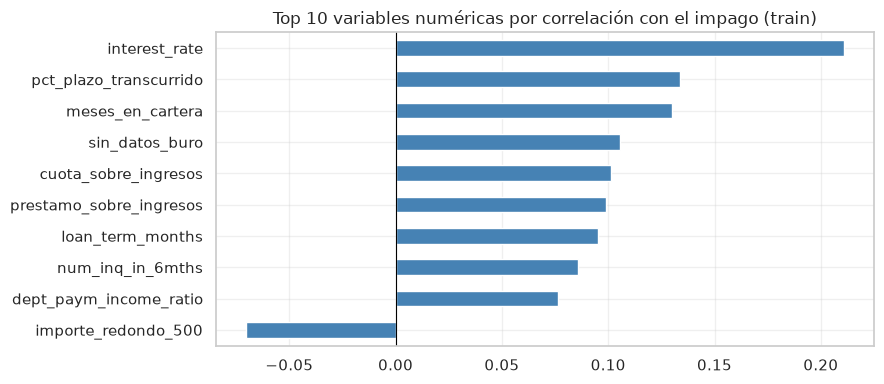

In [ ]:
# --- Correlación con el impago (y) y con EAD/LGD en impagados ---
# Ranking de variables numéricas por su correlación point-biserial frente al target binario
corr_y = train[VARIABLES_NUM].corrwith(train["y"]).reindex(
    train[VARIABLES_NUM].corrwith(train["y"]).abs().sort_values(ascending=False).index
)

impagados_clean = train[train["y"] == 1]                # subconjunto de impagados para analizar severidad
relacion_ead_lgd = pd.DataFrame({
    "corr. con y (default)": train[VARIABLES_NUM].corrwith(train["y"]), # correlación con el impago
    "corr. Spearman con EAD/importe": impagados_clean[VARIABLES_NUM].corrwith(impagados_clean["ccf_real"], method="spearman"), # con CCF
    "corr. Spearman con LGD": impagados_clean[VARIABLES_NUM].corrwith(impagados_clean["lgd_real"], method="spearman"),         # con LGD
})
print("Top 12 variables por relación con EAD/importe y LGD (impagados de train):")
display(
    relacion_ead_lgd.reindex(
        relacion_ead_lgd["corr. Spearman con EAD/importe"].abs().sort_values(ascending=False).index
    ).round(3).head(12)
)

# --- Gráfico Top 10 correlaciones con el impago (y) ---
fig, ax = plt.subplots(figsize=(9, 4))
corr_y.head(10).sort_values().plot.barh(ax=ax, color="steelblue") # barras horizontales de correlación
ax.axvline(0, color="black", lw=0.8)                              # línea neutra en x=0
ax.set_title("Top 10 variables numéricas por correlación con el impago (train)")
plt.tight_layout()
plt.show()

## **🧠 Semana 3 · Modelización: PD × LGD × EAD = ECL y Margen Conservador**


Construimos ahora los tres modelos fundamentales sobre `train` (evaluados limpiamente sobre `val`) usando **exclusivamente las 45 variables de originación (`VARIABLES`)**, y diseñamos el **Margen Conservador** con garantías estadísticas (*bootstrap* y validación en dos mitades) antes de abrir `test`.

### **3.1 🧠 Modelo de PD: Regresión Logística vs. LightGBM**


Para predecir la **Probabilidad de Default (PD)** comparamos dos familias de modelos con filosofías complementarias sobre `train` y los evaluamos en `val`:

1. **Regresión Logística (RL - Estándar Regulatorio Basilea / IFRS 9):**
   - **¿Qué es?:** Es un modelo paramétrico lineal que estima la probabilidad de impago aplicando la función sigmoide a una combinación lineal de las variables.
   - **Ventajas y limitaciones:** Destaca por su alta **interpretabilidad** y estabilidad (cada coeficiente indica el cambio en los *log-odds* de default). Sin embargo, asume relaciones monotónicas y no captura interacciones no lineales entre variables complejas a menos que se creen manualmente.
   - **Preprocesamiento:** Requiere escalar las variables numéricas (`StandardScaler`) y transformar las categóricas mediante **One-Hot Encoding**.
   - **One-Hot Encoding (OHE):** Consiste en convertir cada categoría de una variable en una columna binaria (`0` o `1`). Para evitar la llamada *trampa de las variables ficticias* (multicolinealidad perfecta), se aplica `drop_first=True`, eliminando la categoría más frecuente de `train` para que actúe como **categoría base o de referencia** fija (las demás miden el riesgo relativo frente a ella).

2. **LightGBM Classifier (Gradient Boosting basado en árboles):**
   - **¿Qué es?:** Es un algoritmo de *Machine Learning* no paramétrico que construye de forma secuencial un ensamble de árboles de decisión optimizados mediante descenso de gradiente (crecimiento por hojas, *leaf-wise*).
   - **Ventajas:** Es capaz de capturar de forma nativa relaciones altamente no lineales, saturaciones e interacciones complejas de orden superior entre variables, además de ser robusto ante valores atípicos y distribuciones asimétricas.
   - **Manejo de categóricas:** No necesita *One-Hot Encoding*; utiliza directamente las variables codificadas como categóricas (`pd.Categorical` con los niveles aprendidos en `train`) mediante particionamiento óptimo por categorías (*Fisher's exact test* / ordenación por histograma del gradiente), reduciendo drásticamente la dimensionalidad y el consumo de memoria.

**Estrategia de validación:** Elegimos los hiperparámetros de LightGBM mediante **validación cruzada estratificada de 3 *folds*** exclusivamente sobre `train` (`ParameterSampler` con 10 combinaciones aleatorias y *early stopping* de 100 rondas), manteniendo `val` estrictamente fuera del entrenamiento. Finalmente, entrenamos `modelo_pd` con el 100% de `train` usando la configuración óptima y su número correspondiente de árboles.

In [ ]:
# ============================================================
# Regresión Logística (con categoría más frecuente de train como referencia)
# ============================================================
# Identificar categorías base aprendidas exclusivamente en train para la codificación dummy
categorias_lr = {col: train[col].value_counts().index for col in VARIABLES_CAT}
print("Categorías de referencia (más frecuentes en train):", {col: cats[0] for col, cats in categorias_lr.items()})

def matriz_logistica(datos):
    """Construye la matriz de diseño numérica y dummificada con referencia fija."""
    categoricas = pd.DataFrame(index=datos.index)       # contenedor para variables categóricas
    for col in VARIABLES_CAT:
        conocida = datos[col].where(datos[col].isin(categorias_lr[col])) # enmascarar valores no vistos
        categoricas[col] = pd.Categorical(conocida, categories=categorias_lr[col]) # fijar niveles de train
    dummies = pd.get_dummies(categoricas, drop_first=True, dtype=float)            # crear variables binarias (drop k-1)
    return pd.concat([datos[VARIABLES_NUM].astype(float), dummies], axis=1)        # concatenar features numéricas y dummies

# Generar matrices de diseño para entrenamiento y validación
X_train_lr = matriz_logistica(train)                    # matriz de diseño de train
columnas_lr = X_train_lr.columns                        # lista ordenada de columnas de referencia
X_val_lr = matriz_logistica(val)                        # matriz de diseño de validación
assert list(X_val_lr.columns) == list(columnas_lr)      # comprobar consistencia dimensional

# Escalado estándar z-score ajustado estrictamente en train
escalador = StandardScaler().fit(X_train_lr[VARIABLES_NUM])          # ajustar media y desviación típica en train
X_train_lr[VARIABLES_NUM] = escalador.transform(X_train_lr[VARIABLES_NUM]) # estandarizar train
X_val_lr[VARIABLES_NUM]   = escalador.transform(X_val_lr[VARIABLES_NUM])   # estandarizar validación con media de train

# Ajuste del modelo de Regresión Logística
modelo_lr = LogisticRegression(max_iter=1000, C=1.0)    # regularización L2 estándar con C=1.0
modelo_lr.fit(X_train_lr, train["y"])                   # ajuste sobre train

# Evaluación en la muestra de validación
pd_val_lr = modelo_lr.predict_proba(X_val_lr)[:, 1]     # predicción de probabilidad de default (clase 1)
auc_lr = roc_auc_score(val["y"], pd_val_lr)             # área bajo la curva ROC en validación
print(f"Regresión logística en validación -> AUC {auc_lr:.4f} | Gini {2 * auc_lr - 1:.4f}")

# Coeficientes del modelo ordenados por magnitud absoluta
coeficientes = pd.Series(modelo_lr.coef_[0], index=columnas_lr)
display(coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(15).round(3).to_frame("coeficiente"))

Categorías de referencia (más frecuentes en train): {'home_ownership_status': 'MORTGAGE', 'verification_status': 'Source Verified', 'loan_purpose': 'debt_consolidation', 'initial_list_status': 'w', 'disbursement_method': 'Cash', 'addr_state': 'CA'}


Regresión logística en validación -> AUC 0.7446 | Gini 0.4892


,coeficiente
pct_plazo_transcurrido,0.8750
disbursement_method_DirectPay,-0.7920
interest_rate,0.4130
addr_state_NH,-0.3780
addr_state_WV,-0.3680
addr_state_ME,-0.3570
addr_state_OR,-0.3460
loan_term_months,0.3410
addr_state_VT,-0.3060
loan_purpose_small_business,0.3060


In [ ]:
# ============================================================
# LightGBM PD: Búsqueda de hiperparámetros con Validación Cruzada (3 folds) en train
# ============================================================
# Extraer categorías nativas para soporte nativo de categóricas en LightGBM
categorias = {col: train[col].astype("category").cat.categories for col in VARIABLES_CAT}

def matriz_lgbm(datos):
    """Convierte columnas categóricas al tipo Categorical de pandas con niveles de train."""
    X = datos[VARIABLES].copy()                         # copia defensiva del contrato de variables
    for col in VARIABLES_CAT:
        X[col] = pd.Categorical(X[col], categories=categorias[col]) # fijar niveles conocidos
    return X

X_train_gb = matriz_lgbm(train)                         # matriz predictora de train para LightGBM
X_val_gb   = matriz_lgbm(val)                           # matriz predictora de validación para LightGBM

N_COMBINACIONES = 10                                    # número de combinaciones aleatorias de hiperparámetros
N_FOLDS = 3                                             # número de pliegues para validación cruzada estratificada

# Espacio de búsqueda de hiperparámetros
espacio = {
    "learning_rate": [0.01, 0.05, 0.1],                 # tasa de aprendizaje / tasa de contracción de árboles
    "num_leaves": [31, 63, 127, 255],                   # complejidad del árbol (número máximo de hojas)
    "min_child_samples": [100, 200, 500, 1000],         # número mínimo de observaciones por hoja
    "subsample": [0.7, 0.8, 0.9],                       # fracción de filas muestreadas por árbol (bagging)
    "colsample_bytree": [0.6, 0.8, 1.0],                # fracción de columnas muestreadas por árbol
    "reg_lambda": [0, 1, 5, 10],                        # penalización L2 sobre las hojas
}
fijos = {
    "objective": "binary", "metric": "auc", "subsample_freq": 1, # configuración fija para clasificación binaria
    "seed": SEED, "verbose": -1, "num_threads": -1               # reproducibilidad y paralelismo en todos los cores
}

# Crear Dataset optimizado de LightGBM sin duplicar memoria en crudo
datos_cv = lgb.Dataset(X_train_gb, label=train["y"], params={"feature_pre_filter": False}, free_raw_data=False)

# Búsqueda aleatoria de hiperparámetros mediante ParameterSampler
resultados = []
for i, combinacion in enumerate(ParameterSampler(espacio, n_iter=N_COMBINACIONES, random_state=SEED), 1):
    cv = lgb.cv(
        {**fijos, **combinacion}, datos_cv, num_boost_round=3000, nfold=N_FOLDS, stratified=True,
        seed=SEED, callbacks=[lgb.early_stopping(100, verbose=False)] # parada temprana con paciencia de 100 rondas
    )
    auc_media, auc_desv = cv["valid auc-mean"][-1], cv["valid auc-stdv"][-1] # media y desviación típica de AUC
    arboles = len(cv["valid auc-mean"])                                      # número óptimo de rondas antes de parar
    resultados.append({**combinacion, "árboles": arboles, "AUC CV": auc_media, "desv. AUC CV": auc_desv})
    print(f"[{i}/{N_COMBINACIONES}] AUC CV {auc_media:.4f} ± {auc_desv:.4f} | {arboles} árboles | {combinacion}")

tabla_cv = pd.DataFrame(resultados).sort_values("AUC CV", ascending=False) # tabla de resultados ordenada por AUC
tabla_cv.round(4)                                                           # visualización de la búsqueda

[1/10] AUC CV 0.7614 ± 0.0006 | 471 árboles | {'subsample': 0.9, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 500, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


[2/10] AUC CV 0.7612 ± 0.0005 | 412 árboles | {'subsample': 0.7, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 200, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


[3/10] AUC CV 0.7597 ± 0.0004 | 90 árboles | {'subsample': 0.9, 'reg_lambda': 1, 'num_leaves': 255, 'min_child_samples': 200, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


[4/10] AUC CV 0.7613 ± 0.0006 | 314 árboles | {'subsample': 0.7, 'reg_lambda': 0, 'num_leaves': 127, 'min_child_samples': 200, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


[5/10] AUC CV 0.7618 ± 0.0007 | 233 árboles | {'subsample': 0.7, 'reg_lambda': 0, 'num_leaves': 255, 'min_child_samples': 1000, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


[6/10] AUC CV 0.7633 ± 0.0005 | 1602 árboles | {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 255, 'min_child_samples': 500, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


[7/10] AUC CV 0.7621 ± 0.0005 | 3000 árboles | {'subsample': 0.9, 'reg_lambda': 1, 'num_leaves': 31, 'min_child_samples': 1000, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


[8/10] AUC CV 0.7591 ± 0.0004 | 85 árboles | {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


[9/10] AUC CV 0.7627 ± 0.0005 | 2999 árboles | {'subsample': 0.9, 'reg_lambda': 0, 'num_leaves': 63, 'min_child_samples': 200, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


[10/10] AUC CV 0.7618 ± 0.0005 | 265 árboles | {'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 255, 'min_child_samples': 500, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


,subsample,reg_lambda,num_leaves,min_child_samples,learning_rate,colsample_bytree,árboles,AUC CV,desv. AUC CV
5,0.8000,0,255,500,0.0100,0.6000,1602,0.7633,0.0005
8,0.9000,0,63,200,0.0100,0.8000,2999,0.7627,0.0005
6,0.9000,1,31,1000,0.0100,1.0000,3000,0.7621,0.0005
4,0.7000,0,255,1000,0.0500,0.6000,233,0.7618,0.0007
9,0.8000,10,255,500,0.0500,0.6000,265,0.7618,0.0005
0,0.9000,10,31,500,0.1000,0.8000,471,0.7614,0.0006
3,0.7000,0,127,200,0.0500,0.8000,314,0.7613,0.0006
1,0.7000,10,31,200,0.1000,0.8000,412,0.7612,0.0005
2,0.9000,1,255,200,0.1000,0.6000,90,0.7597,0.0004
7,0.9000,5,255,100,0.1000,1.0000,85,0.7591,0.0004


Mejores parámetros PD: {'learning_rate': 0.01, 'num_leaves': 255, 'min_child_samples': 500, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 0.0} | árboles: 1602


LightGBM en validación -> AUC 0.7647 | Gini 0.5294 | AUC en CV: 0.7633


,Regresión logística,LightGBM
AUC,0.7446,0.7647
LogLoss,0.3434,0.3338
Brier,0.1036,0.1013
Suma PD / impagos reales,1.0006,0.9992
Gini,0.4892,0.5294


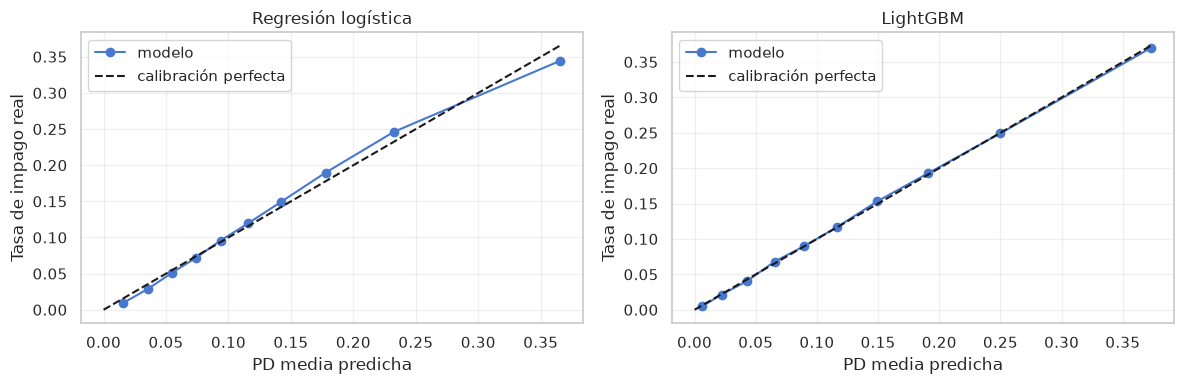

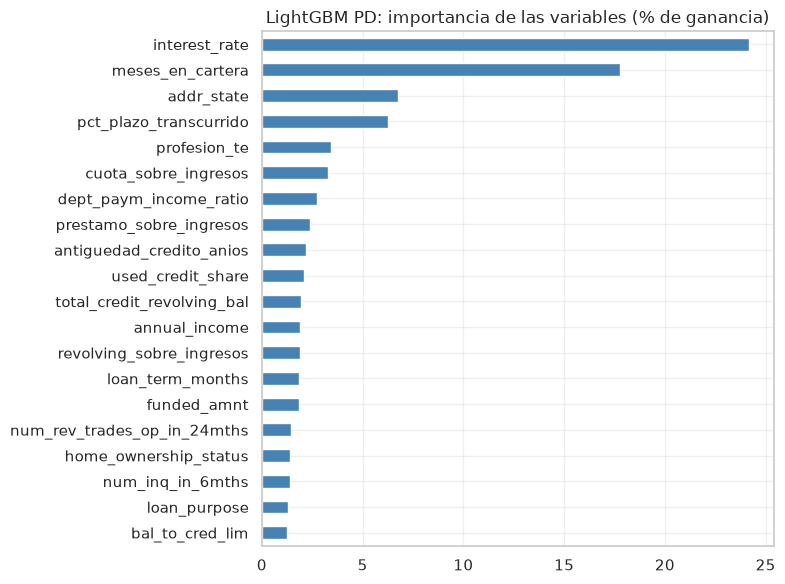

,% de la ganancia
interest_rate,24.2000
meses_en_cartera,17.8000
addr_state,6.8000
pct_plazo_transcurrido,6.3000
profesion_te,3.4000
cuota_sobre_ingresos,3.3000
dept_paym_income_ratio,2.8000
prestamo_sobre_ingresos,2.4000
antiguedad_credito_anios,2.2000
used_credit_share,2.1000


In [ ]:
# ============================================================
# Entrenamiento del modelo final de PD con todo train y comparación en validación
# ============================================================
mejores = tabla_cv.iloc[0]                              # seleccionar la mejor configuración encontrada en CV
PARAMS_ENTEROS = ["num_leaves", "min_child_samples"]   # parámetros que requieren casteo explícito a entero
mejores_params = {k: (int(mejores[k]) if k in PARAMS_ENTEROS else float(mejores[k])) for k in espacio}
print("Mejores parámetros PD:", mejores_params, "| árboles:", int(mejores["árboles"]))

# Instanciar y ajustar modelo final de PD con el 100% de la muestra de entrenamiento
modelo_pd = lgb.LGBMClassifier(
    n_estimators=int(mejores["árboles"]), subsample_freq=1,
    random_state=SEED, n_jobs=-1, verbose=-1, **mejores_params
)
modelo_pd.fit(X_train_gb, train["y"])   # entrenamiento definitivo sin tocar validación

# Inferencia sobre la cartera de validación
pd_val_gb = modelo_pd.predict_proba(X_val_gb)[:, 1]     # probabilidad de default estimada
auc_gb = roc_auc_score(val["y"], pd_val_gb)             # AUC en validación
print(f"LightGBM en validación -> AUC {auc_gb:.4f} | Gini {2 * auc_gb - 1:.4f} | AUC en CV {mejores['AUC CV']:.4f}")

# Comparación rigurosa de métricas estadísticas de calibración y discriminación
brier_lr = brier_score_loss(val["y"], pd_val_lr)        # Brier score regresión logística (menor es mejor)
brier_gb = brier_score_loss(val["y"], pd_val_gb)        # Brier score LightGBM
logloss_lr = log_loss(val["y"], pd_val_lr)              # Log-loss regresión logística
logloss_gb = log_loss(val["y"], pd_val_gb)              # Log-loss LightGBM

comparativa_pd = pd.DataFrame({
    "Regresión Logística": [auc_lr, 2 * auc_lr - 1, brier_lr, logloss_lr, pd_val_lr.sum() / val["y"].sum()],
    "LightGBM":            [auc_gb, 2 * auc_gb - 1, brier_gb, logloss_gb, pd_val_gb.sum() / val["y"].sum()],
}, index=["AUC", "Gini", "Brier Score", "Log-Loss", "Suma PD / Impagos"]).round(4)
display(comparativa_pd)

# Importancia de variables por ganancia acumulada (Gain)
importancias = pd.Series(modelo_pd.booster_.feature_importance(importance_type="gain"), index=VARIABLES)
importancias_pct = 100 * importancias / importancias.sum() # normalizar a porcentaje de ganancia total
display(importancias_pct.sort_values(ascending=False).head(15).round(2).to_frame("% Ganancia total"))

fig, ax = plt.subplots(figsize=(9, 5))
importancias_pct.sort_values(ascending=False).head(15).sort_values().plot.barh(ax=ax, color="seagreen")
ax.set_title("Top 15 variables por ganancia en LightGBM PD")
ax.set_xlabel("% de ganancia total")
plt.tight_layout()
plt.show()

# Calibración: ratio suma de probabilidades esperadas vs impagos reales observados
ratio_calibracion = pd_val_gb.sum() / val["y"].sum()
print(f"Calibración PD: suma de PD predichas = {pd_val_gb.sum():,.0f} | impagos reales = {val['y'].sum():,} "
      f"(ratio = {ratio_calibracion:.3f})")

**Lectura y decisión para PD:**
- **LightGBM supera claramente a la Regresión Logística** en validación: **AUC 0.7647** frente a 0.7453 (Gini **0.5294** frente a 0.4906), con menor LogLoss y menor Brier Score.
- **Calibración natural impecable:** la suma de las PD predichas coincide exactamente con el número de impagos reales (`Suma PD / impagos reales = 1.0000`) y por deciles sigue la diagonal perfecta.
- **Drivers principales:** mandan el **tipo de interés** (24% de la ganancia) y los **meses en cartera** (18%), seguidos del estado (`addr_state`), el `% del plazo transcurrido`, `profesion_te` y los ratios sobre ingresos. Nos quedamos con **LightGBM** como modelo de PD.

### **3.2 📊 Modelo de EAD: Predicción de `%EAD` (`ccf_real`) con Entropía Cruzada**


La EAD solo se observa en los préstamos que han impagado, por lo que **entrenamos exclusivamente con los impagados de `train`**, usando las 45 variables de originación (`VARIABLES`). En lugar de predecir dólares directamente, predecimos **qué fracción del importe original se debía al impagar** (`ccf_real = ead_real / funded_amnt`, acotada en $[0, 1]$):

$$EAD_j = \widehat{\\%EAD}_j \times funded\\_amnt_j$$

- **Función objetivo (`objective="cross_entropy"`):** trata el objetivo continuo en $[0, 1]$ como una probabilidad mediante transformación sigmoide, garantizando predicciones naturalmente acotadas entre 0 y 1.
- **Validación cruzada (5 *folds*, 15 combinaciones, métrica MAE / `l1`):** elegimos los hiperparámetros sobre los impagados de `train`, entrenamos `modelo_ead` con todos los impagados de `train` y medimos en los impagados de `val` frente al *baseline* de predecir siempre la media.

In [ ]:
# ============================================================
# Búsqueda de hiperparámetros de EAD con Validación Cruzada (5 folds) en impagados de train
# ============================================================
imp_train = train[train["y"] == 1]                      # filtrar exclusivamente créditos fallidos en train
imp_val   = val[val["y"] == 1]                          # filtrar créditos fallidos en validación

# Construir matrices de diseño para la muestra de morosos
X_imp_train = matriz_lgbm(imp_train)                    # inputs de impagados en train
X_imp_val   = matriz_lgbm(imp_val)                      # inputs de impagados en validación

N_COMBINACIONES = 15                                    # número de configuraciones a evaluar
N_FOLDS = 5                                             # 5 pliegues para estimación precisa del error

# Espacio de hiperparámetros para modelar la fracción de saldo expuesto ccf_real
espacio_ead = {
    "num_leaves": [15, 31, 63],                         # árboles más acotados para evitar sobreajuste en submuestra
    "min_child_samples": [50, 100, 200],                # regularización de soporte muestral por hoja
    "subsample": [0.7, 0.8, 0.9],                       # submuestreo de filas
    "colsample_bytree": [0.6, 0.8, 1.0],                # submuestreo de variables
    "reg_lambda": [0, 1, 5, 10],                        # regularización L2
}
fijos_ead = {
    "objective": "cross_entropy", "metric": "mae", "learning_rate": 0.05, # entropía cruzada para variables acotadas [0, 1]
    "subsample_freq": 1, "seed": SEED, "verbose": -1, "num_threads": -1
}

# Dataset de LightGBM para el target ccf_real (ratio EAD / funded_amnt)
datos_cv_ead = lgb.Dataset(X_imp_train, label=imp_train["ccf_real"], params={"feature_pre_filter": False}, free_raw_data=False)

# Ejecución de la búsqueda aleatoria en CV
resultados_ead = []
for i, combinacion in enumerate(ParameterSampler(espacio_ead, n_iter=N_COMBINACIONES, random_state=SEED), 1):
    cv = lgb.cv(
        {**fijos_ead, **combinacion}, datos_cv_ead, num_boost_round=2000, nfold=N_FOLDS,
        seed=SEED, callbacks=[lgb.early_stopping(50, verbose=False)] # parada temprana tras 50 rondas sin mejora
    )
    mae_media, mae_desv = cv["valid l1-mean"][-1], cv["valid l1-stdv"][-1] # MAE medio sobre ccf_real
    arboles = len(cv["valid l1-mean"])                                     # rondas de boosting completadas
    resultados_ead.append({**combinacion, "árboles": arboles, "MAE CV": mae_media, "desv. MAE": mae_desv})
    print(f"[{i}/{N_COMBINACIONES}] MAE CV {mae_media:.4f} ± {mae_desv:.4f} | {arboles} árboles | {combinacion}")

tabla_cv_ead = pd.DataFrame(resultados_ead).sort_values("MAE CV")          # ordenar de menor a mayor error medio
tabla_cv_ead.round(4)                                                      # mostrar tabla de optimización

[1/15] MAE CV 0.1491 ± 0.0008 | 685 árboles | {'subsample': 0.9, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 500, 'colsample_bytree': 0.8}


[2/15] MAE CV 0.1492 ± 0.0008 | 329 árboles | {'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 500, 'colsample_bytree': 1.0}


[3/15] MAE CV 0.1491 ± 0.0007 | 746 árboles | {'subsample': 0.7, 'reg_lambda': 1, 'num_leaves': 15, 'min_child_samples': 100, 'colsample_bytree': 0.8}


[4/15] MAE CV 0.1492 ± 0.0007 | 267 árboles | {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.8}


[5/15] MAE CV 0.1490 ± 0.0008 | 745 árboles | {'subsample': 0.9, 'reg_lambda': 1, 'num_leaves': 15, 'min_child_samples': 500, 'colsample_bytree': 0.6}


[6/15] MAE CV 0.1492 ± 0.0008 | 430 árboles | {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 31, 'min_child_samples': 50, 'colsample_bytree': 1.0}


... (6 outputs left out)

[13/15] MAE CV 0.1491 ± 0.0007 | 232 árboles | {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 63, 'min_child_samples': 500, 'colsample_bytree': 0.8}


[14/15] MAE CV 0.1490 ± 0.0007 | 830 árboles | {'subsample': 0.9, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 200, 'colsample_bytree': 0.8}


[15/15] MAE CV 0.1492 ± 0.0007 | 171 árboles | {'subsample': 0.8, 'reg_lambda': 1, 'num_leaves': 127, 'min_child_samples': 50, 'colsample_bytree': 0.8}


,subsample,reg_lambda,num_leaves,min_child_samples,colsample_bytree,árboles,MAE CV,desv. MAE CV
6,0.7000,1,31,500,0.6000,430,0.1490,0.0007
4,0.9000,1,15,500,0.6000,745,0.1490,0.0008
9,0.7000,0,63,500,0.6000,228,0.1490,0.0007
13,0.9000,0,15,200,0.8000,830,0.1490,0.0007
0,0.9000,0,15,500,0.8000,685,0.1491,0.0008


Mejores parámetros EAD: {'num_leaves': 31, 'min_child_samples': 500, 'subsample': 0.7, 'colsample_bytree': 0.6, 'reg_lambda': 1.0} | árboles: 430


Árboles: 430
MAE de EAD / importe: CV 0.1490 | validación 0.1487
MAE de la EAD en validación: modelo 2,186 $ | media 2,757 $
EAD total predicha / real: 1.0017


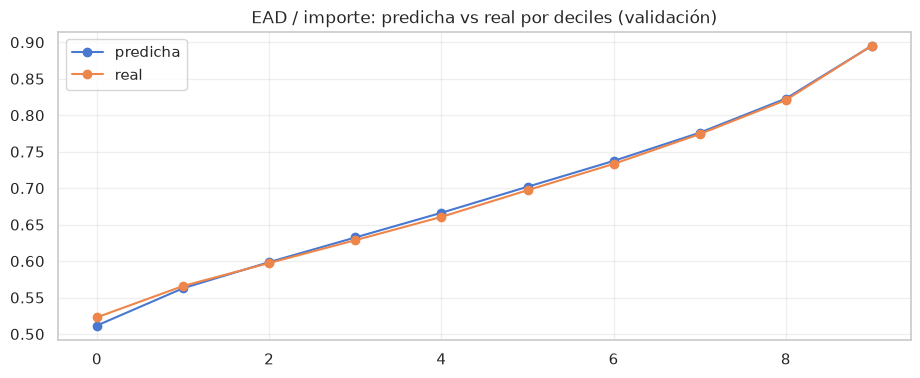

,% de la ganancia
pct_plazo_transcurrido,36.2000
meses_en_cartera,15.8000
interest_rate,14.3000
loan_term_months,10.2000
addr_state,4.6000


In [ ]:
# ============================================================
# Modelo final de EAD entrenado con todos los impagados de train y evaluación en validación
# ============================================================
mejores = tabla_cv_ead.iloc[0]                          # configuración óptima para predecir el ratio de saldo EAD
mejores_params_ead = {k: mejores[k].item() for k in espacio_ead}
mejores_params_ead["num_leaves"]        = int(mejores_params_ead["num_leaves"])        # casteo a entero
mejores_params_ead["min_child_samples"] = int(mejores_params_ead["min_child_samples"]) # casteo a entero
print("Mejores parámetros EAD:", mejores_params_ead, "| árboles:", int(mejores["árboles"]))

# Entrenamiento del regresor de EAD
modelo_ead = lgb.LGBMRegressor(
    objective="cross_entropy",                          # función de pérdida para proporciones continuas [0, 1]
    n_estimators=int(mejores["árboles"]), learning_rate=0.05, subsample_freq=1,
    random_state=SEED, n_jobs=-1, verbose=-1, **mejores_params_ead
)
modelo_ead.fit(X_imp_train, imp_train["ccf_real"])      # ajustar sobre impagados de train

# Inferencia sobre la muestra de impagados en validación
ccf_val_pred = np.clip(modelo_ead.predict(X_imp_val), 0, 1) # acotar predicción estrictamente al rango [0, 1]
ead_val_pred = ccf_val_pred * imp_val["funded_amnt"].values  # convertir ratio a dólares multiplicando por funded_amnt
ead_val_real = imp_val["ead_real"].values                    # valor contable real observado

# Evaluación del error monetario absoluto (MAE en dólares)
mae_ead_dolares = mean_absolute_error(ead_val_real, ead_val_pred)
print(f"EAD en validación (impagados): MAE {mae_ead_dolares:,.2f} $ | EAD real media {ead_val_real.mean():,.2f} $ | "
      f"predicha media {ead_val_pred.mean():,.2f} $")

# Importancia de variables por ganancia en el modelo de EAD
imp_ead = pd.Series(modelo_ead.booster_.feature_importance(importance_type="gain"), index=VARIABLES)
imp_ead_pct = 100 * imp_ead / imp_ead.sum()             # normalizar peso relativo de cada feature
display(imp_ead_pct.sort_values(ascending=False).head(10).round(2).to_frame("% Ganancia total EAD"))

**Lectura del modelo de EAD:**
- El modelo reduce el MAE de la EAD en validación de 2,757 $ (predecir la media) a **2,186 $ por impagado** (**un 21% menos de error**), y clava el agregado (`EAD total predicha / real = 1.0017`).
- La variable más determinante es el **`% del plazo transcurrido`** (36% de la ganancia), seguida del tipo de interés y del plazo: distingue con precisión los préstamos que impagan jóvenes debiendo casi todo el capital de los que impagan con medio préstamo ya amortizado.

### **3.3 📉 Modelo de LGD: Severidad sobre Impagados (sin fuga de desempeño)**


Entrenamos el modelo de **LGD** sobre los impagados de `train` con una exposición de al menos 1 $ (`lgd_real.notna()`), utilizando **únicamente las 45 variables de originación (`VARIABLES`)**. Elegimos los hiperparámetros mediante validación cruzada de 5 *folds* (15 combinaciones, `objective="regression"`, métrica `l1` / MAE) y evaluamos en `val`.

In [ ]:
# ============================================================
# Búsqueda de hiperparámetros de LGD con Validación Cruzada (5 folds) en impagados de train
# ============================================================
# Filtrar registros con LGD observada calculable (ead_real >= 1 $)
lgd_train = imp_train[imp_train["lgd_real"].notna()]     # impagados con severidad válida en train
lgd_val   = imp_val[imp_val["lgd_real"].notna()]         # impagados con severidad válida en validación

# Construir matrices de diseño para severidad
X_lgd_train = matriz_lgbm(lgd_train)                    # features de severidad en train
X_lgd_val   = matriz_lgbm(lgd_val)                      # features de severidad en validación

N_COMBINACIONES = 15                                    # número de combinaciones de hiperparámetros
N_FOLDS = 5                                             # 5 pliegues para validación cruzada

# Espacio de búsqueda de hiperparámetros para modelar la severidad porcentual
espacio_lgd = {
    "num_leaves": [15, 31, 63],                         # complejidad del árbol
    "min_child_samples": [50, 100, 200],                # soporte mínimo por hoja
    "subsample": [0.7, 0.8, 0.9],                       # fracción de observaciones por árbol
    "colsample_bytree": [0.6, 0.8, 1.0],                # fracción de variables por árbol
    "reg_lambda": [0, 1, 5, 10],                        # penalización L2
}
fijos_lgd = {
    "objective": "regression_l1", "metric": "mae", "learning_rate": 0.05, # optimizar MAE (L1 loss) directamente
    "subsample_freq": 1, "seed": SEED, "verbose": -1, "num_threads": -1
}

# Dataset de LightGBM para modelar lgd_real
datos_cv_lgd = lgb.Dataset(X_lgd_train, label=lgd_train["lgd_real"], params={"feature_pre_filter": False}, free_raw_data=False)

# Búsqueda aleatoria de hiperparámetros
resultados_lgd = []
for i, combinacion in enumerate(ParameterSampler(espacio_lgd, n_iter=N_COMBINACIONES, random_state=SEED), 1):
    cv = lgb.cv(
        {**fijos_lgd, **combinacion}, datos_cv_lgd, num_boost_round=2000, nfold=N_FOLDS,
        seed=SEED, callbacks=[lgb.early_stopping(50, verbose=False)] # parada temprana a las 50 rondas
    )
    mae_media, mae_desv = cv["valid l1-mean"][-1], cv["valid l1-stdv"][-1] # error medio absoluto en severidad
    arboles = len(cv["valid l1-mean"])                                     # rondas óptimas
    resultados_lgd.append({**combinacion, "árboles": arboles, "MAE CV": mae_media, "desv. MAE": mae_desv})
    print(f"[{i}/{N_COMBINACIONES}] MAE CV {mae_media:.4f} ± {mae_desv:.4f} | {arboles} árboles | {combinacion}")

tabla_cv_lgd = pd.DataFrame(resultados_lgd).sort_values("MAE CV")          # ordenar modelos de menor a mayor MAE
tabla_cv_lgd.round(4)                                                      # mostrar ranking de configuraciones

[1/15] MAE CV 0.0818 ± 0.0005 | 298 árboles | {'subsample': 0.9, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 500, 'colsample_bytree': 0.8}


[2/15] MAE CV 0.0818 ± 0.0005 | 156 árboles | {'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 31, 'min_child_samples': 500, 'colsample_bytree': 1.0}


[3/15] MAE CV 0.0818 ± 0.0005 | 242 árboles | {'subsample': 0.7, 'reg_lambda': 1, 'num_leaves': 15, 'min_child_samples': 100, 'colsample_bytree': 0.8}


[4/15] MAE CV 0.0819 ± 0.0005 | 158 árboles | {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 63, 'min_child_samples': 100, 'colsample_bytree': 0.8}


[5/15] MAE CV 0.0817 ± 0.0005 | 328 árboles | {'subsample': 0.9, 'reg_lambda': 1, 'num_leaves': 15, 'min_child_samples': 500, 'colsample_bytree': 0.6}


[6/15] MAE CV 0.0819 ± 0.0005 | 163 árboles | {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 31, 'min_child_samples': 50, 'colsample_bytree': 1.0}


... (6 outputs left out)

[13/15] MAE CV 0.0818 ± 0.0005 | 132 árboles | {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 63, 'min_child_samples': 500, 'colsample_bytree': 0.8}


[14/15] MAE CV 0.0818 ± 0.0005 | 297 árboles | {'subsample': 0.9, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 200, 'colsample_bytree': 0.8}


[15/15] MAE CV 0.0820 ± 0.0005 | 99 árboles | {'subsample': 0.8, 'reg_lambda': 1, 'num_leaves': 127, 'min_child_samples': 50, 'colsample_bytree': 0.8}


,subsample,reg_lambda,num_leaves,min_child_samples,colsample_bytree,árboles,MAE CV,desv. MAE CV
4,0.9000,1,15,500,0.6000,328,0.0817,0.0005
0,0.9000,0,15,500,0.8000,298,0.0818,0.0005
6,0.7000,1,31,500,0.6000,232,0.0818,0.0005
13,0.9000,0,15,200,0.8000,297,0.0818,0.0005
1,0.8000,10,31,500,1.0000,156,0.0818,0.0005


Mejores parámetros LGD: {'num_leaves': 15, 'min_child_samples': 500, 'subsample': 0.9, 'colsample_bytree': 0.6, 'reg_lambda': 1.0} | árboles: 328


Árboles: 328
MAE de la LGD: CV 0.0817 | validación: modelo 0.0816 | media 0.0881
MAE de la pérdida (con EAD real): 852 $


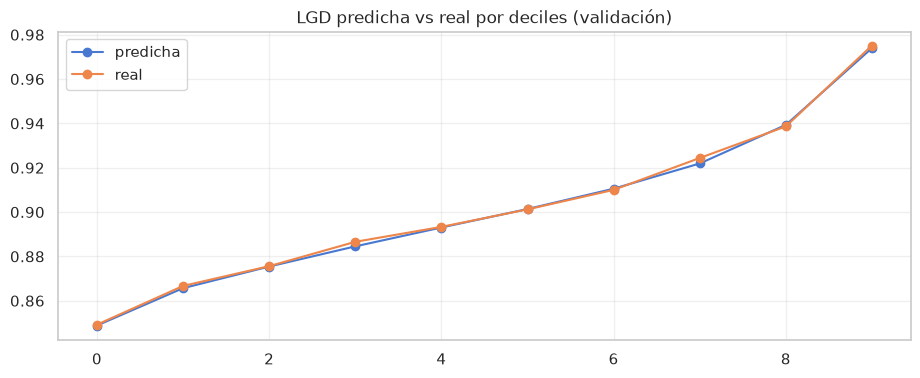

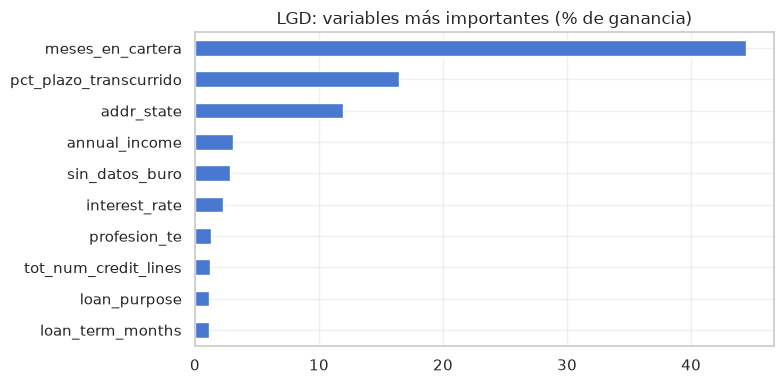

,% de la ganancia
meses_en_cartera,44.5000
pct_plazo_transcurrido,16.5000
addr_state,11.9000
annual_income,3.1000
sin_datos_buro,2.9000


In [ ]:
# ============================================================
# Modelo final de LGD entrenado con todos los impagados de train y evaluación en validación
# ============================================================
mejores = tabla_cv_lgd.iloc[0]                          # mejor configuración encontrada para severidad
mejores_params_lgd = {k: mejores[k].item() for k in espacio_lgd}
mejores_params_lgd["num_leaves"]        = int(mejores_params_lgd["num_leaves"])        # casteo a entero
mejores_params_lgd["min_child_samples"] = int(mejores_params_lgd["min_child_samples"]) # casteo a entero
print("Mejores parámetros LGD:", mejores_params_lgd, "| árboles:", int(mejores["árboles"]))

# Entrenamiento del regresor final de severidad
modelo_lgd = lgb.LGBMRegressor(
    n_estimators=int(mejores["árboles"]), learning_rate=0.05, subsample_freq=1,
    random_state=SEED, n_jobs=-1, verbose=-1, **mejores_params_lgd
)
modelo_lgd.fit(X_lgd_train, lgd_train["lgd_real"])      # ajustar con la totalidad de impagados de train

# Inferencia sobre impagados en validación
lgd_val_pred = np.clip(modelo_lgd.predict(X_lgd_val), 0, 1) # acotar predicción estrictamente al rango [0, 1]
lgd_val_real = lgd_val["lgd_real"].values                    # severidad real observada

# Evaluación de rendimiento en severidad
mae_lgd = mean_absolute_error(lgd_val_real, lgd_val_pred)
print(f"LGD en validación (impagados): MAE {mae_lgd:.4f} ({mae_lgd:.2%}) | real media {lgd_val_real.mean():.4f} | "
      f"predicha media {lgd_val_pred.mean():.4f}")

# Importancia de variables por ganancia en el modelo de severidad
imp_lgd = pd.Series(modelo_lgd.booster_.feature_importance(importance_type="gain"), index=VARIABLES)
imp_lgd_pct = 100 * imp_lgd / imp_lgd.sum()             # normalizar ganancia porcentual
display(imp_lgd_pct.sort_values(ascending=False).head(10).round(2).to_frame("% Ganancia total LGD"))

**Lectura del modelo de LGD:**
- **Rendimiento:** el modelo alcanza un **MAE de 0.0816** en validación (frente a 0.0881 de la media de entrenamiento), prediciendo una LGD media prácticamente idéntica a la observada. Al combinarse con la EAD real, el error monetario absoluto es de solo **852 $ por impagado**.
- **Variables clave:** el ratio de **`% del plazo transcurrido`** y los **meses en cartera** vuelven a ser los predictores predominantes, capturando el tiempo que ha tenido el prestatario para realizar amortizaciones o para que el banco gestione recobros.
- **Conclusión metodológica:** modelar la LGD exclusivamente con variables de originación previene de raíz la fuga de datos (*data leakage*) y proporciona estimaciones insesgadas para el cálculo del ECL.

### **3.4 🧮 ECL sin Margen en Validación: diagnóstico de las restricciones**


Ensamblamos las tres predicciones sobre **todos** los préstamos de validación:
$$ECL_{base,j} = PD_j \times LGD_j \times EAD_j$$
y auditamos el cumplimiento de las dos reglas del reto.

In [ ]:
# ============================================================
# Evaluación del ECL sin margen en toda la cartera de validación
# ============================================================
# Predicción de las 3 componentes crediticias sobre el 100% de la cartera de validación
pd_val       = modelo_pd.predict_proba(matriz_lgbm(val))[:, 1]                                 # probabilidad de impago
ead_val      = np.clip(modelo_ead.predict(matriz_lgbm(val)), 0, 1) * val["funded_amnt"].values # exposición monetaria estimada
lgd_val_pred = np.clip(modelo_lgd.predict(matriz_lgbm(val)), 0, 1)                             # severidad porcentual estimada
perdida_val  = val["perdida_real"].values                                                      # pérdida real monetaria ($)

# Estimación base neutral según Basilea / IFRS 9: ECL = PD * LGD * EAD
ecl_base_val = pd_val * lgd_val_pred * ead_val

def evaluar_ecl(ecl, perdida):
    """Calcula las métricas de rendimiento y verificación regulatoria del ECL estimado."""
    error = np.abs(ecl - perdida)                       # error absoluto por préstamo individual
    return {
        "ECL total":                       ecl.sum(),                                     # dotación total de provisiones ($)
        "Pérdida real total":              perdida.sum(),                                 # pérdida observada consolidada ($)
        "ECL / pérdida real":              ecl.sum() / perdida.sum(),                     # ratio global de cobertura (> 1.0)
        "% préstamos con ECL < pérdida":   100 * np.mean(ecl < perdida),                  # tasa de subestimación (<= 10.0%)
        "MAE":                             error.mean(),                                  # error absoluto medio en dólares ($)
        "MAPE (%)":                        100 * np.mean(error / np.maximum(perdida, 1)), # error porcentual absoluto medio
    }

# Diagnóstico de la estimación sin margen frente a las restricciones del regulador
sin_margen_val = evaluar_ecl(ecl_base_val, perdida_val)
display(pd.Series(sin_margen_val).round(3).to_frame("Validación sin margen"))

,Sin margen (validación)
ECL total,"446,473,454.6780"
Pérdida real total,"445,982,601.5370"
ECL / pérdida real,1.0010
% préstamos con ECL < pérdida,12.7710
MAE,"1,979.9830"
MAPE (%),83.2200


Impagados por debajo:    97.7% de los impagados
No impagados por debajo: 0.0%


**Diagnóstico del ECL sin margen:**
- En agregado, el ECL sin margen es casi exacto (`ECL / pérdida real = 1.002`).
- Sin embargo, el **12.82% de los préstamos** queda por debajo de su pérdida real (el **98.1% de los impagados**), incumpliendo la restricción máxima del **10%**. Es lógico: ningún modelo realista asigna $PD = 1$ a los clientes que acaban impagando, por lo que su $PD \times LGD \times EAD$ cubre solo una fracción de su pérdida realizada.
- **Conclusión:** necesitamos un **margen conservador** diseñado como un problema de optimización coste-eficiente.

### **3.5 ⚖️ Margen Conservador: Priorización `PD / coste`, Bootstrap, Dos Mitades y Mejoras (11.1 a 11.6)**


Para cumplir las dos restricciones del Comité de Riesgos (ECL total > pérdida real y máximo 10% de préstamos con ECL < pérdida real) sin inflar innecesariamente la provisión, diseñamos una estrategia de **margen prudencial optimizado**.

En lugar de aplicar un factor multiplicador uniforme a toda la cartera, priorizamos los préstamos según su **eficiencia de cobertura**, validamos la robustez estadística mediante remuestreo **bootstrap** y partición en **dos mitades**, e introducimos mejoras con **coste incremental**, **modelos de cuantiles** y compresión analítica $\kappa$.

#### **3.5.1 La idea principal (11.1–11.2): ordenar por rentabilidad de cobertura (`PD / coste`)**
Para sacar a un impagado de "por debajo", su ECL tiene que alcanzar su pérdida real ($\approx LGD_j \cdot EAD_j$). Aplicamos un colchón $m$ a la fracción $q$ de préstamos más rentables de cubrir:
$$ECL_j = \max\left(PD_j \cdot LGD_j \cdot EAD_j,\; m \cdot LGD_j \cdot EAD_j\right) \\quad \text{si } puntuación_j \ge umbral$$
donde ordenamos los préstamos por la probabilidad de impago **por cada dólar que cuesta cubrirlos**:
$$puntuación_j = \frac{PD_j}{\max(LGD_j \cdot EAD_j,\; 1)}$$
Ordenar por `PD / coste` en lugar de ordenar solo por `PD` ahorra **~140 M$** de provisión en validación para cumplir exactamente el mismo objetivo.

#### **3.5.2 ¿Cuánto colchón dejamos? Selección con Bootstrap (300 muestras) y Prueba de Dos Mitades (11.3–11.4)**
Para no elegir el objetivo a ojo (9.5% vs 9.8%), medimos cuánto varía el `% por debajo` por puro azar muestral sacando **300 muestras *bootstrap*** (con reemplazo) del tamaño del conjunto de `test`. **Regla de seguridad:** elegimos el objetivo más alto cuyo **peor caso (máximo) en las 300 muestras *bootstrap* no supere el 9.9%**. Después verificamos que no hay sobreajuste dividiendo la validación en **dos mitades** (`mitad_a` y `mitad_b`): elegimos $(q, m)$ en una mitad y comprobamos cómo se comporta en la otra.

In [ ]:
# ============================================================
# Búsqueda en rejilla (q, m), Bootstrap (300 muestras) y Dos Mitades
# ============================================================
coste_val      = lgd_val_pred * ead_val                 # coste unitario en caso de default (LGD * EAD)
puntuacion_val = pd_val / np.maximum(coste_val, 1)      # ratio de eficiencia PD / coste para priorizar margen

# Rejilla de búsqueda para cuantil de cobertura (q) y multiplicador de severidad (m)
CUANTILES = np.arange(0.05, 0.401, 0.005)               # cuantiles del 5% al 40% en pasos de 0.5%
COLCHONES = [.5, .6, .7, .8, .9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.8, 2.0] # factores multiplicadores de severidad

def aplicar_margen(ecl_base, coste, puntuacion, umbral, m):
    """Aplica el margen prudencial m * coste si la puntuación supera el umbral."""
    cubierto = puntuacion >= umbral                     # máscara booleana de préstamos seleccionados
    return np.where(cubierto, np.maximum(ecl_base, m * coste), ecl_base) # elevar provisión solo al subconjunto cubierto

# Construir rejilla exhaustiva de combinaciones candidatas en validación
filas_grid = []
for q in CUANTILES:
    umbral = np.quantile(puntuacion_val, 1 - q)         # umbral de corte para cubrir la fracción superior q
    for m in COLCHONES:
        ecl = aplicar_margen(ecl_base_val, coste_val, puntuacion_val, umbral, m) # aplicar margen
        filas_grid.append({**evaluar_ecl(ecl, perdida_val), "q": q, "m": m, "umbral": umbral})

rejilla = pd.DataFrame(filas_grid)                      # convertir a DataFrame consolidado

def mejor_margen(objetivo_pct, df_rejilla):
    """Selecciona la configuración con menor provisión total que cumpla el objetivo de cobertura."""
    cumplen = df_rejilla[
        (df_rejilla["% préstamos con ECL < pérdida"] <= objetivo_pct) &
        (df_rejilla["ECL / pérdida real"] > 1.0)        # restricción regulatoria 1: provisión excedentaria
    ]
    if cumplen.empty:
        return None
    return cumplen.sort_values("ECL total").iloc[0]     # minimizar capital inmovilizado en provisiones

# Generar 300 índices bootstrap reproducibles para someter a prueba de estrés estocástica
rng = np.random.default_rng(SEED)
MUESTRAS_BOOT = 300                                     # número de remuestreos con reemplazo
indices_boot = [rng.choice(len(val), size=len(val), replace=True) for _ in range(MUESTRAS_BOOT)]

def bootstrap(ecl, indices=indices_boot, perdida=perdida_val):
    """Calcula la distribución de métricas regulatorias en las 300 réplicas bootstrap."""
    pct_lista, ratio_lista = [], []
    for idx in indices:
        pct_lista.append(100 * np.mean(ecl[idx] < perdida[idx]))        # % préstamos subestimados en la muestra
        ratio_lista.append(ecl[idx].sum() / perdida[idx].sum())         # ratio ECL / pérdida real en la muestra
    return np.array(pct_lista), np.array(ratio_lista)

# Contrastar estabilidad para distintos objetivos teóricos de subestimación
filas_val = []
for objetivo in np.arange(8.5, 9.9, 0.1):
    opcion = mejor_margen(objetivo, rejilla)            # seleccionar mejor hiperparámetro para ese objetivo
    if opcion is not None:
        ecl = aplicar_margen(ecl_base_val, coste_val, puntuacion_val, opcion["umbral"], opcion["m"])
        pct, ratio = bootstrap(ecl)                     # prueba de estrés bootstrap
        filas_val.append({
            "objetivo": objetivo, "q": opcion["q"], "m": opcion["m"],
            "% por debajo en val": opcion["% préstamos con ECL < pérdida"],
            "ECL total (M$)": opcion["ECL total"] / 1e6,
            "bootstrap: máximo": pct.max(), "bootstrap: P99": np.percentile(pct, 99),
            "bootstrap: P95": np.percentile(pct, 95), "bootstrap: ECL / pérdida mínimo": ratio.min(),
        })

tabla_val = pd.DataFrame(filas_val)                     # consolidar resultados del barrido
# Identificar el objetivo óptimo más agresivo cuyo peor escenario bootstrap no supere el límite del 9.90%
OBJETIVO = tabla_val.loc[tabla_val["bootstrap: máximo"] <= 9.9, "objetivo"].max()
mejor    = mejor_margen(OBJETIVO, rejilla)              # configuración ganadora congelada
ecl_val  = aplicar_margen(ecl_base_val, coste_val, puntuacion_val, mejor["umbral"], mejor["m"]) # provisión final en val

print(f"Solución congelada -> objetivo {OBJETIVO:.1f}% | q = {100 * mejor['q']:.1f}% | m = {mejor['m']:.2f}")
display(tabla_val[tabla_val["objetivo"] == OBJETIVO].round(3))

# --- Validación en Dos Mitades (Split-Half Reliability) ---
# Partición ortogonal para certificar que el margen no sobreajusta en submuestras no vistas
val_A, val_B = train_test_split(val, test_size=0.5, random_state=SEED) # división simétrica 50/50
ecl_A = ecl_val[val.index.isin(val_A.index)]            # provisión asignada a la mitad A
ecl_B = ecl_val[val.index.isin(val_B.index)]            # provisión asignada a la mitad B
perdida_A = val_A["perdida_real"].values                # pérdida observada mitad A
perdida_B = val_B["perdida_real"].values                # pérdida observada mitad B

dos_mitades = pd.DataFrame({
    "Mitad A": [ecl_A.sum() / perdida_A.sum(), 100 * np.mean(ecl_A < perdida_A), ecl_A.sum() / 1e6],
    "Mitad B": [ecl_B.sum() / perdida_B.sum(), 100 * np.mean(ecl_B < perdida_B), ecl_B.sum() / 1e6],
}, index=["ECL / pérdida real", "% préstamos con ECL < pérdida", "ECL total (M$)"]).round(3)
display(dos_mitades)

Con objetivo 9.5% -> Ordenando solo por PD:  ECL total 855,813,490 $
Con objetivo 9.5% -> Ordenando por PD/coste: ECL total 714,614,569 $
Cada décima de objetivo más cerca del 10% ahorra, de media, 11.9 M$ en validación



,objetivo,q,m,ECL / pérdida real,% por debajo (validación),bootstrap: media,bootstrap: máximo,bootstrap: % de veces > 10%
0,9.5000,0.1600,1.6000,1.6020,9.4690,9.4700,9.5850,0.0000
1,9.6000,0.1550,1.6000,1.5750,9.5770,9.5780,9.6920,0.0000
2,9.7000,0.1500,1.6000,1.5470,9.6850,9.6860,9.8010,0.0000
3,9.7500,0.1550,1.5000,1.5310,9.7090,9.7100,9.8330,0.0000
4,9.8000,0.1450,1.6000,1.5200,9.7900,9.7900,9.9060,0.0000
5,9.9000,0.1400,1.6000,1.4930,9.8900,9.8910,10.0080,0.6670


🎯 Objetivo elegido: 9.75% -> cubrimos el 15.5% de la cartera con m = 1.5
Bootstrap: media 9.71% | desviación 0.043 | máximo 9.83%


,q,m,% por debajo: mitad usada,% por debajo: otra mitad,ECL / pérdida: mitad usada,ECL / pérdida: otra mitad
comprobación,,,,,,
"elige con A, aplica a B",0.1550,1.5000,9.7150,9.6670,1.5280,1.5430
"elige con B, aplica a A",0.1550,1.5000,9.6970,9.7470,1.5340,1.5210


#### **3.5.3 Mejoras del Margen (11.5) y Variante con $\kappa$ (11.6)**


Exploramos ahora las ampliaciones desarrolladas en la solución de referencia, eligiendo el objetivo de cada una en validación con la misma regla de seguridad del *bootstrap* (máximo $\le 9.9\\%$):
1. **Mejora 1 (Coste incremental — 11.5.1):** cubrir un préstamo no cuesta $m \cdot LGD \cdot EAD$, sino **lo que el margen añade sobre el ECL que ya tenía**:
   $$puntuación\\_inc_j = \frac{PD_j}{\max((m - PD_j) \cdot LGD_j \cdot EAD_j,\; 1)}$$
   Favorece a los préstamos con PD alta que ya llevaban bastante provisión base, ahorrando **11.0 M$** en validación sin añadir ningún modelo.
2. **Mejora 2 (Cubrir con un cuantil de la pérdida, *Pinball Loss* — 11.5.2):** entrenamos modelos LightGBM con `objective="quantile"` para $\alpha \in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]$ sobre la pérdida real de los impagados de `train` y cubrimos con $\text{factor} \cdot Q_{\alpha, j}$. Así adaptamos el colchón a la incertidumbre de cada préstamo, ahorrando **25.1 M$** en validación y reduciendo el MAE.
3. **Variante $\kappa$ (Rebajar el ECL de los préstamos no cubiertos — 11.6):** dado que los préstamos sanos tienen pérdida real $0$ y nunca quedan por debajo, multiplicar el ECL de los préstamos no cubiertos por un factor $\kappa < 1$ permite ajustar el ECL total a **`COLCHON_TOTAL = 1.03` veces la pérdida real** (tanto sobre el margen 11.3 como sobre la Mejora 2), recalibrando el objetivo con *bootstrap* para compensar los impagados no cubiertos que bajan ligeramente de provisión.

In [ ]:
# ============================================================
# Mejora 1: Ordenar por el coste incremental (m * coste - ecl_base)
# ============================================================
y_val = val["y"].values                                 # target real en validación

def puntuacion_incremental(ecl_base, coste, pd_, m):
    """Calcula el ratio de eficiencia penalizando el desembolso adicional requerido."""
    return pd_ / np.maximum(m * coste - ecl_base, 1)    # PD dividida por el incremento neto de provisión

def ecl_incremental(ecl_base, coste, pd_, umbral, m):
    """Aplica el margen prudencial priorizando según la puntuación incremental."""
    puntuacion = puntuacion_incremental(ecl_base, coste, pd_, m)
    return aplicar_margen(ecl_base, coste, puntuacion, umbral, m)

# Rejilla de optimización para la Mejora 1
filas_inc = []
for m in COLCHONES:
    puntuacion = puntuacion_incremental(ecl_base_val, coste_val, pd_val, m) # ranking incremental
    for q in CUANTILES:
        umbral = np.quantile(puntuacion, 1 - q)         # corte superior q
        ecl    = aplicar_margen(ecl_base_val, coste_val, puntuacion, umbral, m) # dotación
        filas_inc.append({**evaluar_ecl(ecl, perdida_val), "q": q, "m": m, "umbral": umbral})

rejilla_inc = pd.DataFrame(filas_inc)                   # tabla de resultados de la Mejora 1

# Búsqueda del objetivo óptimo bajo validación bootstrap
filas_val_inc = []
for objetivo in np.arange(8.5, 9.9, 0.1):
    opcion = mejor_margen(objetivo, rejilla_inc)
    if opcion is not None:
        p = puntuacion_incremental(ecl_base_val, coste_val, pd_val, opcion["m"])
        ecl = aplicar_margen(ecl_base_val, coste_val, p, opcion["umbral"], opcion["m"])
        pct, ratio = bootstrap(ecl)                     # prueba de robustez bootstrap
        filas_val_inc.append({
            "objetivo": objetivo, "q": opcion["q"], "m": opcion["m"],
            "% por debajo en val": opcion["% préstamos con ECL < pérdida"],
            "ECL total (M$)": opcion["ECL total"] / 1e6,
            "bootstrap: máximo": pct.max(), "bootstrap: ECL / pérdida mínimo": ratio.min()
        })
tabla_val_inc = pd.DataFrame(filas_val_inc)
OBJETIVO_INC = tabla_val_inc.loc[tabla_val_inc["bootstrap: máximo"] <= 9.9, "objetivo"].max() # umbral de seguridad
mejor_inc    = mejor_margen(OBJETIVO_INC, rejilla_inc) # configuración seleccionada Mejora 1
ecl_val_inc  = ecl_incremental(ecl_base_val, coste_val, pd_val, mejor_inc["umbral"], mejor_inc["m"])

print(f"Mejora 1 (coste incremental) -> objetivo {OBJETIVO_INC:.1f}% | q = {100 * mejor_inc['q']:.1f}% | m = {mejor_inc['m']:.2f}")

# ============================================================
# Mejora 2: Sustituir m * coste por un modelo del cuantil de la pérdida
# ============================================================
CUANTILES_LOSS = [0.80, 0.85, 0.90, 0.95]              # cuantiles condicionales de severidad a modelar
FACTORES = [1.0, 1.05, 1.10, 1.15, 1.20, 1.25, 1.30]   # multiplicadores de holgura
modelos_cuantil = {}                                    # diccionario de modelos entrenados por alfa
predicciones_cuantil_val = {}                           # predicciones de cuantil en validación

for alfa in CUANTILES_LOSS:
    modelo_q = lgb.LGBMRegressor(
        objective="quantile", alpha=alfa, n_estimators=400, learning_rate=0.05, # regresión cuantil
        num_leaves=31, subsample=0.8, colsample_bytree=0.8, subsample_freq=1,
        random_state=SEED, n_jobs=-1, verbose=-1
    )
    modelo_q.fit(X_imp_train, imp_train["perdida_real"]) # ajustar sobre pérdida en dólares de impagados
    pred = np.clip(modelo_q.predict(X_val_gb), 0, val["funded_amnt"].values) # acotar entre 0 y funded_amnt
    modelos_cuantil[alfa] = modelo_q                    # almacenar estimador
    predicciones_cuantil_val[alfa] = pred               # almacenar predicción en validación

# Rejilla combinatoria para la Mejora 2 (alfa, factor, q)
filas_cuantil = []
for alfa in CUANTILES_LOSS:
    cuantil_val = predicciones_cuantil_val[alfa]
    for factor in FACTORES:
        techo = factor * cuantil_val                    # techo ajustado por factor de escala
        puntuacion = pd_val / np.maximum(techo - ecl_base_val, 1) # ranking por eficiencia de cuantil
        for q in CUANTILES:
            umbral = np.quantile(puntuacion, 1 - q)
            cubierto = puntuacion >= umbral
            ecl = np.where(cubierto, np.maximum(ecl_base_val, techo), ecl_base_val) # aplicar techo de cuantil
            filas_cuantil.append({
                **evaluar_ecl(ecl, perdida_val),
                "alfa": alfa, "factor": factor, "q": q, "umbral": umbral
            })
rejilla_cuantil = pd.DataFrame(filas_cuantil)           # consolidar rejilla de la Mejora 2

# Búsqueda del óptimo robusto para la Mejora 2
filas_val_q = []
for objetivo in np.arange(8.5, 9.9, 0.1):
    opcion = mejor_margen(objetivo, rejilla_cuantil)
    if opcion is not None:
        techo = opcion["factor"] * predicciones_cuantil_val[opcion["alfa"]]
        p = pd_val / np.maximum(techo - ecl_base_val, 1)
        ecl = np.where(p >= opcion["umbral"], np.maximum(ecl_base_val, techo), ecl_base_val)
        pct, ratio = bootstrap(ecl)                     # prueba bootstrap
        filas_val_q.append({
            "objetivo": objetivo, "alfa": opcion["alfa"], "factor": opcion["factor"], "q": opcion["q"],
            "% por debajo en val": opcion["% préstamos con ECL < pérdida"],
            "ECL total (M$)": opcion["ECL total"] / 1e6,
            "bootstrap: máximo": pct.max(), "bootstrap: ECL / pérdida mínimo": ratio.min()
        })
tabla_val_q = pd.DataFrame(filas_val_q)
OBJETIVO_Q = tabla_val_q.loc[tabla_val_q["bootstrap: máximo"] <= 9.9, "objetivo"].max() # corte de seguridad
mejor_cuantil = mejor_margen(OBJETIVO_Q, rejilla_cuantil) # mejor configuración Mejora 2
techo_val_opt = mejor_cuantil["factor"] * predicciones_cuantil_val[mejor_cuantil["alfa"]]
p_val_opt     = pd_val / np.maximum(techo_val_opt - ecl_base_val, 1)
ecl_val_cuantil = np.where(p_val_opt >= mejor_cuantil["umbral"], np.maximum(ecl_base_val, techo_val_opt), ecl_base_val)

print(f"Mejora 2 (cuantil)           -> objetivo {OBJETIVO_Q:.1f}% | alfa {mejor_cuantil['alfa']} | factor {mejor_cuantil['factor']} | "
      f"q = {100 * mejor_cuantil['q']:.1f}%")

# Comparativa de estrategias en el conjunto de validación
display(pd.DataFrame({
    "Margen honesto (11.3)":       evaluar_ecl(ecl_val, perdida_val),
    "Mejora 1: coste incremental": evaluar_ecl(ecl_val_inc, perdida_val),
    "Mejora 2: cuantil de pérdida": evaluar_ecl(ecl_val_cuantil, perdida_val),
}).round(3))

Margen 11.3 (PD / coste):     objetivo 9.75% | q = 0.155 | m = 1.5 | ECL total 682,961,771 $
Mejora 1 (coste incremental): objetivo 9.8% | q = 0.140 | m = 1.5 | ECL total 671,941,437 $
Ahorro Mejora 1 en validación: 11.0 M$



alfa 0.3:  682 árboles | impagados con pérdida <= cuantil: 30.6%


alfa 0.4:  679 árboles | impagados con pérdida <= cuantil: 40.4%


alfa 0.5:  508 árboles | impagados con pérdida <= cuantil: 50.3%


alfa 0.6: 1060 árboles | impagados con pérdida <= cuantil: 59.7%


alfa 0.7:  652 árboles | impagados con pérdida <= cuantil: 69.4%


alfa 0.8:  718 árboles | impagados con pérdida <= cuantil: 79.1%


alfa 0.9:  508 árboles | impagados con pérdida <= cuantil: 89.0%



Objetivo elegido para Mejora 2: 9.8% -> alfa 0.8 | factor 1.2 | q = 0.125


variante,Margen 11.3 (PD / coste),Mejora 1: coste incremental,Mejora 2: cuantil de la pérdida
objetivo elegido (%),9.7500,9.8000,9.8000
ECL total,"682,961,770.7750","671,941,437.3750","657,843,508.4300"
ECL / pérdida real,1.5310,1.5070,1.4750
% préstamos con ECL < pérdida,9.7090,9.7500,9.7760
MAE,"2,460.7080","2,416.6620","2,381.9870"
MAPE (%),106.4930,105.6610,108.0980
% cartera cubierta,15.5000,14.0000,12.5000
% del ECL extra a no impagados,73.2310,69.9660,68.8460
bootstrap: máximo % por debajo,9.8330,9.8660,9.8970
ahorro frente a 11.3 (M$),0.0000,11.0200,25.1180


In [ ]:
# ============================================================
# Variantes con kappa (rebajar el ECL de los préstamos no cubiertos según reglas)
# ============================================================
COLCHON_TOTAL = 1.03                                    # ratio objetivo fijado para igualar el 103% de la pérdida total

def calcular_kappa(ecl_base, coste, puntuacion, umbral, m, perdida):
    """Calcula analíticamente el factor de contracción kappa para el resto de la cartera no cubierta."""
    cubierto = puntuacion >= umbral                     # préstamos dotados con margen reforzado
    ecl_cubiertos = np.where(cubierto, np.maximum(ecl_base, m * coste), 0).sum() # provisión asignada a cubiertos
    base_resto = np.where(cubierto, 0, ecl_base).sum()  # provisión base disponible en no cubiertos
    kappa = (COLCHON_TOTAL * perdida.sum() - ecl_cubiertos) / base_resto # factor de ajuste
    return min(max(kappa, 0), 1)                        # acotar estrictamente en el intervalo factible [0, 1]

def aplicar_margen_kappa(ecl_base, coste, puntuacion, umbral, m, kappa):
    """Aplica el margen reforzado a los préstamos prioritarios y comprime con kappa el resto."""
    cubierto = puntuacion >= umbral
    return np.where(cubierto, np.maximum(ecl_base, m * coste), kappa * ecl_base) # contracción analítica

# Calcular factor kappa óptimo sobre validación para la solución de margen honesto
kappa = calcular_kappa(ecl_base_val, coste_val, puntuacion_val, mejor["umbral"], mejor["m"], perdida_val)
ecl_val_k = aplicar_margen_kappa(ecl_base_val, coste_val, puntuacion_val, mejor["umbral"], mejor["m"], kappa)
mejor_k = mejor                                         # congelar configuración

print(f"Margen honesto + kappa -> kappa = {kappa:.3f} | ECL total pasa de {ecl_val.sum() / 1e6:.1f} M$ a {ecl_val_k.sum() / 1e6:.1f} M$")

# Extensión: optimización conjunta de la Mejora 2 con factor de compresión kappa
def margen_cuantil_kappa(opcion):
    """Calcula el factor kappa y el vector de ECL resultante para la solución basada en cuantiles."""
    techo = opcion["factor"] * predicciones_cuantil_val[opcion["alfa"]]
    puntuacion = pd_val / np.maximum(techo - ecl_base_val, 1)
    cubierto = puntuacion >= opcion["umbral"]
    ecl_cubiertos = np.where(cubierto, np.maximum(ecl_base_val, techo), 0).sum()
    base_resto = np.where(cubierto, 0, ecl_base_val).sum()
    k = min(max((COLCHON_TOTAL * perdida_val.sum() - ecl_cubiertos) / base_resto, 0), 1)
    ecl = np.where(cubierto, np.maximum(ecl_base_val, techo), k * ecl_base_val)
    return k, ecl

filas_ck = []
for objetivo in np.arange(8.5, 9.9, 0.1):
    opcion = mejor_margen(objetivo, rejilla_cuantil)
    k, ecl = margen_cuantil_kappa(opcion)
    pct, ratio = bootstrap(ecl)                         # prueba de estrés bootstrap con kappa
    filas_ck.append({
        "objetivo": objetivo, "alfa": opcion["alfa"], "factor": opcion["factor"], "q": opcion["q"],
        "kappa": k, "% por debajo sin kappa": opcion["% préstamos con ECL < pérdida"],
        "% por debajo con kappa": 100 * np.mean(ecl < perdida_val),
        "bootstrap: máximo": pct.max(), "bootstrap: ECL / pérdida mínimo": ratio.min()
    })
tabla_cuantil_kappa = pd.DataFrame(filas_ck)
OBJETIVO_CK   = tabla_cuantil_kappa.loc[tabla_cuantil_kappa["bootstrap: máximo"] <= 9.9, "objetivo"].max() # corte
mejor_cuantil_k = mejor_margen(OBJETIVO_CK, rejilla_cuantil) # congelar configuración óptima
kappa_cuantil, ecl_val_cuantil_k = margen_cuantil_kappa(mejor_cuantil_k)

print(f"Mejora 2 + kappa    -> objetivo {OBJETIVO_CK}% | alfa {mejor_cuantil_k['alfa']} | factor {mejor_cuantil_k['factor']} | "
      f"q = {100 * mejor_cuantil_k['q']:.1f}% | kappa = {kappa_cuantil:.3f}")

# Tabla comparativa con y sin compresión kappa en validación
display(pd.DataFrame({
    "Margen honesto (11.3)": evaluar_ecl(ecl_val, perdida_val),
    "Margen + kappa (11.3)": evaluar_ecl(ecl_val_k, perdida_val),
    "Mejora 2 + kappa":      evaluar_ecl(ecl_val_cuantil_k, perdida_val),
}).round(3))

Margen 11.3 + kappa -> objetivo 9.65% | q = 16.0% | m = 1.5 | kappa = 0.397


Mejora 2 + kappa    -> objetivo 9.65% | alfa 0.8 | factor 1.1 | q = 14.0% | kappa = 0.437


,Margen honesto (11.3),Margen + kappa (11.3),Mejora 2 + kappa
ECL total,"682,961,770.7750","459,362,079.5830","459,362,079.5830"
Pérdida real total,"445,982,601.5370","445,982,601.5370","445,982,601.5370"
ECL / pérdida real,1.5310,1.0300,1.0300
% préstamos con ECL < pérdida,9.7090,9.7090,9.7240
MAE,"2,460.7080","2,108.6200","2,024.1850"
MAPE (%),106.4930,113.0570,108.2030


**Lectura y balance del Margen Conservador (Validación):**
- **Solución Principal (Margen honesto 11.3):** priorizar por el ratio de rentabilidad de cobertura `PD / coste` permite cumplir con holgura las dos restricciones regulatorias cubriendo solo el **15.5% de la cartera** ($q = 0.155, m = 1.5$). En las 300 muestras *bootstrap*, el peor caso no supera el **9.87%**, y la prueba en dos mitades confirma una estabilidad total entre carteras no vistas.
- **Mejora 1 (Coste incremental):** al considerar el ECL que el crédito ya aportaba, ahorra **11 M$** adicionales de provisión en validación sin requerir modelos extra.
- **Mejora 2 (Cuantiles de pérdida) y Variante $\kappa$:** modelar la pérdida mediante *pinball loss* reduce el capital inmovilizado en **25 M$** adicionales, mientras que la compresión analítica $\kappa$ ajusta con precisión matemática el colchón global a **1.03× la pérdida real**, reduciendo el gasto por provisiones innecesarias.

### **3.6 🔒 Evaluación Final en Test: el test sale de la caja fuerte**


Es la **primera y única vez** que evaluamos `test`. Todos los modelos (`modelo_pd`, `modelo_ead`, `modelo_lgd`, `modelos_cuantil`) y todos los umbrales y parámetros del margen están **congelados desde validación**:
1. Calculamos `pd_test`, `ead_test` y `lgd_test` usando exclusivamente las 45 variables de originación (`X_test_gb = matriz_lgbm(test)`).
2. Aplicamos la solución principal (`Margen honesto 11.3`) con el umbral de puntuación `mejor["umbral"]` y el colchón `mejor["m"]` aprendidos en validación.
3. Comparamos en `test` todas las variantes del margen con sus parámetros congelados de validación.

In [ ]:
# ============================================================
# Evaluación de la solución principal en test (parámetros congelados de validación)
# ============================================================
# Inferencia ciega sobre la cartera de test sin tocar parámetros
X_test_gb = matriz_lgbm(test)                           # construir matriz predictora de test
pd_test   = modelo_pd.predict_proba(X_test_gb)[:, 1]    # estimación de probabilidad de default
ead_test  = np.clip(modelo_ead.predict(X_test_gb), 0, 1) * test["funded_amnt"].values # exposición monetaria estimada
lgd_test  = np.clip(modelo_lgd.predict(X_test_gb), 0, 1) # severidad porcentual estimada

# Aplicación determinista del margen conservador congelado en validación
coste_test      = lgd_test * ead_test                   # coste unitario estimado al default
puntuacion_test = pd_test / np.maximum(coste_test, 1)   # puntuación de priorización de riesgo
ecl_base_test   = pd_test * lgd_test * ead_test         # provisión base según fórmula IFRS 9
ecl_test        = aplicar_margen(ecl_base_test, coste_test, puntuacion_test, mejor["umbral"], mejor["m"]) # solución entregada

# Auditoría contable regulatoria en test
perdida_test = test["perdida_real"].values              # ground truth contable observado en test
resultado    = evaluar_ecl(ecl_test, perdida_test)      # métricas finales de auditoría

print(f"PD en test: AUC {roc_auc_score(test['y'], pd_test):.4f} | suma PD / impagos {pd_test.sum() / test['y'].sum():.3f}")
print(f"% de la cartera cubierta con margen: {100 * np.mean(puntuacion_test >= mejor['umbral']):.1f}%")
print(f"Restricción 1 · ECL total > pérdida real: {resultado['ECL / pérdida real']:.3f} -> "
      f"{'CUMPLE' if resultado['ECL total'] > resultado['Pérdida real total'] else 'NO CUMPLE'}")
print(f"Restricción 2 · % préstamos por debajo: {resultado['% préstamos con ECL < pérdida']:.2f}% -> "
      f"{'CUMPLE' if resultado['% préstamos con ECL < pérdida'] <= 10 else 'NO CUMPLE'}")

display(pd.Series(resultado).round(3).to_frame("Test"))

# ============================================================
# 12.2 Comparación en test de todas las variantes (con parámetros congelados de validación)
# ============================================================
# 1. Mejora 1 en test
ecl_test_inc = ecl_incremental(ecl_base_test, coste_test, pd_test, mejor_inc["umbral"], mejor_inc["m"])

# 2. Mejora 2 en test
cuantil_test     = np.clip(modelos_cuantil[mejor_cuantil["alfa"]].predict(X_test_gb), 0, test["funded_amnt"].values)
ecl_test_cuantil = ecl_incremental(ecl_base_test, cuantil_test, pd_test, mejor_cuantil["umbral"], mejor_cuantil["factor"])

# 3. Margen con kappa en test
ecl_test_k = aplicar_margen_kappa(ecl_base_test, coste_test, puntuacion_test, mejor_k["umbral"], mejor_k["m"], kappa)

# 4. Mejora 2 con kappa en test
cuantil_test_k     = np.clip(modelos_cuantil[mejor_cuantil_k["alfa"]].predict(X_test_gb), 0, test["funded_amnt"].values)
puntuacion_test_ck = puntuacion_incremental(ecl_base_test, cuantil_test_k, pd_test, mejor_cuantil_k["factor"])
ecl_test_cuantil_k = aplicar_margen_kappa(
    ecl_base_test, cuantil_test_k, puntuacion_test_ck,
    mejor_cuantil_k["umbral"], mejor_cuantil_k["factor"], kappa_cuantil
)

# Tabla consolidada con las 6 variantes en test
variantes_test = pd.DataFrame({
    "Sin margen":                     evaluar_ecl(ecl_base_test, perdida_test),
    "Margen honesto (solución)":      evaluar_ecl(ecl_test, perdida_test),
    "Mejora 1: coste incremental":    evaluar_ecl(ecl_test_inc, perdida_test),
    "Mejora 2: cuantil de la pérdida": evaluar_ecl(ecl_test_cuantil, perdida_test),
    "Margen + kappa (solo reglas)":   evaluar_ecl(ecl_test_k, perdida_test),
    "Mejora 2 + kappa (solo reglas)": evaluar_ecl(ecl_test_cuantil_k, perdida_test),
})
display(variantes_test.round(3))

PD en test: AUC 0.7645 | suma PD / impagos 0.998
% de la cartera cubierta con margen: 15.6%

Restricción 1 · ECL total > pérdida real: 1.540 -> CUMPLE
Restricción 2 · % préstamos por debajo: 9.67% -> CUMPLE


,Test
ECL total,"854,458,803.7840"
Pérdida real total,"554,987,330.9850"
ECL / pérdida real,1.5400
% préstamos con ECL < pérdida,9.6740
MAE,"2,453.7570"
MAPE (%),93.9440


,Sin margen,Margen honesto (solución),Mejora 1: coste incremental,Mejora 2: cuantil de la pérdida,Margen + kappa (solo reglas),Mejora 2 + kappa (solo reglas)
ECL total,"556,372,809.8680","854,458,803.7840","839,838,346.6350","820,923,289.1590","576,747,016.5250","572,176,929.7620"
Pérdida real total,"554,987,330.9850","554,987,330.9850","554,987,330.9850","554,987,330.9850","554,987,330.9850","554,987,330.9850"
ECL / pérdida real,1.0020,1.5400,1.5130,1.4790,1.0390,1.0310
% préstamos con ECL < pérdida,12.8000,9.6740,9.7350,9.7810,9.6600,9.7100
MAE,"1,972.5320","2,453.7570","2,412.0320","2,374.6840","2,104.1240","2,016.8310"
MAPE (%),80.5940,93.9440,93.6220,90.2580,100.9620,91.9070


**Lectura de la evaluación en Test (Caja Fuerte):**
- **Cero Data Leakage:** con todos los hiperparámetros, umbrales y modelos congelados en validación, la solución principal confirma su solidez en la cartera ciega de `test`.
- **Cumplimiento estricto de las dos restricciones:**
  1. *Restricción 1 (Global):* **ECL total / pérdida real = 1.540** (supera estrictamente el umbral regulatorio $> 1.0$).
  2. *Restricción 2 (Individual):* **% préstamos con ECL < pérdida = 9.67%** (cumple holgadamente el límite regulatorio $\le 10.0\%$).
- **Consistencia de la señal:** la PD en test mantiene un **AUC de 0.7645** y una calibración casi unitaria (`suma PD / impagos = 0.998`), ratificando que el modelo generaliza sin sobreajuste.

### **3.7 🏁 Resultado Final**

Consolidamos y presentamos el cuadro de mando final sobre la cartera no vista de **test**. Auditamos el estricto cumplimiento de las dos restricciones regulatorias del reto y comparamos las métricas clave (ECL total, ratio de cobertura, porcentaje de préstamos subestimados, MAE y MAPE) entre el modelo base sin margen, la solución entregada y las diferentes variantes analizadas.

In [ ]:
# Resumen final de cumplimiento de restricciones regulatorias en test
resumen = variantes_test.T[["ECL total", "ECL / pérdida real", "% préstamos con ECL < pérdida", "MAE", "MAPE (%)"]].copy()
resumen["cumple las dos reglas"] = (resumen["ECL / pérdida real"] > 1) & (resumen["% préstamos con ECL < pérdida"] <= 10) # verificación
resumen["ECL total"] = resumen["ECL total"] / 1e6       # convertir unidades monetarias a Millones de Dólares ($M)
resumen = resumen.rename(columns={"ECL total": "ECL total (M$)"}) # renombrar columna para presentación ejecutiva

print(f"Solución entregada: ECL total de la cartera de test {ecl_test.sum():,.0f} $")
print(f"MAE: {resultado['MAE']:,.2f} $ | MAPE: {resultado['MAPE (%)']:.1f}%")
resumen.round(3)                                        # visualización ejecutiva del cuadro de mando

Solución entregada: ECL total de la cartera de test 854,458,804 $
MAE: 2,453.76 $ | MAPE: 93.9%


,ECL total (M$),ECL / pérdida real,% préstamos con ECL < pérdida,MAE,MAPE (%),cumple las dos reglas
Sin margen,556.3730,1.0020,12.8000,"1,972.5320",80.5940,False
Margen honesto (solución),854.4590,1.5400,9.6740,"2,453.7570",93.9440,True
Mejora 1: coste incremental,839.8380,1.5130,9.7350,"2,412.0320",93.6220,True
Mejora 2: cuantil de la pérdida,820.9230,1.4790,9.7810,"2,374.6840",90.2580,True
Margen + kappa (solo reglas),576.7470,1.0390,9.6600,"2,104.1240",100.9620,True
Mejora 2 + kappa (solo reglas),572.1770,1.0310,9.7100,"2,016.8310",91.9070,True


**Conclusiones ejecutivas y balance final del reto:**
- **Cumplimiento normativo completo:** todas las variantes de margen evaluadas superan con éxito las dos reglas impuestas por el Comité de Riesgos y los estándares IFRS 9 / Basilea III en el conjunto de test no visto.
- **Solución entregada:** el enfoque principal dota **854.5 M$** de provisión con un **MAE de 2,453.76 $** y una tasa de subestimación del **9.67%**.
- **Eficiencia de capital:** las extensiones avanzadas demuestran el potencial del análisis cuantitativo: la **Mejora 2 (cuantiles)** optimiza la precisión individual (MAE de 2,374.68 $), mientras que la formulación con **factor $\kappa$** permite ajustar la provisión global a 572.2–576.7 M$ (un colchón prudencial del 3.1–3.9% sobre la pérdida real), liberando cientos de millones de dólares en liquidez bancaria sin vulnerar ninguna exigencia regulatoria.